# Online Retail — Customer Analytics & RFM Segmentation (Capstone)
**One notebook, three phases.** The same content is also delivered as three numbered notebooks (`01_`, `02_`, `03_`) so each phase can be run on its own.

| Part | Sections (capstone guideline) |
|---|---|
| **Phase 1 — Data engineering, cleaning, EDA** | Business Understanding · Dataset Loading & Documentation · Data Audit · Cleaning & Data Quality Decisions · Feature Engineering · EDA (sales / products / customers / time / geography / baskets / returns) · Business Insights (10+) |
| **Phase 2 — RFM & preprocessing** | Customer-Level Feature Engineering · RFM Analysis · RFM Visualisation & Interpretation · Preprocessing for Clustering |
| **Phase 3 — Clustering & strategy** | Clustering & Evaluation · Segment Profiling · Business Recommendations · Limitations & Next Steps · Final Conclusion |

| **Authors** | Phase 1 — Eng. Israa Hamdy · Phase 2 — Eng. Jumana Khaled · Phase 3 — Eng. Mahmoud Mansour |

**Run order:** top to bottom, from the project folder (or its `notebooks/` folder). Needs `Online Retail.xlsx` in `data/raw/`.


# 01 — Data Engineering, Cleaning, Validation & EDA
**Project:** Online Retail — Customer Analytics & Segmentation (Capstone)

**Author (Phase 1):** Eng. Israa Hamdy

**Business goal:** build a trustworthy transaction base *before* any RFM or clustering. Every row is a transaction **line**, not an order; every exclusion is counted and its business impact is reported.

**Pipeline:** Load → Audit → Missing CustomerID → Cleaning & features → Returns → EDA (products, customers, time, geography, baskets, Pareto, dead stock, outliers, seasonality) → Business insights → Save clean tables for Phase 2.

**Where to put the data:** `Online Retail.xlsx` in `<project>/data/raw/` (or beside this notebook). Paths are detected automatically.


## Business Understanding

This project analyzes transaction data from an online retail company to **segment customers into actionable groups** based on their purchasing behavior.

### Business Context
The company operates a UK-based e-commerce platform selling a diverse product range (gifts, stationery, etc.) primarily to wholesale and individual buyers. Key challenges:
- **Revenue concentration**: A small number of high-value wholesale customers drive a large portion of revenue
- **Churn risk**: Some historically valuable customers have gone inactive
- **Resource allocation**: Limited marketing budget must target the right segments with the right messages

### Business Questions We're Answering
1. **Who are our best customers?** (Revenue, engagement, loyalty)
2. **Who is at risk of leaving?** (Recently inactive but historically valuable)
3. **Who are our future high-value customers?** (Recent acquisitions with growth potential)
4. **What are the distinct customer archetypes?** (Beyond just "good" or "bad")
5. **What actions should we take for each segment?** (Retention, growth, acquisition)

### Project Approach
**RFM Segmentation** (Recency, Frequency, Monetary) is our primary tool:
- **Recency (R)**: Days since last purchase → Indicates engagement/churn risk
- **Frequency (F)**: Total number of purchases → Indicates loyalty and habit
- **Monetary (M)**: Total revenue per customer → Indicates value and profitability

RFM translates raw transaction history into **three interpretable business dimensions**, avoiding the black-box nature of clustering on unscaled features.

### Output
A **repeatable, data-backed segmentation** with:
- Clear segment profiles (size, revenue, behavior)
- Business-facing names (Champions, At-Risk, etc.)
- Specific marketing recommendations per segment
- Transparent assumptions and limitations

The analysis is structured in three phases:
1. **Phase 1**: Data Engineering & EDA (transactions → customer insights)
2. **Phase 2**: RFM Preprocessing (feature engineering, scaling, validation)
3. **Phase 3**: Clustering & Business Translation (segments → actions)


### Executive questions → where each one is answered
| # | Executive question | Answered in |
|---|---|---|
| 1 | Which products generate the most units and the most revenue? | §7 |
| 2 | Which customers contribute the most revenue and orders? | §12A |
| 3 | How does revenue change over time? | §8 |
| 4 | Which months, weekdays and hours are strongest? | §8, §9 |
| 5 | Which countries generate the most customers, orders and revenue? | §12B |
| 6 | Are there seasonal purchasing patterns? | §8, §12D |
| 7 | How common are returns; which products/customers drive them? | §6 |
| 8 | What does a typical customer look like? | §10 (baskets) and Phase 2 "typical customer" |
| 9 | Are there signs of wholesale / bulk buying? | §10, §12C |
| 10 | Can customers be grouped into actionable segments? | Phase 2 (RFM) and Phase 3 (clustering) |


## 1. Configuration & imports
All tunable business parameters live here (dead-stock window, bulk-basket threshold, etc.).

In [1]:
%matplotlib inline
import platform
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid", context="notebook")

# ---- Config (change here, nowhere else) ----
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Project root: works whether this notebook sits in /notebooks or beside the data file.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_CANDIDATES = [
    ROOT / "data/raw/Online Retail.xlsx",
    ROOT / "data/Online Retail.xlsx",
    ROOT / "Online Retail.xlsx",
    Path.cwd() / "Online Retail.xlsx",
]
DATA_PATH = next((p for p in DATA_CANDIDATES if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        "Could not find 'Online Retail.xlsx'. Put it in <project>/data/raw/ or beside this notebook. "
        "Searched: " + ", ".join(str(p) for p in DATA_CANDIDATES)
    )

PROCESSED_DIR = ROOT / "data/processed"
FIG_DIR = ROOT / "reports/figures"
SHOW_PLOTS = True                 # set False for headless runs (figures still saved)
DEAD_STOCK_WINDOW_DAYS = 90       # "final 90 days" of the dataset
HIGH_VOLUME_QUANTILE = 0.75       # "high historical volume" = top quartile of units
BULK_BASKET_QUANTILE = 0.90       # top-decile baskets flagged as bulk/wholesale-like
DAY_ORDER = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

# Non-product StockCodes in this dataset: postage, manual entries, fees, bad-debt
# adjustments, gift vouchers, test rows. They are cash movements, not merchandise.
NON_PRODUCT_PATTERN = r"^(POST|D|M|C2|BANK CHARGES|DOT|CRUK|S|B|AMAZONFEE|PADS|ADJUST2?|TEST\d+|GIFT_.*)$"

gbp = FuncFormatter(lambda x, _: f"£{x:,.0f}")     # dataset currency is GBP


def finish_fig(fig: plt.Figure, name: str) -> None:
    """Save every figure to /reports/figures so the final report can reuse them."""
    FIG_DIR.mkdir(parents=True, exist_ok=True)
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    if SHOW_PLOTS:
        plt.show()
    plt.close(fig)


print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | numpy {np.__version__} | {platform.system()}")
print(f"Project root : {ROOT.resolve()}")
print(f"Data file    : {DATA_PATH.resolve()}")


Python 3.11.0 | pandas 2.2.3 | numpy 2.1.3 | Windows
Project root : D:\NTI\NTI 2026\17\project\final
Data file    : D:\NTI\NTI 2026\17\project\final\Online Retail.xlsx


## 2. Dataset loading
`CustomerID` is an **identifier**, so it is stored as text (never as a numeric feature).

In [2]:
# Load the Excel workbook that sits beside this notebook.
# Keep identifier columns as text; CustomerID is never a numerical feature.
text_cols = {
    "InvoiceNo": "string",
    "StockCode": "string",
    "Description": "string",
    "CustomerID": "string",
    "Country": "string",
}

data = pd.read_excel(DATA_PATH, sheet_name=0, dtype=text_cols)

required_columns = {
    "InvoiceNo", "StockCode", "Description", "Quantity",
    "InvoiceDate", "UnitPrice", "CustomerID", "Country"
}
missing_columns = required_columns.difference(data.columns)
assert not missing_columns, f"Missing required columns: {sorted(missing_columns)}"

data["CustomerID"] = (
    data["CustomerID"]
    .astype("string")
    .str.strip()
    .replace({"": pd.NA, "nan": pd.NA, "None": pd.NA})
)

print(f"Loaded: {DATA_PATH.resolve()}")
print(f"Shape : {data.shape}")
print("Columns:", list(data.columns))
display(data.head(10))


Loaded: D:\NTI\NTI 2026\17\project\final\Online Retail.xlsx
Shape : (541909, 8)
Columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,2010-12-01 08:26:00,7.65,17850,United Kingdom
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,2010-12-01 08:26:00,4.25,17850,United Kingdom
7,536366,22633,HAND WARMER UNION JACK,6,2010-12-01 08:28:00,1.85,17850,United Kingdom
8,536366,22632,HAND WARMER RED POLKA DOT,6,2010-12-01 08:28:00,1.85,17850,United Kingdom
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,2010-12-01 08:34:00,1.69,13047,United Kingdom


### Dataset documentation
Source: the public *Online Retail* transaction dataset (UK-based online gift retailer; transactions from December 2010 to December 2011, sold largely to wholesalers and to individual buyers).

| Column | Meaning | Handling |
|---|---|---|
| `InvoiceNo` | Invoice identifier. A leading **C** marks a cancellation/return | kept as text |
| `StockCode` | Product code. Non-product codes (postage, fees, manual entries…) also appear here | text, upper-cased |
| `Description` | Product name; missing on many system lines | text |
| `Quantity` | Units on the line; **negative** on cancellations | numeric |
| `InvoiceDate` | Timestamp of the invoice | `datetime` |
| `UnitPrice` | Price per unit in GBP; ≤ 0 indicates adjustments / giveaways | numeric |
| `CustomerID` | Customer identifier, **missing on guest checkouts** | text (an identifier, never a feature) |
| `Country` | Customer country | text |

**Grain:** one row = one transaction **line** (a product within an invoice), *not* an order. Orders are rebuilt later with `InvoiceNo`.


## 3. Data audit
Shape, types, missingness, duplicates, invoice prefixes, sign checks, odd StockCodes, extreme quantities.

In [3]:
def run_audit(df: pd.DataFrame) -> None:
    """Print a structured audit: shape, types, missingness, duplicates, anomalies."""
    print("=" * 80, "\nDATA AUDIT\n", "=" * 80, sep="")
    print(f"Rows: {len(df):,} | Columns: {df.shape[1]} | Memory: {df.memory_usage(deep=True).sum() / 1e6:.1f} MB")

    profile = pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "n_missing": df.isna().sum(),
        "pct_missing": df.isna().mean() * 100,
        "n_unique": df.nunique(),
    })
    print("\n--- Column profile ---")
    print(profile)

    print(f"\nExact duplicate rows: {df.duplicated().sum():,} ({df.duplicated().mean() * 100:.2f}%)")

    dates = pd.to_datetime(df["InvoiceDate"])
    print(f"Date range: {dates.min()}  ->  {dates.max()}  ({(dates.max() - dates.min()).days} days)")

    print("\n--- Invoice prefixes (non-numeric = cancellations / adjustments) ---")
    prefix = df["InvoiceNo"].astype(str).str.extract(r"^([A-Za-z]+)")[0].fillna("numeric (regular sale)")
    print(prefix.value_counts())

    print("\n--- Sign & zero checks ---")
    print(f"Negative Quantity rows : {(df['Quantity'] < 0).sum():,}")
    print(f"Zero Quantity rows     : {(df['Quantity'] == 0).sum():,}")
    print(f"UnitPrice == 0 rows    : {(df['UnitPrice'] == 0).sum():,}")
    print(f"UnitPrice < 0 rows     : {(df['UnitPrice'] < 0).sum():,}")

    miss_desc = df[df["Description"].isna()]
    if len(miss_desc):
        print(f"\nMissing Description rows with UnitPrice == 0: "
              f"{(miss_desc['UnitPrice'] == 0).mean() * 100:.1f}%  (=> mostly system/adjustment lines)")

    print("\n--- Non-standard StockCodes (not starting with 5 digits) ---")
    odd = df.loc[~df["StockCode"].astype(str).str.match(r"^\d{5}"), "StockCode"]
    print(odd.value_counts().head(15))

    print("\n--- Extreme quantities (|Quantity| top 5) - kept, but watch for wholesale / typos ---")
    print(df.reindex(df["Quantity"].abs().sort_values(ascending=False).index[:5])
            [["InvoiceNo", "StockCode", "Description", "Quantity", "UnitPrice", "CustomerID"]])

    print("\n--- Countries (top 10 by rows) ---")
    print(df["Country"].value_counts().head(10))


run_audit(data)

DATA AUDIT
Rows: 541,909 | Columns: 8 | Memory: 198.1 MB

--- Column profile ---
                      dtype  n_missing  pct_missing  n_unique
InvoiceNo            string          0         0.00     25900
StockCode            string          0         0.00      4070
Description          string       1454         0.27      4223
Quantity              int64          0         0.00       722
InvoiceDate  datetime64[ns]          0         0.00     23260
UnitPrice           float64          0         0.00      1630
CustomerID           string     135080        24.93      4372
Country              string          0         0.00        38

Exact duplicate rows: 5,268 (0.97%)
Date range: 2010-12-01 08:26:00  ->  2011-12-09 12:50:00  (373 days)

--- Invoice prefixes (non-numeric = cancellations / adjustments) ---
0
numeric (regular sale)    532618
C                           9288
A                              3
Name: count, dtype: int64

--- Sign & zero checks ---
Negative Quantity rows : 10,62

In [4]:
# Data-driven audit summary: what is wrong in the raw data and what we decide to do about it.
n_rows = len(data)
inv = data["InvoiceNo"].astype(str)
stock = data["StockCode"].astype(str).str.strip().str.upper()

findings = pd.DataFrame(
    {
        "rows": [
            int(data.duplicated().sum()),
            int(inv.str.startswith("C").sum()),
            int(data["CustomerID"].isna().sum()),
            int((data["UnitPrice"] <= 0).sum()),
            int(stock.str.match(NON_PRODUCT_PATTERN).sum()),
        ],
        "decision": [
            "Remove: identical rows are export artefacts",
            "Keep as RETURNS: match to the original sale, net against revenue, never count as an order",
            "Keep for sales / product / time EDA; exclude from customer-level RFM (no identity)",
            "Isolate as adjustments / write-offs / giveaways (documented reason per line)",
            "Exclude from product analysis: cash movements, not merchandise",
        ],
    },
    index=["Exact duplicate rows", "Cancellation lines ('C' invoices)", "Lines without CustomerID",
           "Lines with UnitPrice <= 0", "Non-product StockCodes"],
)
findings["pct_of_rows"] = findings["rows"] / n_rows * 100
display(findings[["rows", "pct_of_rows", "decision"]])


,rows,pct_of_rows,decision
Exact duplicate rows,5268,0.97,Remove: identical rows are export artefacts
Cancellation lines ('C' invoices),9288,1.71,"Keep as RETURNS: match to the original sale, n..."
Lines without CustomerID,135080,24.93,Keep for sales / product / time EDA; exclude f...
Lines with UnitPrice <= 0,2517,0.46,Isolate as adjustments / write-offs / giveaway...
Non-product StockCodes,2950,0.54,"Exclude from product analysis: cash movements,..."


### Audit interpretation
The table above turns the audit into decisions. Nothing is deleted silently: duplicates are the only rows dropped outright; everything else is **classified with a reason** in §5 and its revenue impact is printed in the cleaning waterfall.


## 4. Missing CustomerID — guest-checkout check
We group by `InvoiceNo` instead of dropping. **Decision:** keep guest lines for sales/product/time analysis (real revenue); exclude them from customer-level RFM later.

In [5]:
def analyse_missing_customers(df: pd.DataFrame) -> pd.DataFrame:
    """
    Do NOT blindly drop missing CustomerID. Group by InvoiceNo to see whether entire
    invoices are anonymous (guest checkout blocks) or only some lines are missing.
    Decision applied later: keep these lines for SALES / PRODUCT / TIME analysis
    (they are real revenue) but exclude them from CUSTOMER-level RFM (no identity).
    """
    tmp = df.assign(_miss=df["CustomerID"].isna())
    per_invoice = tmp.groupby("InvoiceNo")["_miss"].agg(n_lines="size", n_missing="sum")
    per_invoice["status"] = np.select(
        [per_invoice["n_missing"] == 0, per_invoice["n_missing"] == per_invoice["n_lines"]],
        ["fully_identified", "fully_guest"],
        default="partially_missing",
    )
    print("=" * 80, "\nMISSING CustomerID ANALYSIS\n", "=" * 80, sep="")
    print(per_invoice["status"].value_counts().to_frame("n_invoices"))

    rev = (df["Quantity"] * df["UnitPrice"])
    miss_mask = df["CustomerID"].isna()
    print(f"\nLines without CustomerID : {miss_mask.sum():,} ({miss_mask.mean() * 100:.1f}% of lines)")
    print(f"Revenue share (raw)      : {rev[miss_mask].sum() / rev.sum() * 100:.1f}% of net raw revenue")
    print(f"Missing-ID lines with UnitPrice <= 0: {(df.loc[miss_mask, 'UnitPrice'] <= 0).mean() * 100:.1f}%")

    # Integrity check: one invoice should belong to exactly one customer.
    multi = df.dropna(subset=["CustomerID"]).groupby("InvoiceNo")["CustomerID"].nunique()
    print(f"Invoices linked to >1 CustomerID: {(multi > 1).sum()}  (0 = identity is consistent)")

    # Which markets do guest baskets come from?
    print("\nTop countries among guest lines:")
    print(df.loc[miss_mask, "Country"].value_counts(normalize=True).head(5).mul(100).round(1).astype(str) + "%")
    return per_invoice


per_invoice = analyse_missing_customers(data)

MISSING CustomerID ANALYSIS
                  n_invoices
status                      
fully_identified       22190
fully_guest             3710

Lines without CustomerID : 135,080 (24.9% of lines)
Revenue share (raw)      : 14.9% of net raw revenue
Missing-ID lines with UnitPrice <= 0: 1.8%
Invoices linked to >1 CustomerID: 0  (0 = identity is consistent)

Top countries among guest lines:
Country
United Kingdom    98.9%
EIRE               0.5%
Hong Kong          0.2%
Unspecified        0.1%
Switzerland        0.1%
Name: proportion, dtype: object


### Guest Checkout Interpretation
This section investigates missing CustomerID values instead of removing them blindly. The goal is to determine whether they represent anonymous purchases, data-quality issues, or identifiable customer groups.

## 5. Cleaning, validation & feature engineering
* Datetime → `Year, Month, Quarter, DayOfWeek, Hour, YearMonth`
* `TotalLineRevenue = Quantity * UnitPrice`, `Is_UK`, `Is_Guest`
* Every line is classified: `sale` / `return` / `excluded_*` (price anomalies, non-product fees, …)
* Returns (`C` invoices) are matched to the customer's earlier purchase and **netted** against revenue.

In [6]:
def clean_and_engineer(df_raw: pd.DataFrame) -> dict[str, pd.DataFrame]:
    """
    Returns three tables built from the raw lines:
      sales     : valid purchase lines (Quantity > 0, UnitPrice > 0, real products)
      returns   : cancellation lines (C-invoices, Quantity < 0) with original-sale matching
      excluded  : lines removed from analysis WITH a documented reason
    """
    df = df_raw.copy()

    # --- Type casting & tidy text ---
    df["InvoiceNo"] = df["InvoiceNo"].astype(str).str.strip()
    df["StockCode"] = df["StockCode"].astype(str).str.strip().str.upper()   # 'm' and 'M' are the same code
    df["Description"] = df["Description"].astype("string").str.strip()
    df["Country"] = df["Country"].astype(str).str.strip()

    # --- Exact duplicates: identical rows (same invoice, item, second, qty, price) are export artefacts
    n_dup = int(df.duplicated().sum())
    df = df.drop_duplicates().reset_index(drop=True)
    print(f"Removed {n_dup:,} exact duplicate rows (double-exported lines).")

    # --- Temporal features (seasonality analysis) ---
    df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
    df["Year"] = df["InvoiceDate"].dt.year
    df["Month"] = df["InvoiceDate"].dt.month
    df["Quarter"] = df["InvoiceDate"].dt.quarter
    df["DayOfWeek"] = df["InvoiceDate"].dt.day_name()
    df["Hour"] = df["InvoiceDate"].dt.hour
    df["YearMonth"] = df["InvoiceDate"].dt.to_period("M")

    # --- Business features ---
    df["TotalLineRevenue"] = df["Quantity"] * df["UnitPrice"]            # a LINE, not an order
    df["Is_UK"] = (df["Country"] == "United Kingdom").astype(int)         # isolate export trends from UK skew
    df["Is_Guest"] = df["CustomerID"].isna()

    # --- Classify every line (priority order matters) ---
    price_bad = df["UnitPrice"] <= 0
    non_product = df["StockCode"].str.match(NON_PRODUCT_PATTERN)
    is_cancel = df["InvoiceNo"].str.startswith("C")

    df["LineType"] = np.select(
        [
            price_bad,                                   # adjustments / giveaways / system errors
            non_product,                                 # postage, fees, manual entries
            df["Quantity"] == 0,
            is_cancel & (df["Quantity"] < 0),            # genuine customer return / cancellation
            is_cancel & (df["Quantity"] >= 0),           # contradictory: 'C' invoice without negative qty
            df["Quantity"] < 0,                          # negative qty on a normal invoice
        ],
        [
            "excluded_price_anomaly",
            "excluded_non_product",
            "excluded_zero_qty",
            "return",
            "excluded_cancel_positive_qty",
            "excluded_negative_qty_other",
        ],
        default="sale",
    )
    df["ExclusionReason"] = np.select(
        [
            price_bad & (df["UnitPrice"] < 0),
            price_bad & (df["Quantity"] < 0),
            price_bad & df["Description"].isna(),
            price_bad,
        ],
        [
            "negative_price_bad_debt_adjustment",
            "zero_price_stock_write_off",
            "zero_price_missing_description_system_line",
            "zero_price_giveaway_or_free_item",
        ],
        default="",
    )
    df.loc[df["LineType"] == "excluded_non_product", "ExclusionReason"] = "non_product_code:" + df["StockCode"]

    # --- Impact table: what did each decision cost / protect? ---
    impact = df.groupby("LineType").agg(rows=("Quantity", "size"), revenue=("TotalLineRevenue", "sum"))
    impact["pct_rows"] = impact["rows"] / impact["rows"].sum() * 100
    print("\n--- Cleaning waterfall (line counts and revenue impact) ---")
    print(impact.sort_values("rows", ascending=False))
    print("\n--- Price-anomaly breakdown ---")
    print(df[df["LineType"] == "excluded_price_anomaly"].groupby("ExclusionReason")
            .agg(rows=("Quantity", "size"), units=("Quantity", "sum"), revenue=("TotalLineRevenue", "sum")))

    sales = df[df["LineType"] == "sale"].copy()
    returns = df[df["LineType"] == "return"].copy()
    excluded = df[df["LineType"].str.startswith("excluded")].copy()

    returns = match_returns_to_sales(sales, returns)

    # --- Hard validation: fail loudly if a rule is violated ---
    assert (sales["Quantity"] > 0).all() and (sales["UnitPrice"] > 0).all()
    assert not sales["InvoiceNo"].str.startswith("C").any()
    assert (returns["Quantity"] < 0).all() and returns["InvoiceNo"].str.startswith("C").all()
    assert len(sales) + len(returns) + len(excluded) == len(df)
    print("\nValidation checks passed.")

    return {"all_lines": df, "sales": sales, "returns": returns, "excluded": excluded}


def match_returns_to_sales(sales: pd.DataFrame, returns: pd.DataFrame) -> pd.DataFrame:
    """
    Match each return to the most recent EARLIER purchase of the same product by the
    same customer (merge_asof, backward). This lets us:
      * see how quickly items come back,
      * separate returns of in-window purchases from returns of pre-Dec-2010 purchases
        (which cannot be matched because the original sale is outside the dataset).
    Netting rule: ALL returns reduce revenue in the month they occur (cash view),
    matched or not - a refund is a refund. Match status is metadata for analysis.
    Limitation: guest returns cannot be matched (no customer identity); a purchase is
    not 'consumed' once matched, so partial multi-return sequences may over-match.
    """
    ret = returns.copy()
    known = ret.dropna(subset=["CustomerID"])
    if known.empty:
        ret["ReturnMatch"], ret["DaysSincePurchase"] = "unmatched_guest", np.nan
        return ret

    # Uniform text keys for merge_asof
    s = sales.dropna(subset=["CustomerID"])[["CustomerID", "StockCode", "InvoiceDate", "InvoiceNo", "Quantity"]].copy()
    s[["CustomerID", "StockCode"]] = s[["CustomerID", "StockCode"]].astype(str)
    s = s.rename(columns={"InvoiceDate": "OrigDate", "InvoiceNo": "OrigInvoiceNo", "Quantity": "OrigQty"})
    s = s.sort_values("OrigDate")

    r = known[["CustomerID", "StockCode", "InvoiceDate", "Quantity"]].copy()
    r[["CustomerID", "StockCode"]] = r[["CustomerID", "StockCode"]].astype(str)
    r = r.rename_axis("ret_idx").reset_index().sort_values("InvoiceDate")

    m = pd.merge_asof(r, s, left_on="InvoiceDate", right_on="OrigDate",
                      by=["CustomerID", "StockCode"], direction="backward").set_index("ret_idx")

    m["ReturnMatch"] = np.select(
        [m["OrigDate"].isna(), m["OrigQty"] >= -m["Quantity"]],
        ["unmatched_no_prior_sale", "matched_full"],
        default="matched_partial",
    )
    m["DaysSincePurchase"] = (m["InvoiceDate"] - m["OrigDate"]).dt.days

    ret["ReturnMatch"] = m["ReturnMatch"].reindex(ret.index)
    ret["ReturnMatch"] = ret["ReturnMatch"].fillna("unmatched_guest")
    ret["OrigInvoiceNo"] = m["OrigInvoiceNo"].reindex(ret.index)
    ret["DaysSincePurchase"] = m["DaysSincePurchase"].reindex(ret.index)

    print("\n--- Return matching ---")
    print(ret["ReturnMatch"].value_counts())
    print(f"Median days from purchase to return (matched): {ret['DaysSincePurchase'].median():.0f}")
    return ret


tables = clean_and_engineer(data)

Removed 5,268 exact duplicate rows (double-exported lines).

--- Cleaning waterfall (line counts and revenue impact) ---
                          rows       revenue  pct_rows
LineType                                              
sale                    522537 10,247,219.32     97.37
return                    8668   -475,901.16      1.62
excluded_non_product      2924    -23,187.09      0.54
excluded_price_anomaly    2512    -22,124.12      0.47

--- Price-anomaly breakdown ---
                                            rows   units    revenue
ExclusionReason                                                    
negative_price_bad_debt_adjustment             2       2 -22,124.12
zero_price_giveaway_or_free_item             582   40050       0.00
zero_price_missing_description_system_line   592   32547       0.00
zero_price_stock_write_off                  1336 -206957       0.00

--- Return matching ---
ReturnMatch
matched_full               7324
unmatched_no_prior_sale    1028
unmatch

### Feature Engineering Interpretation
The engineered features transform raw transactions into business-ready attributes. Time features support seasonality analysis, while revenue and geographic indicators support customer and market segmentation.

### 5.1 Inspect the resulting tables

In [7]:
all_lines, sales, returns, excluded = tables["all_lines"], tables["sales"], tables["returns"], tables["excluded"]
last_date = pd.concat([sales["InvoiceDate"], returns["InvoiceDate"]]).max()
print(f"Sales lines: {len(sales):,} | Return lines: {len(returns):,} | Excluded lines: {len(excluded):,}")
print(f"Last transaction in data: {last_date}")
sales.head()

Sales lines: 522,537 | Return lines: 8,668 | Excluded lines: 5,436
Last transaction in data: 2011-12-09 12:50:00


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Year,Month,Quarter,DayOfWeek,Hour,YearMonth,TotalLineRevenue,Is_UK,Is_Guest,LineType,ExclusionReason
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,2010,12,4,Wednesday,8,2010-12,15.30,1,False,sale,
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,2010,12,4,Wednesday,8,2010-12,20.34,1,False,sale,
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,2010,12,4,Wednesday,8,2010-12,22.00,1,False,sale,
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,2010,12,4,Wednesday,8,2010-12,20.34,1,False,sale,
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,2010,12,4,Wednesday,8,2010-12,20.34,1,False,sale,


In [8]:
# Why were lines excluded? (top reasons)
excluded["ExclusionReason"].str.replace(r"non_product_code:.*", "non_product_code", regex=True).value_counts()

ExclusionReason
non_product_code                              2924
zero_price_stock_write_off                    1336
zero_price_missing_description_system_line     592
zero_price_giveaway_or_free_item               582
negative_price_bad_debt_adjustment               2
Name: count, dtype: int64

In [9]:
returns[["InvoiceNo", "InvoiceDate", "CustomerID", "StockCode", "Quantity", "TotalLineRevenue", "ReturnMatch", "DaysSincePurchase"]].head()

,InvoiceNo,InvoiceDate,CustomerID,StockCode,Quantity,TotalLineRevenue,ReturnMatch,DaysSincePurchase
154,C536383,2010-12-01 09:49:00,15311,35004C,-1,-4.65,unmatched_no_prior_sale,NaN
235,C536391,2010-12-01 10:24:00,17548,22556,-12,-19.80,unmatched_no_prior_sale,NaN
236,C536391,2010-12-01 10:24:00,17548,21984,-24,-6.96,unmatched_no_prior_sale,NaN
237,C536391,2010-12-01 10:24:00,17548,21983,-24,-6.96,unmatched_no_prior_sale,NaN
238,C536391,2010-12-01 10:24:00,17548,21980,-24,-6.96,unmatched_no_prior_sale,NaN


## 6. Returns & cancellations overview
How common are returns and which products / customers drive them?

In [10]:
def build_desc_map(sales: pd.DataFrame) -> pd.Series:
    """One canonical description per StockCode (most frequent), for readable charts."""
    return (sales.dropna(subset=["Description"]).groupby("StockCode")["Description"]
            .agg(lambda s: s.mode().iat[0]))


def returns_summary(sales: pd.DataFrame, returns: pd.DataFrame, desc_map: pd.Series) -> None:
    """How common are returns, and which products / customers drive them?"""
    gross, ret_val = sales["TotalLineRevenue"].sum(), -returns["TotalLineRevenue"].sum()
    print("=" * 80, "\nRETURNS OVERVIEW\n", "=" * 80, sep="")
    print(f"Return value / gross sales : {ret_val / gross * 100:.2f}%")
    print(f"Return lines / sale lines  : {len(returns) / len(sales) * 100:.2f}%")
    print(f"Net revenue after returns  : £{gross - ret_val:,.0f}")

    top_prod = (returns.groupby("StockCode").agg(units_returned=("Quantity", lambda q: -q.sum()),
                                                  value_returned=("TotalLineRevenue", lambda v: -v.sum()))
                .sort_values("value_returned", ascending=False).head(10))
    top_prod.insert(0, "Description", desc_map.reindex(top_prod.index))
    print("\nTop 10 returned products by value:")
    print(top_prod)

    top_cust = (returns.dropna(subset=["CustomerID"]).groupby("CustomerID")["TotalLineRevenue"]
                .sum().mul(-1).sort_values(ascending=False).head(10))
    print("\nTop 10 customers by returned value (may include one-off large corrections):")
    print(top_cust.to_frame("value_returned"))


desc_map = build_desc_map(sales)
returns_summary(sales, returns, desc_map)

RETURNS OVERVIEW
Return value / gross sales : 4.64%
Return lines / sale lines  : 1.66%
Net revenue after returns  : £9,771,318

Top 10 returned products by value:
                                  Description  units_returned  value_returned
StockCode                                                                    
23843             PAPER CRAFT , LITTLE BIRDIE           80995      168,469.60
23166          MEDIUM CERAMIC TOP STORAGE JAR           74494       77,479.64
22423                REGENCY CAKESTAND 3 TIER             855        9,697.05
85123A     WHITE HANGING HEART T-LIGHT HOLDER            2578        6,624.30
21108      FAIRY CAKE FLANNEL ASSORTED COLOUR            3150        6,591.42
23113                   PANTRY CHOPPING BOARD             946        4,803.06
48185                      DOORMAT FAIRY CAKE             674        4,554.90
21175             GIN + TONIC DIET METAL SIGN            2030        3,775.33
47566B                 TEA TIME PARTY BUNTING            

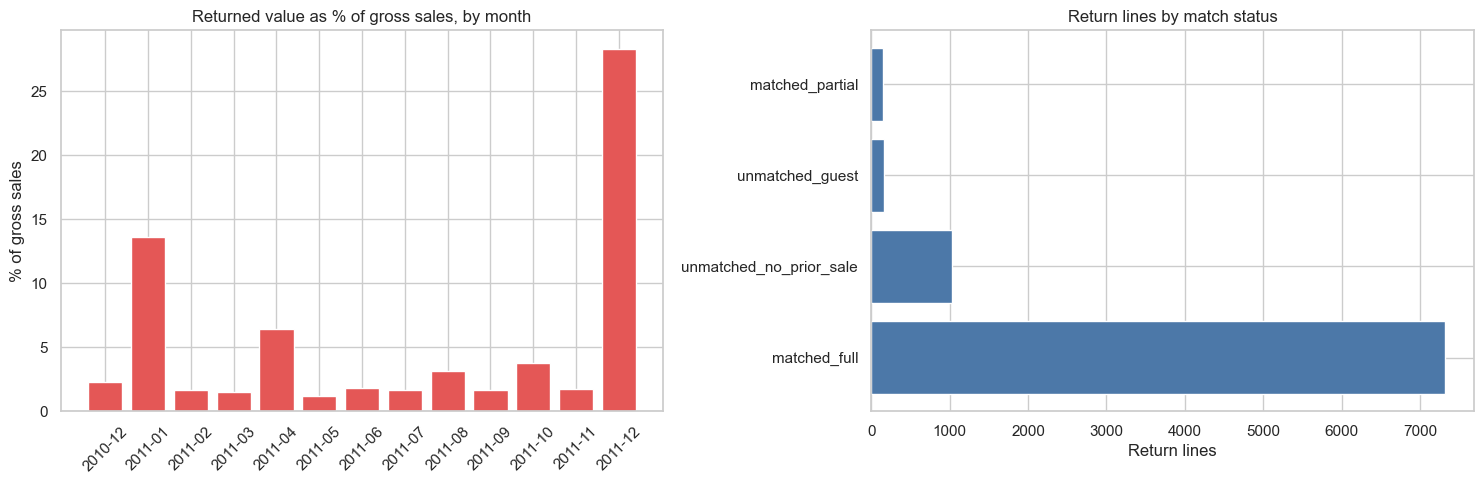

[Insight] Highest return month: 2011-12 (28.3% of that month's gross sales).
[Insight] 11.9% of return lines have no earlier sale in the data window (purchase pre-dates the dataset) and 1.9% are guest returns that cannot be matched.


In [11]:
# Returns over time and how well they can be matched to an earlier purchase
monthly_ret = pd.concat(
    {
        "Gross": sales.groupby("YearMonth")["TotalLineRevenue"].sum(),
        "Returned": -returns.groupby("YearMonth")["TotalLineRevenue"].sum(),
    },
    axis=1,
).fillna(0.0)
monthly_ret["Return_pct_of_gross"] = monthly_ret["Returned"] / monthly_ret["Gross"] * 100

match_counts = returns["ReturnMatch"].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].bar(monthly_ret.index.astype(str), monthly_ret["Return_pct_of_gross"], color="#E45756")
axes[0].set_title("Returned value as % of gross sales, by month")
axes[0].set_ylabel("% of gross sales")
axes[0].tick_params(axis="x", rotation=45)
axes[1].barh(match_counts.index, match_counts.values, color="#4C78A8")
axes[1].set_title("Return lines by match status")
axes[1].set_xlabel("Return lines")
finish_fig(fig, "07_returns")

peak_ret = monthly_ret["Return_pct_of_gross"].idxmax()
no_prior = match_counts.get("unmatched_no_prior_sale", 0) / match_counts.sum() * 100
guest_ret = match_counts.get("unmatched_guest", 0) / match_counts.sum() * 100
print(f"[Insight] Highest return month: {peak_ret} ({monthly_ret['Return_pct_of_gross'].max():.1f}% of that month's gross sales).")
print(f"[Insight] {no_prior:.1f}% of return lines have no earlier sale in the data window (purchase pre-dates the dataset) "
      f"and {guest_ret:.1f}% are guest returns that cannot be matched.")


## 7. Top products
Units leaders are often cheap items; revenue leaders carry the P&L.

> **Note — gross figures:** the rankings below are computed on *gross* sales lines (before netting returns). Two customers (16446 and 12346) placed very large orders that were subsequently cancelled in full; they inflate both the unit-leader (StockCode 23843 and 23166) and the top-10 customer rankings. The net-corrected values are used from Phase 2 onwards. Treat the top-units and top-customers charts here as gross-transaction patterns, not as final value statements.

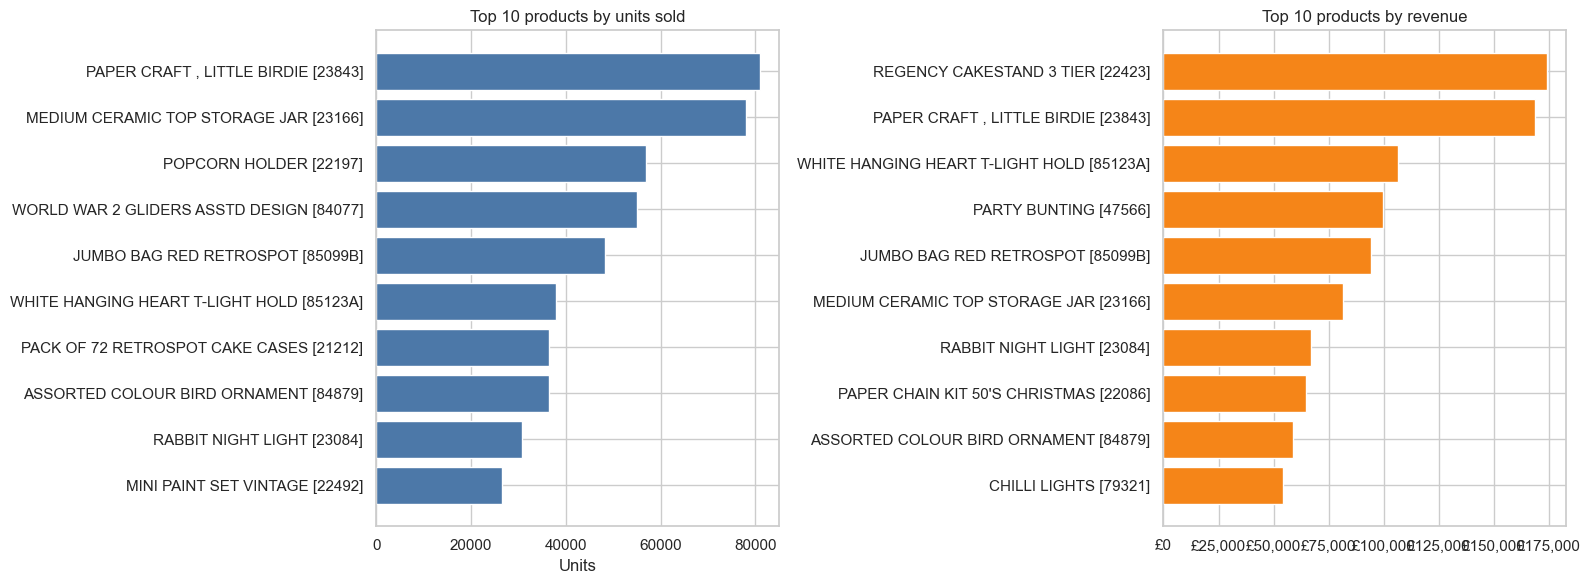

[Insight] 6 of the top 10 products by units are also top 10 by revenue: volume leaders are often cheap items; revenue leaders carry the P&L.


,units,revenue,n_invoices,Description,label
StockCode,,,,,
22423,13851,"174,156.54",1988,REGENCY CAKESTAND 3 TIER,REGENCY CAKESTAND 3 TIER [22423]
23843,80995,"168,469.60",1,"PAPER CRAFT , LITTLE BIRDIE","PAPER CRAFT , LITTLE BIRDIE [23843]"
85123A,37933,"106,415.23",2265,WHITE HANGING HEART T-LIGHT HOLDER,WHITE HANGING HEART T-LIGHT HOLD [85123A]
47566,18283,"99,445.23",1685,PARTY BUNTING,PARTY BUNTING [47566]
85099B,48371,"94,159.81",2089,JUMBO BAG RED RETROSPOT,JUMBO BAG RED RETROSPOT [85099B]
23166,78033,"81,700.92",247,MEDIUM CERAMIC TOP STORAGE JAR,MEDIUM CERAMIC TOP STORAGE JAR [23166]
23084,30739,"66,870.03",994,RABBIT NIGHT LIGHT,RABBIT NIGHT LIGHT [23084]
22086,19329,"64,875.59",1160,PAPER CHAIN KIT 50'S CHRISTMAS,PAPER CHAIN KIT 50'S CHRISTMAS [22086]
84879,36362,"58,927.62",1455,ASSORTED COLOUR BIRD ORNAMENT,ASSORTED COLOUR BIRD ORNAMENT [84879]


In [12]:
def eda_top_products(sales: pd.DataFrame, desc_map: pd.Series, n: int = 10) -> pd.DataFrame:
    """Which products drive units vs revenue? (They are often different products.)"""
    prod = sales.groupby("StockCode").agg(units=("Quantity", "sum"),
                                          revenue=("TotalLineRevenue", "sum"),
                                          n_invoices=("InvoiceNo", "nunique"))
    prod["Description"] = desc_map.reindex(prod.index).fillna("(no description)")
    prod["label"] = prod["Description"].str.slice(0, 32) + " [" + prod.index + "]"

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    top_u = prod.nlargest(n, "units").iloc[::-1]
    top_r = prod.nlargest(n, "revenue").iloc[::-1]
    axes[0].barh(top_u["label"], top_u["units"], color="#4C78A8")
    axes[0].set_title(f"Top {n} products by units sold")
    axes[0].set_xlabel("Units")
    axes[1].barh(top_r["label"], top_r["revenue"], color="#F58518")
    axes[1].set_title(f"Top {n} products by revenue")
    axes[1].xaxis.set_major_formatter(gbp)
    finish_fig(fig, "01_top_products")

    overlap = set(top_u.index) & set(top_r.index)
    print(f"[Insight] {len(overlap)} of the top {n} products by units are also top {n} by revenue: "
          "volume leaders are often cheap items; revenue leaders carry the P&L.")
    return prod


prod = eda_top_products(sales, desc_map)
prod.sort_values("revenue", ascending=False).head(10)

## 8. Monthly revenue trend & Q4 holiday surge
Net revenue = gross sales − returns. The final month is partial (data ends mid-December 2011) and is excluded from the Q4-lift comparison.

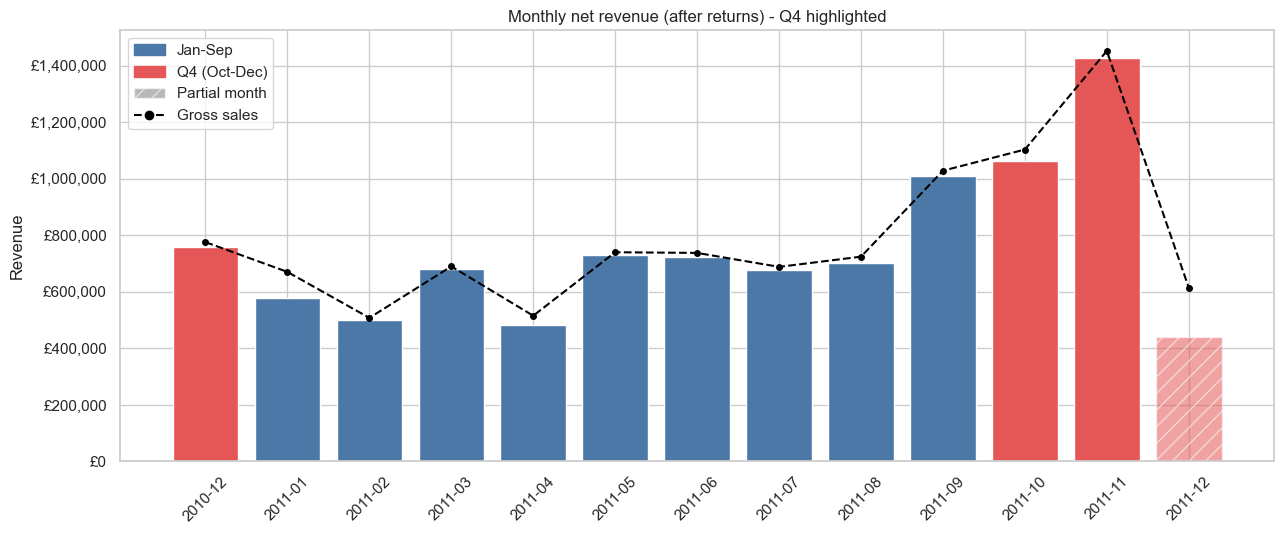

[Insight] Complete months only: avg Q4 month £1,082,305 vs avg non-Q4 month £676,000 -> Q4 lift = 1.60x
[Insight] Peak complete month: 2011-11 (£1,427,125). Partial final month 2011-12 excluded from comparisons: True.
[Caution] Dataset is only ~13 months, so seasonality is suggestive, not proven (one holiday season).


,Gross,Returns,Net,MoM_growth_%
YearMonth,,,,
2010-12,"775,638.36","-17,547.86","758,090.50",NaN
2011-01,"670,380.24","-91,525.05","578,855.19",-23.64
2011-02,"507,799.87","-8,335.52","499,464.35",-13.72
2011-03,"689,833.51","-10,504.30","679,329.21",36.01
2011-04,"515,377.99","-33,316.06","482,061.93",-29.04
2011-05,"739,953.00","-8,948.23","731,004.77",51.64
2011-06,"737,558.98","-13,713.84","723,845.14",-0.98
2011-07,"688,219.34","-11,407.26","676,812.08",-6.50
2011-08,"724,216.50","-22,926.57","701,289.93",3.62


In [13]:
def eda_monthly_revenue(sales: pd.DataFrame, returns: pd.DataFrame, last_date: pd.Timestamp) -> pd.DataFrame:
    """Macro trend: gross, returns and net revenue per month, with a Q4 holiday-surge test."""
    monthly = pd.concat({
        "Gross": sales.groupby("YearMonth")["TotalLineRevenue"].sum(),
        "Returns": returns.groupby("YearMonth")["TotalLineRevenue"].sum(),
    }, axis=1).fillna(0.0)
    monthly["Net"] = monthly["Gross"] + monthly["Returns"]          # returns are negative
    monthly["MoM_growth_%"] = monthly["Net"].pct_change() * 100

    # The final month is usually incomplete (data ends mid-month) - never compare it blindly.
    partial = last_date.day < last_date.days_in_month
    last_period = last_date.to_period("M")
    complete = monthly.index[monthly.index < last_period] if partial else monthly.index

    is_q4 = np.array([p.month in (10, 11, 12) for p in monthly.index])
    colors = np.where(is_q4, "#E45756", "#4C78A8")
    fig, ax = plt.subplots(figsize=(13, 5.5))
    bars = ax.bar(monthly.index.astype(str), monthly["Net"], color=colors)
    if partial:
        bars[-1].set_hatch("//")
        bars[-1].set_alpha(0.55)
    ax.plot(monthly.index.astype(str), monthly["Gross"], color="black", ls="--", marker="o", ms=4, label="Gross sales")
    ax.yaxis.set_major_formatter(gbp)
    ax.set_title("Monthly net revenue (after returns) - Q4 highlighted")
    ax.set_ylabel("Revenue")
    ax.tick_params(axis="x", rotation=45)
    ax.legend(handles=[Patch(color="#4C78A8", label="Jan-Sep"), Patch(color="#E45756", label="Q4 (Oct-Dec)"),
                       Patch(facecolor="grey", hatch="//", alpha=0.55, label="Partial month"),
                       plt.Line2D([], [], color="black", ls="--", marker="o", label="Gross sales")])
    finish_fig(fig, "02_monthly_revenue")

    comp = monthly.loc[complete]
    q4_mask = np.array([p.month in (10, 11, 12) for p in comp.index])
    q4_avg, base_avg = comp.loc[q4_mask, "Net"].mean(), comp.loc[~q4_mask, "Net"].mean()
    print(f"[Insight] Complete months only: avg Q4 month £{q4_avg:,.0f} vs avg non-Q4 month £{base_avg:,.0f} "
          f"-> Q4 lift = {q4_avg / base_avg:.2f}x")
    peak = comp["Net"].idxmax()
    print(f"[Insight] Peak complete month: {peak} (£{comp['Net'].max():,.0f}). "
          f"Partial final month {last_period} excluded from comparisons: {partial}.")
    print("[Caution] Dataset is only ~13 months, so seasonality is suggestive, not proven (one holiday season).")
    return monthly


monthly = eda_monthly_revenue(sales, returns, last_date)
monthly

## 9. Weekday & hour patterns
Useful for ad-spend timing and choosing maintenance windows.

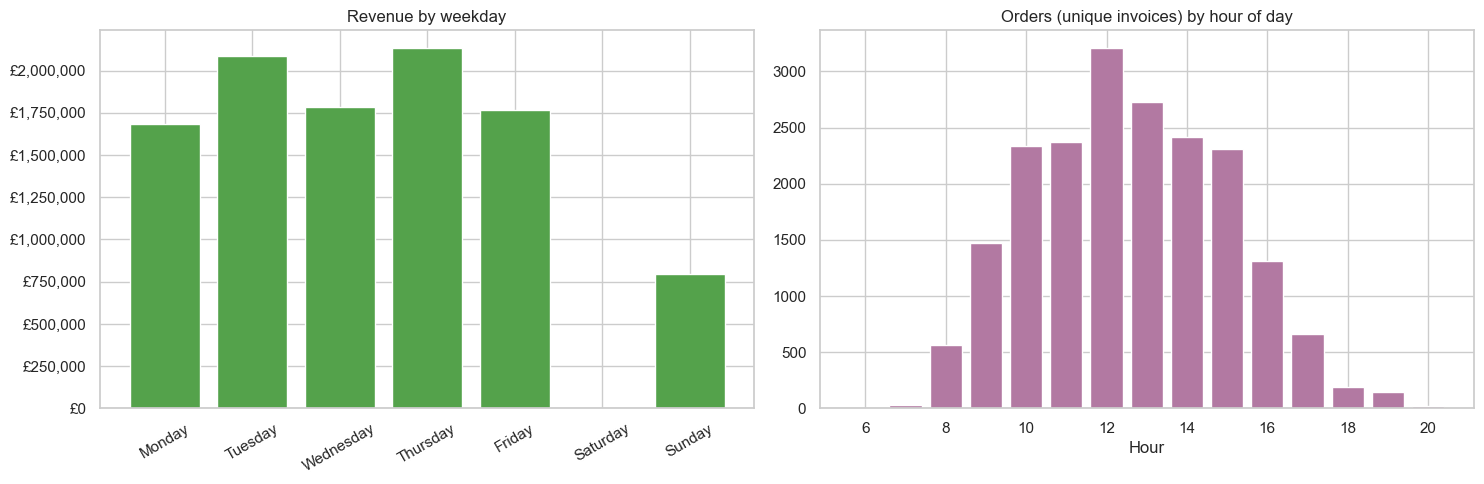

[Insight] Strongest weekday: Thursday; weekdays with zero trading in data: ['Saturday']
[Insight] Peak order hours: [12, 13, 14]. Quietest hours (best maintenance windows): [6, 20, 7]


In [14]:
def eda_weekday_hour(sales: pd.DataFrame) -> None:
    """Micro-timing: when do customers buy? Drives ad-spend timing and maintenance windows."""
    by_day = (sales.groupby("DayOfWeek").agg(revenue=("TotalLineRevenue", "sum"), invoices=("InvoiceNo", "nunique"))
              .reindex(DAY_ORDER).fillna(0))
    by_hour = sales.groupby("Hour").agg(revenue=("TotalLineRevenue", "sum"), invoices=("InvoiceNo", "nunique"))

    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    axes[0].bar(by_day.index, by_day["revenue"], color="#54A24B")
    axes[0].set_title("Revenue by weekday")
    axes[0].yaxis.set_major_formatter(gbp)
    axes[0].tick_params(axis="x", rotation=30)
    axes[1].bar(by_hour.index, by_hour["invoices"], color="#B279A2")
    axes[1].set_title("Orders (unique invoices) by hour of day")
    axes[1].set_xlabel("Hour")
    finish_fig(fig, "03_weekday_hour")

    print(f"[Insight] Strongest weekday: {by_day['revenue'].idxmax()}; "
          f"weekdays with zero trading in data: {list(by_day.index[by_day['revenue'] == 0])}")
    peak_hours = by_hour["invoices"].nlargest(3).index.tolist()
    quiet = by_hour["invoices"].nsmallest(3).index.tolist()
    print(f"[Insight] Peak order hours: {peak_hours}. Quietest hours (best maintenance windows): {quiet}")


eda_weekday_hour(sales)

## 10. Average Order Value & basket size
Invoices (orders) are rebuilt from lines. Mean vs median AOV and bulk-like baskets indicate wholesale behaviour.

[Insight] AOV mean £518.24 vs median £302.20 (mean/median = 1.7x -> right-skewed, bulk orders inflate the mean)
          Basket: median 152 units, 15 distinct products; p95 = 810 units
[Insight] Bulk-like baskets (>= 531 units): 10% of orders -> 45% of revenue (evidence of wholesale behaviour; heuristic, not a label).

AOV by market:
               count   mean  median
Is_UK                              
International   1872 813.45  385.28
UK             17901 487.37  299.67


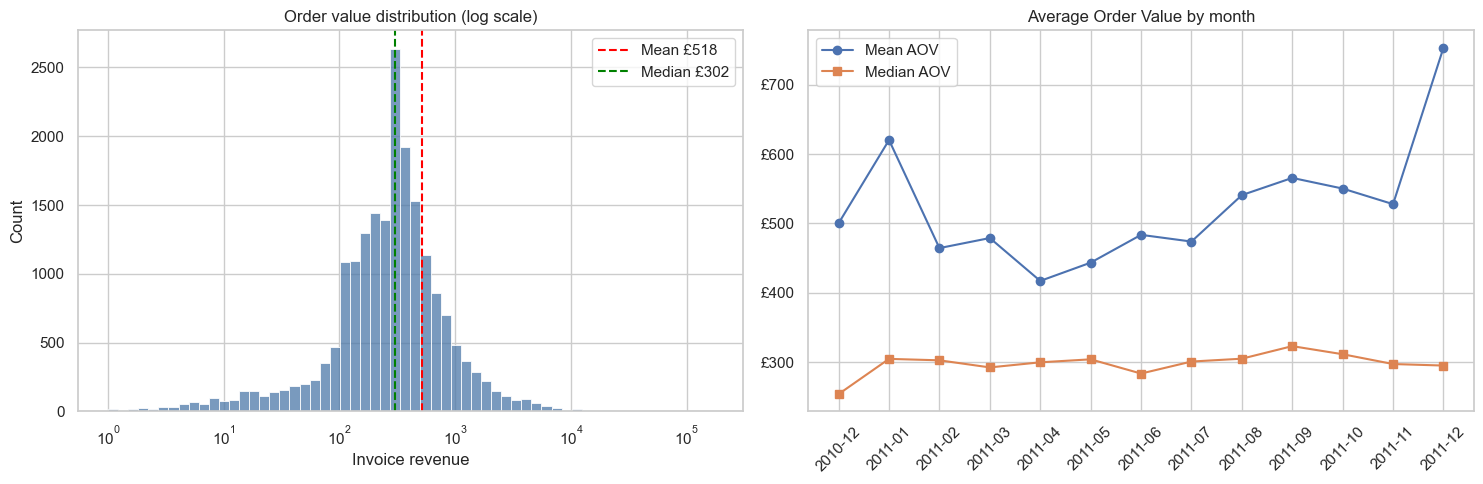

,InvoiceDate,Is_UK,InvoiceRevenue,BasketUnits,BasketLines
count,19773,"19,773.00","19,773.00","19,773.00","19,773.00"
mean,2011-06-29 05:22:56.006675712,0.91,518.24,281.26,26.16
min,2010-12-01 08:26:00,0.00,0.38,1.00,1.00
25%,2011-03-28 14:42:00,1.00,151.68,71.00,6.00
50%,2011-07-07 12:56:00,1.00,302.20,152.00,15.00
75%,2011-10-11 09:10:00,1.00,481.49,297.00,29.00
max,2011-12-09 12:50:00,1.00,"168,469.60","80,995.00","1,106.00"
std,NaN,0.29,"1,764.13",958.79,47.02


In [15]:
def build_invoice_table(sales: pd.DataFrame) -> pd.DataFrame:
    """Collapse lines to ORDERS: one row per invoice (basket)."""
    return sales.groupby("InvoiceNo").agg(
        InvoiceDate=("InvoiceDate", "min"),
        YearMonth=("YearMonth", "first"),
        CustomerID=("CustomerID", "first"),
        Country=("Country", "first"),
        Is_UK=("Is_UK", "first"),
        Is_Guest=("Is_Guest", "first"),
        InvoiceRevenue=("TotalLineRevenue", "sum"),
        BasketUnits=("Quantity", "sum"),
        BasketLines=("StockCode", "nunique"),
    )


def eda_aov(invoices: pd.DataFrame) -> pd.DataFrame:
    """AOV, basket size and a wholesale-vs-retail heuristic."""
    aov_mean, aov_med = invoices["InvoiceRevenue"].mean(), invoices["InvoiceRevenue"].median()
    print(f"[Insight] AOV mean £{aov_mean:,.2f} vs median £{aov_med:,.2f} "
          f"(mean/median = {aov_mean / aov_med:.1f}x -> right-skewed, bulk orders inflate the mean)")
    print(f"          Basket: median {invoices['BasketUnits'].median():.0f} units, "
          f"{invoices['BasketLines'].median():.0f} distinct products; "
          f"p95 = {invoices['BasketUnits'].quantile(.95):.0f} units")

    thr = invoices["BasketUnits"].quantile(BULK_BASKET_QUANTILE)
    invoices["Bulk_Like"] = invoices["BasketUnits"] >= thr
    share_inv = invoices["Bulk_Like"].mean() * 100
    share_rev = invoices.loc[invoices["Bulk_Like"], "InvoiceRevenue"].sum() / invoices["InvoiceRevenue"].sum() * 100
    print(f"[Insight] Bulk-like baskets (>= {thr:.0f} units): {share_inv:.0f}% of orders -> {share_rev:.0f}% of revenue "
          "(evidence of wholesale behaviour; heuristic, not a label).")

    seg = invoices.groupby("Is_UK")["InvoiceRevenue"].agg(["count", "mean", "median"])
    seg.index = seg.index.map({1: "UK", 0: "International"})
    print("\nAOV by market:")
    print(seg)

    monthly_aov = invoices.groupby("YearMonth")["InvoiceRevenue"].agg(["mean", "median"])
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    sns.histplot(invoices["InvoiceRevenue"].clip(lower=1), bins=60, log_scale=True, color="#4C78A8", ax=axes[0])
    axes[0].axvline(aov_mean, color="red", ls="--", label=f"Mean £{aov_mean:,.0f}")
    axes[0].axvline(aov_med, color="green", ls="--", label=f"Median £{aov_med:,.0f}")
    axes[0].set_title("Order value distribution (log scale)")
    axes[0].set_xlabel("Invoice revenue")
    axes[0].legend()
    axes[1].plot(monthly_aov.index.astype(str), monthly_aov["mean"], marker="o", label="Mean AOV")
    axes[1].plot(monthly_aov.index.astype(str), monthly_aov["median"], marker="s", label="Median AOV")
    axes[1].yaxis.set_major_formatter(gbp)
    axes[1].set_title("Average Order Value by month")
    axes[1].tick_params(axis="x", rotation=45)
    axes[1].legend()
    finish_fig(fig, "04_aov")
    return monthly_aov


invoices = build_invoice_table(sales)
monthly_aov = eda_aov(invoices)
invoices.describe()

## 11. Pareto principle (80/20) on StockCodes

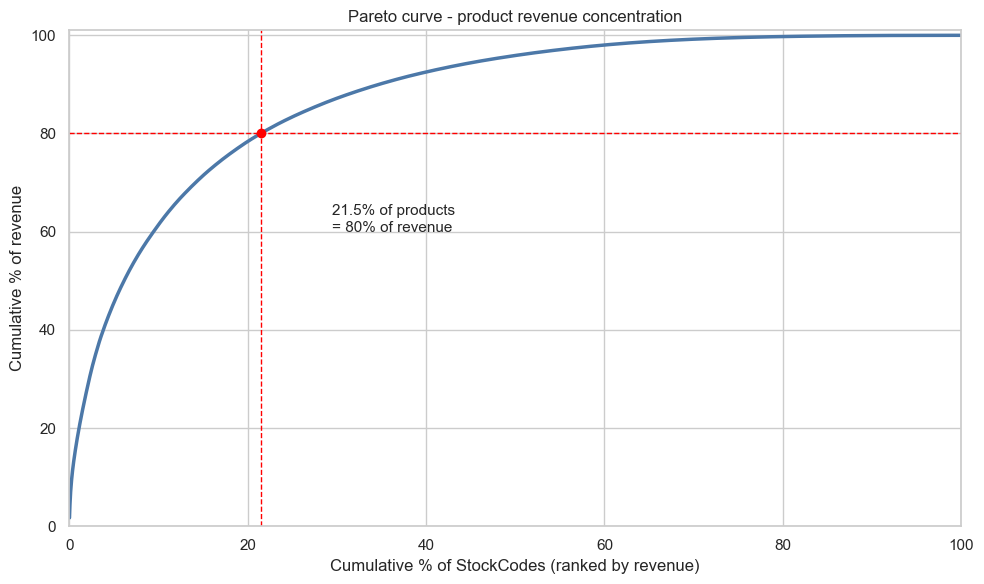

[Insight] 816 of 3,798 products (21.5%) generate 80% of revenue; the top 20% generate 78.4%.
          Concentration is weaker than the classic 80/20 rule -> range rationalisation and hero-product inventory priorities.


In [16]:
def eda_pareto(sales: pd.DataFrame) -> pd.Series:
    """Pareto test: what share of StockCodes produces 80% of revenue?"""
    prod_rev = sales.groupby("StockCode")["TotalLineRevenue"].sum().sort_values(ascending=False)
    n = len(prod_rev)
    cum_share = prod_rev.cumsum() / prod_rev.sum()
    x = np.arange(1, n + 1) / n * 100

    n80 = int((cum_share < 0.80).sum() + 1)
    pct_products_80 = n80 / n * 100
    top20_share = cum_share.iloc[int(np.ceil(0.20 * n)) - 1] * 100

    fig, ax = plt.subplots(figsize=(10, 6))
    ax.plot(x, cum_share.values * 100, color="#4C78A8", lw=2.5)
    ax.axhline(80, color="red", ls="--", lw=1)
    ax.axvline(pct_products_80, color="red", ls="--", lw=1)
    ax.scatter([pct_products_80], [80], color="red", zorder=5)
    ax.annotate(f"{pct_products_80:.1f}% of products\n= 80% of revenue",
                (pct_products_80, 80), xytext=(pct_products_80 + 8, 60),
                arrowprops=dict(arrowstyle="->"), fontsize=11)
    ax.set_xlabel("Cumulative % of StockCodes (ranked by revenue)")
    ax.set_ylabel("Cumulative % of revenue")
    ax.set_title("Pareto curve - product revenue concentration")
    ax.set_xlim(0, 100)
    ax.set_ylim(0, 101)
    finish_fig(fig, "05_pareto")

    print(f"[Insight] {n80:,} of {n:,} products ({pct_products_80:.1f}%) generate 80% of revenue; "
          f"the top 20% generate {top20_share:.1f}%.")
    verdict = "stronger" if pct_products_80 < 20 else "weaker"
    print(f"          Concentration is {verdict} than the classic 80/20 rule -> range rationalisation and "
          "hero-product inventory priorities.")
    return cum_share


cum_share = eda_pareto(sales)

## 12. Dead-stock identification
High historical volume (top quartile) but **zero or negative net sales** in the final 90 days. Products with a strong Q4 pattern are flagged as likely seasonal, not dead.

DEAD STOCK
Window: 2011-09-10 -> 2011-12-09 | high-volume threshold: >= 904 historical units
Products flagged: 20 of 3,570 historically active (0.6%) | historical revenue tied to them: £40,456
Of which likely seasonal (>=60% of units in Q4): 2
                                   Description  hist_units  hist_revenue           last_sale  days_since_last_sale  q4_unit_share  likely_seasonal
StockCode                                                                                                                                         
47556B                     TEA TIME TEA TOWELS        2600      6,045.00 2011-04-18 13:20:00                   234           0.00            False
22088              PAPER BUNTING COLOURED LACE        1893      5,661.05 2011-07-06 10:41:00                   156           0.03            False
21033          JUMBO BAG CHARLIE AND LOLA TOYS        1932      4,851.73 2011-09-08 13:53:00                    91           0.04            False
85132C           CHAR

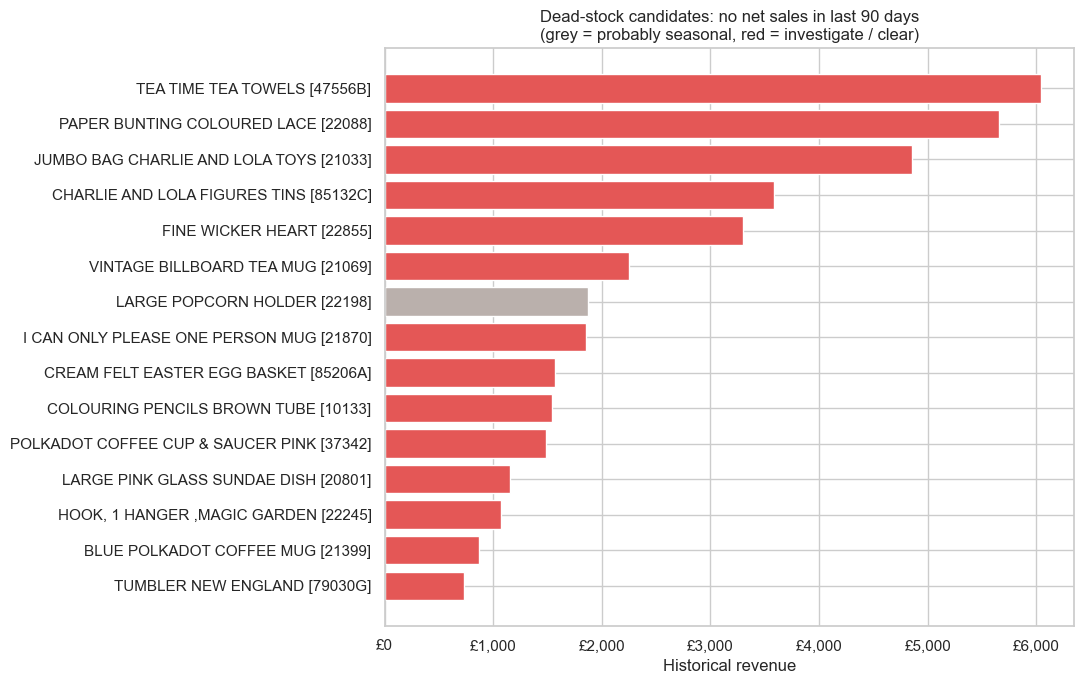

In [17]:
def eda_dead_stock(sales: pd.DataFrame, returns: pd.DataFrame, desc_map: pd.Series,
                   last_date: pd.Timestamp) -> pd.DataFrame:
    """
    Dead stock = products with HIGH historical volume (top quartile of units before the
    window) whose NET units sold (sales - returns) in the final 90 days are <= 0.
    Seasonality flag: products with most units sold in Q4 may be resting, not dead.
    """
    cutoff = last_date - pd.Timedelta(days=DEAD_STOCK_WINDOW_DAYS)
    hist = sales[sales["InvoiceDate"] <= cutoff]
    recent_sales = sales[sales["InvoiceDate"] > cutoff]
    recent_returns = returns[returns["InvoiceDate"] > cutoff]

    stats = hist.groupby("StockCode").agg(hist_units=("Quantity", "sum"),
                                          hist_revenue=("TotalLineRevenue", "sum"),
                                          first_sale=("InvoiceDate", "min"),
                                          last_sale=("InvoiceDate", "max"))
    q4_units = hist[hist["Month"].isin([10, 11, 12])].groupby("StockCode")["Quantity"].sum()
    stats["q4_unit_share"] = (q4_units.reindex(stats.index).fillna(0) / stats["hist_units"])

    recent_net = (pd.concat([recent_sales, recent_returns]).groupby("StockCode")["Quantity"].sum()
                  .reindex(stats.index).fillna(0))
    stats["recent_net_units"] = recent_net

    threshold = stats["hist_units"].quantile(HIGH_VOLUME_QUANTILE)
    dead = stats[(stats["hist_units"] >= threshold) & (stats["recent_net_units"] <= 0)].copy()
    dead["Description"] = desc_map.reindex(dead.index).fillna("(no description)")
    dead["days_since_last_sale"] = (last_date - dead["last_sale"]).dt.days
    dead["likely_seasonal"] = dead["q4_unit_share"] >= 0.60
    dead = dead.sort_values("hist_revenue", ascending=False)

    print("=" * 80, "\nDEAD STOCK\n", "=" * 80, sep="")
    print(f"Window: {cutoff.date()} -> {last_date.date()} | high-volume threshold: >= {threshold:,.0f} historical units")
    print(f"Products flagged: {len(dead):,} of {len(stats):,} historically active "
          f"({len(dead) / len(stats) * 100:.1f}%) | historical revenue tied to them: £{dead['hist_revenue'].sum():,.0f}")
    print(f"Of which likely seasonal (>=60% of units in Q4): {int(dead['likely_seasonal'].sum())}")
    print(dead[["Description", "hist_units", "hist_revenue", "last_sale", "days_since_last_sale",
                "q4_unit_share", "likely_seasonal"]].head(20))

    if len(dead):
        top = dead.head(15).iloc[::-1]
        fig, ax = plt.subplots(figsize=(11, 7))
        ax.barh(top["Description"].str.slice(0, 35) + " [" + top.index + "]", top["hist_revenue"],
                color=np.where(top["likely_seasonal"], "#BAB0AC", "#E45756"))
        ax.xaxis.set_major_formatter(gbp)
        ax.set_title(f"Dead-stock candidates: no net sales in last {DEAD_STOCK_WINDOW_DAYS} days\n"
                     "(grey = probably seasonal, red = investigate / clear)")
        ax.set_xlabel("Historical revenue")
        finish_fig(fig, "06_dead_stock")
    return dead


dead = eda_dead_stock(sales, returns, desc_map, last_date)

## 12A. Customer value analysis
Identify customers contributing the most revenue and orders.

> **Note — gross figures:** the revenue and order counts here are gross (pre-return). Customers 16446 (≈ £168 k gross, net ≈ £2.9 k) and 12346 (≈ £77 k gross, net ≈ £0) appear in the top-10 due to large orders that were fully cancelled. Consequently the overall return rate shown in § 6 (~4.64 %) is also inflated relative to the true figure (~2.3 % when those two transactions are excluded). Net-corrected Monetary values are computed in Phase 2 and used as the clustering basis.

In [18]:

customer_summary = (
    sales.groupby('CustomerID', dropna=True)
    .agg(TotalRevenue=('TotalLineRevenue','sum'),
         Orders=('InvoiceNo','nunique'))
    .sort_values('TotalRevenue', ascending=False)
)
print('Top 10 Customers by Revenue')
display(customer_summary.head(10))

print('Top 10 Customers by Orders')
display(customer_summary.sort_values('Orders', ascending=False).head(10))


Top 10 Customers by Revenue


,TotalRevenue,Orders
CustomerID,,
14646,"279,138.02",72
18102,"259,657.30",60
17450,"194,390.79",46
16446,"168,472.50",2
14911,"136,161.83",198
12415,"124,564.53",20
14156,"116,560.08",54
17511,"91,062.38",31
12346,"77,183.60",1


Top 10 Customers by Orders


,TotalRevenue,Orders
CustomerID,,
12748,"31,650.78",206
14911,"136,161.83",198
17841,"40,495.99",124
13089,"58,762.08",97
15311,"60,632.75",91
14606,"11,926.15",90
12971,"11,189.91",86
14646,"279,138.02",72
13408,"28,117.04",62


### Customer Analysis Interpretation
This analysis identifies the customers generating the highest revenue and order volume. These customers are important candidates for retention, loyalty programs, and lifetime-value analysis.

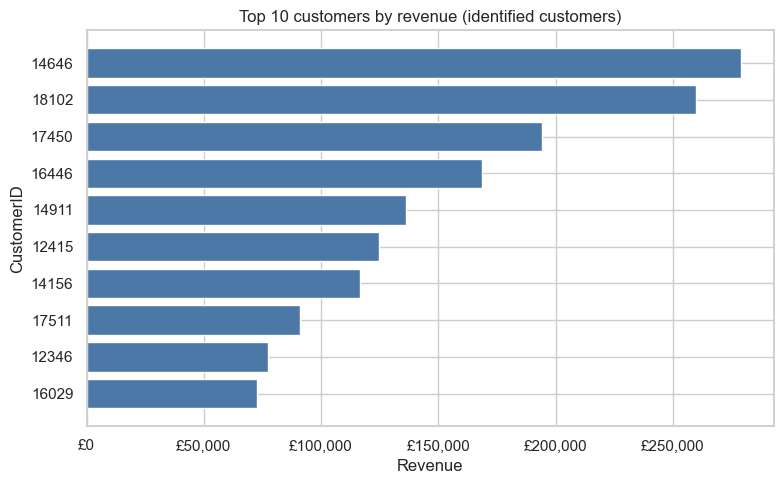

In [19]:
# Customer revenue visualisation (identified customers only; guests are reported in §4)
top_customers = customer_summary.head(10).sort_values("TotalRevenue")
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top_customers.index.astype(str), top_customers["TotalRevenue"], color="#4C78A8")
ax.xaxis.set_major_formatter(gbp)
ax.set_title("Top 10 customers by revenue (identified customers)")
ax.set_xlabel("Revenue")
ax.set_ylabel("CustomerID")
finish_fig(fig, "08_top_customers")


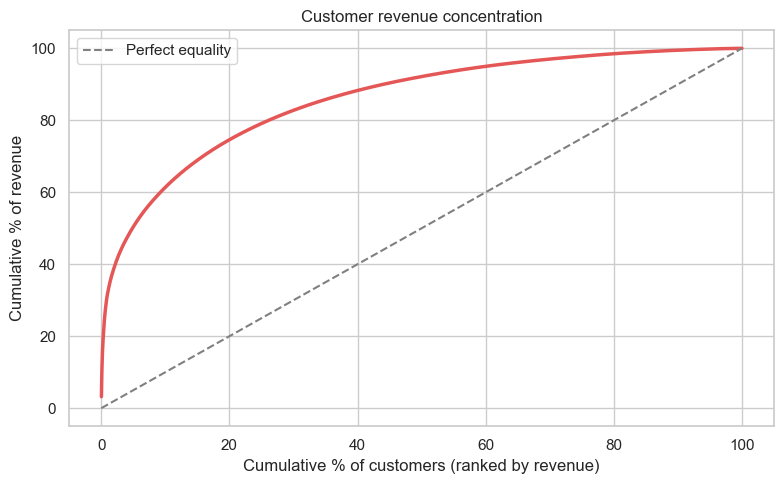

[Insight] Top 10 customers = 17.4% of identified-customer revenue.
[Insight] Top 1% of customers = 32.2% | top 10% = 61.4% | top 20% = 74.6% of revenue.
[Insight] Top 10% of customers by orders place 43.4% of all orders.
[Insight] Median customer revenue £663 vs mean £2,016 (mean/median = 3.0x -> a few wholesale-like accounts pull the mean up).


In [20]:
# How concentrated is revenue among customers? (data-driven interpretation)
cs = customer_summary["TotalRevenue"].sort_values(ascending=False)
co = customer_summary["Orders"].sort_values(ascending=False)
n_c, tot_rev, tot_ord = len(cs), cs.sum(), co.sum()


def top_share(series, total, frac):
    k = max(1, int(np.ceil(len(series) * frac)))
    return series.head(k).sum() / total * 100


x = np.arange(1, n_c + 1) / n_c * 100
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(x, cs.cumsum().values / tot_rev * 100, color="#E45756", lw=2.5)
ax.plot([0, 100], [0, 100], ls="--", color="grey", label="Perfect equality")
ax.set_xlabel("Cumulative % of customers (ranked by revenue)")
ax.set_ylabel("Cumulative % of revenue")
ax.set_title("Customer revenue concentration")
ax.legend()
finish_fig(fig, "08b_customer_concentration")

print(f"[Insight] Top 10 customers = {cs.head(10).sum() / tot_rev * 100:.1f}% of identified-customer revenue.")
print(f"[Insight] Top 1% of customers = {top_share(cs, tot_rev, 0.01):.1f}% | top 10% = {top_share(cs, tot_rev, 0.10):.1f}% "
      f"| top 20% = {top_share(cs, tot_rev, 0.20):.1f}% of revenue.")
print(f"[Insight] Top 10% of customers by orders place {top_share(co, tot_ord, 0.10):.1f}% of all orders.")
print(f"[Insight] Median customer revenue £{cs.median():,.0f} vs mean £{cs.mean():,.0f} "
      f"(mean/median = {cs.mean() / cs.median():.1f}x -> a few wholesale-like accounts pull the mean up).")


### Customer Revenue Chart Interpretation
The chart highlights revenue concentration among the highest-value customers. If a small number of customers generate a large share of revenue, retention strategies become especially important.

## 12B. Geographic analysis
Countries by revenue, customers and orders.

In [21]:

country_summary = (
    sales.groupby('Country')
    .agg(Revenue=('TotalLineRevenue','sum'),
         Customers=('CustomerID','nunique'),
         Orders=('InvoiceNo','nunique'))
    .sort_values('Revenue', ascending=False)
)
display(country_summary.head(15))


,Revenue,Customers,Orders
Country,,,
United Kingdom,"8,724,443.67",3916,17901
Netherlands,"283,889.34",9,93
EIRE,"270,850.86",3,282
Germany,"205,381.15",94,443
France,"184,493.00",87,382
Australia,"138,103.81",9,56
Spain,"55,706.56",30,88
Switzerland,"53,065.60",21,50
Japan,"37,416.37",8,19


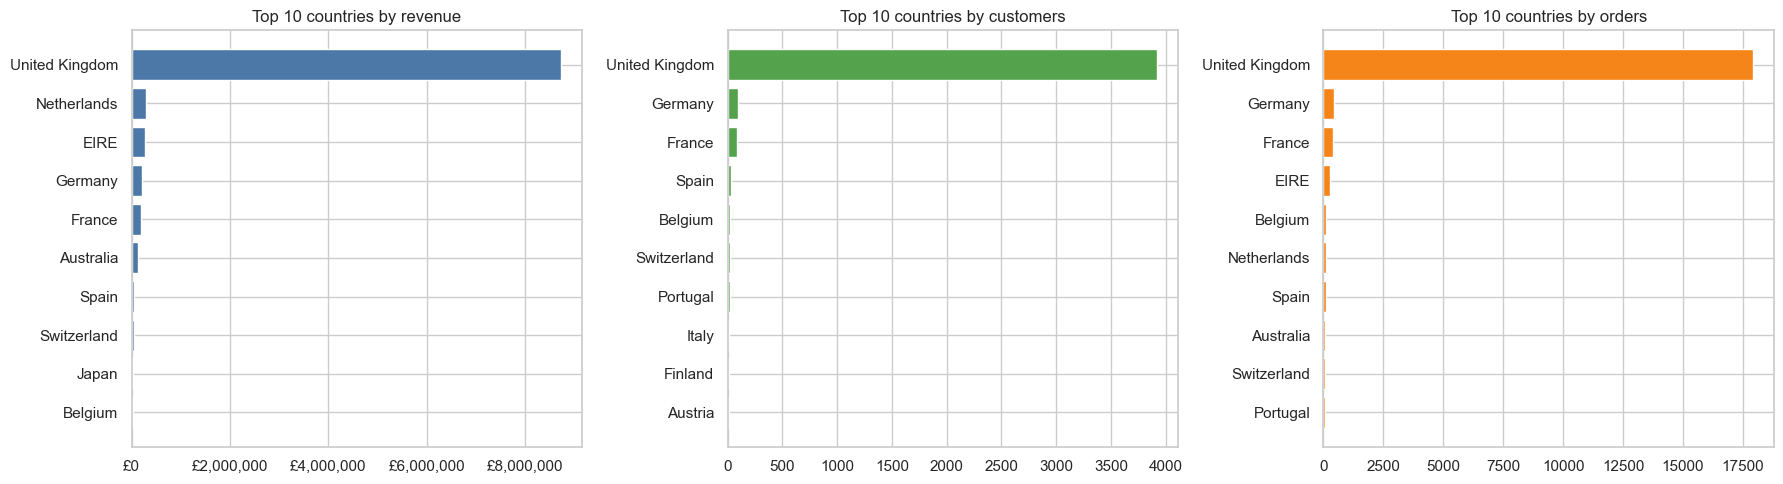

In [22]:
# Countries by revenue, customers and orders (three separate rankings: they are not the same list)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col, color in zip(axes, ["Revenue", "Customers", "Orders"], ["#4C78A8", "#54A24B", "#F58518"]):
    top = country_summary[col].nlargest(10).iloc[::-1]
    ax.barh(top.index, top.values, color=color)
    ax.set_title(f"Top 10 countries by {col.lower()}")
    if col == "Revenue":
        ax.xaxis.set_major_formatter(gbp)
finish_fig(fig, "09_country_rankings")


,Revenue,Customers,Orders,AOV,Revenue_pct
International,"1,522,775.65",418,1872,813.45,14.86
UK,"8,724,443.67",3916,17901,487.37,85.14


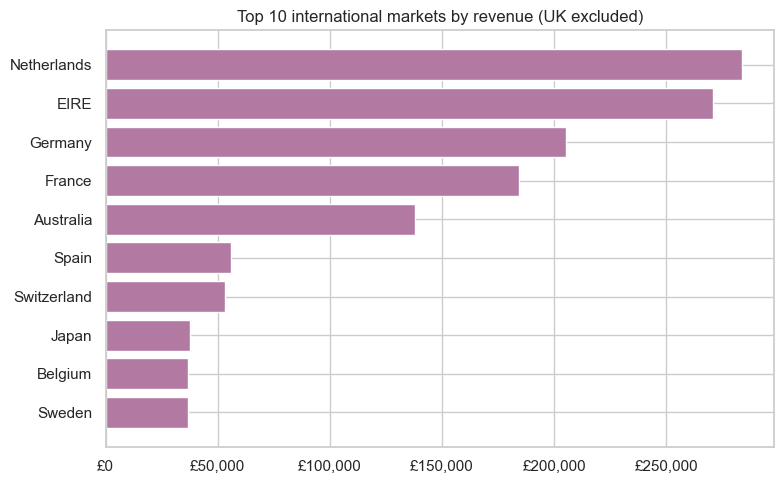

[Insight] UK = 85.1% of gross sales revenue; largest export market: Netherlands (£283,889, 18.6% of international revenue).
[Note] Customer counts exclude guest lines (no CustomerID).


In [23]:
# UK vs International (Is_UK flag) - isolates export trends from the UK skew
market = np.where(sales["Is_UK"] == 1, "UK", "International")
mk = sales.groupby(market).agg(Revenue=("TotalLineRevenue", "sum"),
                               Customers=("CustomerID", "nunique"),
                               Orders=("InvoiceNo", "nunique"))
mk["AOV"] = mk["Revenue"] / mk["Orders"]
mk["Revenue_pct"] = mk["Revenue"] / mk["Revenue"].sum() * 100
display(mk)

intl = country_summary.drop(index="United Kingdom", errors="ignore")
top_intl = intl["Revenue"].nlargest(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top_intl.index, top_intl.values, color="#B279A2")
ax.xaxis.set_major_formatter(gbp)
ax.set_title("Top 10 international markets by revenue (UK excluded)")
finish_fig(fig, "09b_international_revenue")

best = intl["Revenue"].idxmax()
print(f"[Insight] UK = {mk.loc['UK', 'Revenue_pct']:.1f}% of gross sales revenue; "
      f"largest export market: {best} (£{intl.loc[best, 'Revenue']:,.0f}, "
      f"{intl.loc[best, 'Revenue'] / intl['Revenue'].sum() * 100:.1f}% of international revenue).")
print("[Note] Customer counts exclude guest lines (no CustomerID).")


### Country Revenue Chart Interpretation
This visualization shows which markets contribute the most revenue. It helps prioritize international expansion, marketing investment, and customer acquisition efforts.

### Geographic Analysis Interpretation
Comparing countries by revenue, customers, and orders helps reveal market concentration and international growth opportunities.

## 12C. Outlier investigation
Study extreme wholesale behaviour before clustering.

In [24]:

for col in ['Quantity','UnitPrice','TotalLineRevenue']:
    print(f'\n{col} percentiles')
    display(sales[col].quantile([0.5,0.9,0.95,0.99,0.995,1.0]).to_frame('value'))



Quantity percentiles


,value
0.50,4.00
0.90,24.00
0.95,30.00
0.99,100.00
0.99,160.00
1.00,"80,995.00"



UnitPrice percentiles


,value
0.50,2.08
0.90,7.62
0.95,9.95
0.99,16.63
0.99,19.96
1.00,649.50



TotalLineRevenue percentiles


,value
0.50,9.90
0.90,31.80
0.95,59.40
0.99,179.00
0.99,275.00
1.00,"168,469.60"


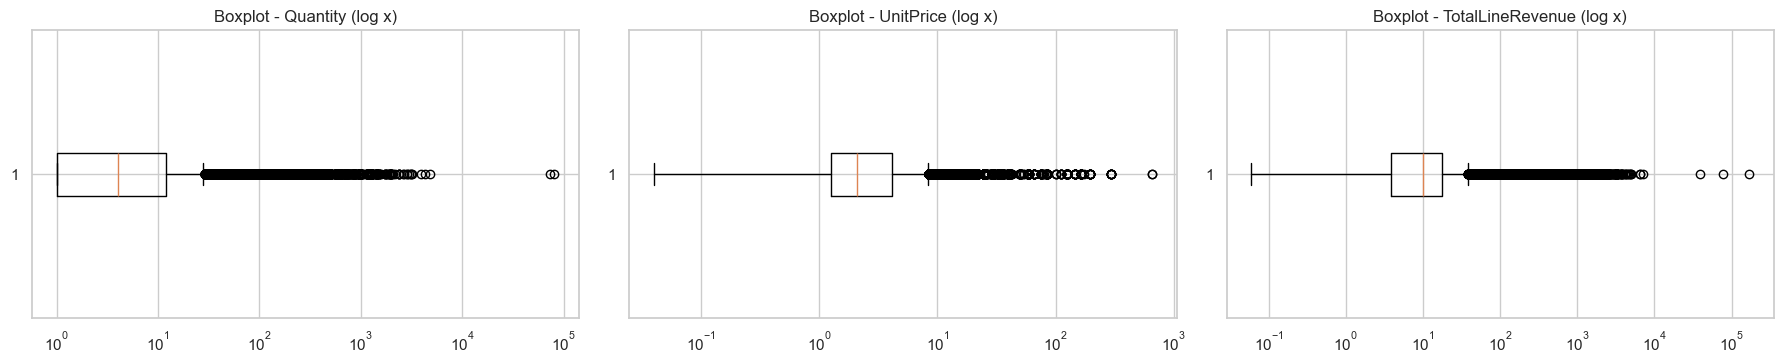

In [25]:
# Outlier visualisation (log x-axis because the tails are extreme)
fig, axes = plt.subplots(1, 3, figsize=(18, 3.8))
for ax, col in zip(axes, ["Quantity", "UnitPrice", "TotalLineRevenue"]):
    ax.boxplot(sales[col].dropna(), vert=False)
    ax.set_xscale("log")
    ax.set_title(f"Boxplot - {col} (log x)")
finish_fig(fig, "09c_outlier_boxplots")


In [26]:
# The most extreme lines: wholesale, data-entry error, or order-then-cancel?
cols = ["InvoiceNo", "InvoiceDate", "StockCode", "Description", "Quantity", "UnitPrice",
        "TotalLineRevenue", "CustomerID", "Country"]
extreme = sales.nlargest(10, "TotalLineRevenue")[cols].copy()
ret_keys = set(zip(returns["CustomerID"].astype(str), returns["StockCode"].astype(str)))
extreme["same_item_returned_by_customer"] = [
    (str(c), str(s)) in ret_keys for c, s in zip(extreme["CustomerID"], extreme["StockCode"])
]
display(extreme)

line_rev = sales["TotalLineRevenue"]
thr99 = line_rev.quantile(0.99)
print(f"[Insight] p99 line revenue £{thr99:,.0f} vs median £{line_rev.median():,.0f} "
      f"({thr99 / line_rev.median():.0f}x). Lines above p99 carry {line_rev[line_rev >= thr99].sum() / line_rev.sum() * 100:.1f}% of line revenue.")
print(f"[Insight] {int(extreme['same_item_returned_by_customer'].sum())} of the 10 largest lines have a return of the same item by the same customer -> "
      "candidates for order-then-cancel; net revenue (not gross) is therefore the safer Monetary basis.")


,InvoiceNo,InvoiceDate,StockCode,Description,Quantity,UnitPrice,TotalLineRevenue,CustomerID,Country,same_item_returned_by_customer
535160,581483,2011-12-09 09:15:00,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,"168,469.60",16446,United Kingdom,True
61006,541431,2011-01-18 10:01:00,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,"77,183.60",12346,United Kingdom,True
220825,556444,2011-06-10 15:28:00,22502,PICNIC BASKET WICKER 60 PIECES,60,649.50,"38,970.00",15098,United Kingdom,True
345627,567423,2011-09-20 11:05:00,23243,SET OF TEA COFFEE SUGAR TINS PANTRY,1412,5.06,"7,144.72",17450,United Kingdom,False
52169,540815,2011-01-11 12:55:00,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,"6,539.40",15749,United Kingdom,True
159101,550461,2011-04-18 13:20:00,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,"6,539.40",15749,United Kingdom,True
418088,573003,2011-10-27 12:11:00,23084,RABBIT NIGHT LIGHT,2400,2.08,"4,992.00",14646,Netherlands,False
52167,540815,2011-01-11 12:55:00,85123A,WHITE HANGING HEART T-LIGHT HOLDER,1930,2.55,"4,921.50",15749,United Kingdom,True
463639,576365,2011-11-14 17:55:00,22086,PAPER CHAIN KIT 50'S CHRISTMAS,688,6.95,"4,781.60",<NA>,United Kingdom,False
159097,550461,2011-04-18 13:20:00,85123A,WHITE HANGING HEART T-LIGHT HOLDER,1930,2.40,"4,632.00",15749,United Kingdom,True


[Insight] p99 line revenue £179 vs median £10 (18x). Lines above p99 carry 25.1% of line revenue.
[Insight] 7 of the 10 largest lines have a return of the same item by the same customer -> candidates for order-then-cancel; net revenue (not gross) is therefore the safer Monetary basis.


### Boxplot Interpretation
Boxplots provide a visual summary of the distribution and highlight extreme observations. These observations may correspond to wholesale transactions and should be investigated before clustering decisions are made.

### Outlier Interpretation
Extreme values may represent wholesale buyers, data-entry issues, or exceptional transactions. We investigate them rather than automatically removing them.

## 12D. Seasonality analysis
Revenue distribution by month.

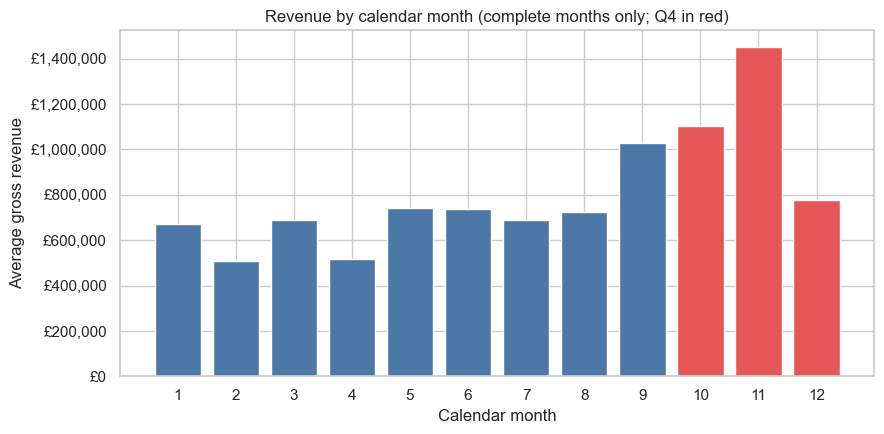

[Insight] Strongest calendar month: 11 (£1,452,116); weakest: 2 (£507,800).
[Insight] Oct-Dec account for 34.6% of the monthly revenue profile.
[Caution] Partial final month excluded: True (2011-12). The data covers about one annual cycle, so seasonality is suggestive, not proven.


In [27]:
# Seasonality: average revenue per calendar month over COMPLETE months only
last_period = last_date.to_period("M")
partial_last = last_date.day < last_date.days_in_month
m_rev = sales.groupby("YearMonth")["TotalLineRevenue"].sum()
m_complete = m_rev[m_rev.index < last_period] if partial_last else m_rev
by_calendar_month = m_complete.groupby(m_complete.index.month).mean()

colors = ["#E45756" if mth in (10, 11, 12) else "#4C78A8" for mth in by_calendar_month.index]
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(by_calendar_month.index.astype(str), by_calendar_month.values, color=colors)
ax.yaxis.set_major_formatter(gbp)
ax.set_xlabel("Calendar month")
ax.set_ylabel("Average gross revenue")
ax.set_title("Revenue by calendar month (complete months only; Q4 in red)")
finish_fig(fig, "09d_seasonality")

q4_share = by_calendar_month.loc[[10, 11, 12]].sum() / by_calendar_month.sum() * 100 if {10, 11, 12} <= set(by_calendar_month.index) else float("nan")
print(f"[Insight] Strongest calendar month: {int(by_calendar_month.idxmax())} (£{by_calendar_month.max():,.0f}); "
      f"weakest: {int(by_calendar_month.idxmin())} (£{by_calendar_month.min():,.0f}).")
print(f"[Insight] Oct-Dec account for {q4_share:.1f}% of the monthly revenue profile.")
print(f"[Caution] Partial final month excluded: {partial_last} ({last_period}). "
      "The data covers about one annual cycle, so seasonality is suggestive, not proven.")


### Seasonality Interpretation
Monthly revenue distribution helps identify seasonal demand patterns and periods of unusually high or low customer activity.

## 13. Save clean tables for Phase 2 (RFM & clustering)

In [28]:
def save_tables(tables: dict[str, pd.DataFrame]) -> None:
    """Parquet if available (keeps dtypes), otherwise gzipped CSV. Period cols saved as text."""
    PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
    for name, tbl in tables.items():
        out = tbl.copy()
        for col in out.columns:
            if isinstance(out[col].dtype, pd.PeriodDtype):
                out[col] = out[col].astype(str)
        try:
            out.to_parquet(PROCESSED_DIR / f"{name}.parquet", index=name == "invoices")
        except Exception:
            out.to_csv(PROCESSED_DIR / f"{name}.csv.gz", index=name == "invoices")
    print(f"\nSaved {list(tables)} to {PROCESSED_DIR}/")


save_tables({"sales": sales, "returns": returns, "excluded": excluded,
             "invoices": invoices, "dead_stock": dead})


Saved ['sales', 'returns', 'excluded', 'invoices', 'dead_stock'] to d:\NTI\NTI 2026\17\project\final\data\processed/


## 14. Business Insights & Limitations

The notebook should report **data-derived** insights rather than hard-coded claims. Run the cell below after EDA to print 10+ measurable business findings.


### Data-Backed Business Insights


In [29]:
# 12+ evidence-based insights generated directly from the cleaned data.
top_product_revenue = prod.iloc[prod["revenue"].argmax()]
top_product_units = prod.iloc[prod["units"].argmax()]
top_customer = customer_summary.iloc[0]
top_country = country_summary.iloc[0]
uk_share = sales["Is_UK"].mean() * 100
guest_share = sales["CustomerID"].isna().mean() * 100
return_value = -returns["TotalLineRevenue"].sum()
gross_sales = sales["TotalLineRevenue"].sum()
bulk_threshold = invoices["BasketUnits"].quantile(BULK_BASKET_QUANTILE)
bulk_mask = invoices["BasketUnits"] >= bulk_threshold

complete_months = monthly.index[monthly.index < last_date.to_period("M")] if last_date.day < last_date.days_in_month else monthly.index
peak_month = monthly.loc[complete_months, "Net"].idxmax()
uk_rev_share = sales.loc[sales["Is_UK"] == 1, "TotalLineRevenue"].sum() / sales["TotalLineRevenue"].sum() * 100
top10_cust_share = customer_summary["TotalRevenue"].head(10).sum() / customer_summary["TotalRevenue"].sum() * 100

insights = [
    f"1. Top product by revenue: {top_product_revenue.name} — £{top_product_revenue['revenue']:,.0f}.",
    f"2. Top product by units: {top_product_units.name} — {top_product_units['units']:,.0f} units.",
    f"3. Top customer by revenue: CustomerID {top_customer.name} — £{top_customer['TotalRevenue']:,.0f}.",
    f"4. Top country by revenue: {top_country.name} — £{top_country['Revenue']:,.0f}.",
    f"5. UK lines represent {uk_share:.1f}% of cleaned sales lines, confirming strong UK concentration.",
    f"6. Guest sales lines represent {guest_share:.1f}% of cleaned sales lines; they are retained for transaction-level EDA but excluded from customer RFM.",
    f"7. Returns represent £{return_value:,.0f}, or {return_value / gross_sales * 100:.2f}% of gross sales value.",
    f"8. Median basket size is {invoices['BasketUnits'].median():,.0f} units across {len(invoices):,} purchase invoices.",
    f"9. The top {int(np.ceil(0.20 * len(prod))):,} StockCodes account for {cum_share.iloc[int(np.ceil(0.20 * len(prod))) - 1] * 100:.1f}% of product revenue.",
    f"10. Bulk-like baskets (top {100 * (1 - BULK_BASKET_QUANTILE):.0f}% by units) account for {bulk_mask.mean() * 100:.1f}% of invoices and {invoices.loc[bulk_mask, 'InvoiceRevenue'].sum() / invoices['InvoiceRevenue'].sum() * 100:.1f}% of invoice revenue.",
    f"11. The final 90-day dead-stock screen flagged {len(dead):,} products under the documented high-volume / non-positive recent-net-sales rule.",
    f"12. The strongest revenue weekday is {sales.groupby('DayOfWeek')['TotalLineRevenue'].sum().idxmax()}.",
    f"13. The strongest order hour is {sales.groupby('Hour')['InvoiceNo'].nunique().idxmax()}:00.",
    f"14. The UK accounts for {uk_rev_share:.1f}% of gross sales revenue (vs {uk_share:.1f}% of sales lines).",
    f"15. The top 10 identified customers generate {top10_cust_share:.1f}% of identified-customer revenue.",
    f"16. Peak complete month by net revenue: {peak_month}.",
]
print("\n".join(insights))

print(
    "\nInterpretation rule: these are descriptive findings from this dataset. "
    "They do not establish causality and should be validated against additional periods before operational decisions."
)


1. Top product by revenue: 22423 — £174,157.
2. Top product by units: 23843 — 80,995 units.
3. Top customer by revenue: CustomerID 14646 — £279,138.
4. Top country by revenue: United Kingdom — £8,724,444.
5. UK lines represent 91.6% of cleaned sales lines, confirming strong UK concentration.
6. Guest sales lines represent 25.1% of cleaned sales lines; they are retained for transaction-level EDA but excluded from customer RFM.
7. Returns represent £475,901, or 4.64% of gross sales value.
8. Median basket size is 152 units across 19,773 purchase invoices.
9. The top 760 StockCodes account for 78.4% of product revenue.
10. Bulk-like baskets (top 10% by units) account for 10.0% of invoices and 44.6% of invoice revenue.
11. The final 90-day dead-stock screen flagged 20 products under the documented high-volume / non-positive recent-net-sales rule.
12. The strongest revenue weekday is Thursday.
13. The strongest order hour is 12:00.
14. The UK accounts for 85.1% of gross sales revenue (vs 91

---
# PART 2 — Customer-Level Features, RFM & Preprocessing
*(also delivered as `02_rfm_preprocessing.ipynb`; reads the tables saved at the end of Part 1)*


# 02 — Customer-Level Features, RFM Analysis & Preprocessing for Clustering
**Project:** Online Retail — Customer Analytics & Segmentation | **Phase 2**

**Author (Phase 2):** Eng. Jumana Khaled (follows `01_data_engineering_eda`)

Goal: turn the **transaction-line** tables saved in Phase 1 into a **customer-level** table (one row per `CustomerID`), score it with RFM, and prepare it for clustering: `rfm_raw → rfm_transformed → rfm_scaled → rfm_pca`.

Contents: customer-level feature engineering · RFM analysis (quantile scores 1–5) · RFM visualisation & interpretation · preprocessing for clustering (log transform → StandardScaler → PCA preparation) · final validation.

**Not in this notebook:** repeating Phase 1 cleaning, or any clustering.


## 0. Configuration & imports
All decisions that change the outcome live here, so they are visible and reversible.

* `MONETARY_BASIS` — `"net"` (sales minus returns, consistent with the Phase 1 cash-view netting rule) or `"gross"` (sales only). Justified in Step 2/3.
* `WINSOR_Q` — tail quantiles used **only if** the data-driven rule in Step 6 says capping is needed.

In [30]:
import json
import warnings
from pathlib import Path

from IPython.display import display

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.preprocessing import PowerTransformer, RobustScaler, StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid", context="notebook")

# ---- Config ----
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()  # project root
PROCESSED_DIR = ROOT / "data/processed"            # Phase 1 outputs
RFM_DIR = PROCESSED_DIR / "rfm"                     # Phase 2 outputs
FIG_DIR = ROOT / "reports/figures"
SHOW_PLOTS = True
RANDOM_STATE = 42

MONETARY_BASIS = "net"          # "net" = gross sales - returns  |  "gross" = sales only
WINSOR_Q = (0.005, 0.995)       # used only if Step 6 rule triggers (applied on the transformed scale)
Z_CAP_TRIGGER = 4.0             # cap only if any |z| on transformed features exceeds this
PCA_VAR_TARGET = 0.85           # cumulative-variance target when choosing #components

FEATURES = ["Recency", "Frequency", "Monetary"]


def finish_fig(fig, name):
    FIG_DIR.mkdir(parents=True, exist_ok=True)
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    if SHOW_PLOTS:
        plt.show()
    plt.close(fig)

## Step 1 — Load and validate the clean transaction tables
Phase 1 saved `sales` (valid purchase lines) and `returns` (cancellation lines, matched to earlier purchases where possible) to `data/processed/`. We load both, and **validate rather than re-clean**.

Only one thing is expected to show up: **guest lines** (`CustomerID` missing). Phase 1 deliberately kept them for sales/product/time analysis and deferred their exclusion to RFM, so that is a documented hand-off, not a Phase 1 error.

In [31]:
def load_table(name: str) -> pd.DataFrame:
    """Load a Phase 1 table (parquet, or gzipped-CSV fallback used by save_tables())."""
    pq, gz = PROCESSED_DIR / f"{name}.parquet", PROCESSED_DIR / f"{name}.csv.gz"
    if pq.exists():
        df = pd.read_parquet(pq)
    elif gz.exists():
        df = pd.read_csv(gz, dtype={"InvoiceNo": str, "StockCode": str, "CustomerID": "string"},
                         parse_dates=["InvoiceDate"])
    else:
        raise FileNotFoundError(f"Neither {pq} nor {gz} exists - run Phase 1 section 13 first.")
    # CustomerID is an identifier: keep as clean text, never numeric
    cid = df["CustomerID"].astype("string").str.strip().str.replace(r"\.0$", "", regex=True)
    df["CustomerID"] = cid.replace("", pd.NA)
    df["InvoiceNo"] = df["InvoiceNo"].astype(str).str.strip()
    df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
    return df


sales, returns = load_table("sales"), load_table("returns")
print(f"sales   : {sales.shape}\nreturns : {returns.shape}")

sales   : (522537, 19)
returns : (8668, 22)


In [32]:
def validate_transactions(df: pd.DataFrame, label: str) -> None:
    print("=" * 80, f"\nVALIDATION - {label}\n", "=" * 80, sep="")
    print(f"Shape                : {df.shape}")
    print(f"Unique invoices      : {df['InvoiceNo'].nunique():,}")
    print(f"Unique customers     : {df['CustomerID'].nunique():,}  (non-missing IDs only)")
    print(f"Date range           : {df['InvoiceDate'].min()}  ->  {df['InvoiceDate'].max()}")
    print(f"Exact duplicate rows : {df.duplicated().sum():,}")
    print("\nData types (key columns):")
    print(df[["InvoiceNo", "InvoiceDate", "Quantity", "UnitPrice", "CustomerID", "TotalLineRevenue"]].dtypes.to_string())
    miss = df.isna().sum()
    print("\nMissing values (columns with any):")
    print(miss[miss > 0].to_frame("n_missing").assign(pct=lambda d: d["n_missing"] / len(df) * 100).to_string()
          if (miss > 0).any() else "  none")
    recomputed = (df["Quantity"] * df["UnitPrice"] - df["TotalLineRevenue"]).abs().max()
    print(f"\nMax |Quantity*UnitPrice - TotalLineRevenue| : {recomputed:.6f}  (0 = Revenue definition intact)")
    print("\nTotalLineRevenue statistics:")
    print(df["TotalLineRevenue"].describe(percentiles=[.01, .25, .5, .75, .99]).to_string())


validate_transactions(sales, "sales")
validate_transactions(returns, "returns")

VALIDATION - sales
Shape                : (522537, 19)
Unique invoices      : 19,773
Unique customers     : 4,334  (non-missing IDs only)
Date range           : 2010-12-01 08:26:00  ->  2011-12-09 12:50:00
Exact duplicate rows : 0

Data types (key columns):
InvoiceNo                   object
InvoiceDate         datetime64[ns]
Quantity                     int64
UnitPrice                  float64
CustomerID          string[python]
TotalLineRevenue           float64

Missing values (columns with any):
            n_missing    pct
CustomerID     131387 25.144

Max |Quantity*UnitPrice - TotalLineRevenue| : 0.000000  (0 = Revenue definition intact)

TotalLineRevenue statistics:
count   522,537.000
mean         19.611
std         269.939
min           0.060
1%            0.550
25%           3.900
50%           9.900
75%          17.700
99%         179.000
max     168,469.600
VALIDATION - returns
Shape                : (8668, 22)
Unique invoices      : 3,422
Unique customers     : 1,534  (non-

In [33]:
# Sign / integrity checks that must hold for the Phase 1 hand-off
assert (sales["Quantity"] > 0).all() and (sales["UnitPrice"] > 0).all(), "sales has non-positive qty/price"
assert not sales["InvoiceNo"].str.startswith("C").any(), "cancellation invoice inside sales"
assert (returns["Quantity"] < 0).all() and returns["InvoiceNo"].str.startswith("C").all(), "returns table malformed"

# The one expected finding: guest lines
guest = sales["CustomerID"].isna()
print(f"Guest lines in sales : {guest.sum():,} ({guest.mean()*100:.1f}% of lines) | "
      f"revenue £{sales.loc[guest, 'TotalLineRevenue'].sum():,.0f} "
      f"({sales.loc[guest, 'TotalLineRevenue'].sum() / sales['TotalLineRevenue'].sum()*100:.1f}% of sales revenue)")
# An invoice must belong to exactly one customer (otherwise Frequency would be ambiguous)
multi = sales.dropna(subset=["CustomerID"]).groupby("InvoiceNo")["CustomerID"].nunique()
print(f"Invoices linked to >1 CustomerID : {(multi > 1).sum()}   (must be 0)")
assert (multi <= 1).all()

Guest lines in sales : 131,387 (25.1% of lines) | revenue £1,509,992 (14.7% of sales revenue)
Invoices linked to >1 CustomerID : 0   (must be 0)


## Step 2 — Define the analysis population

**Transactions used to build RFM**

| Item | Decision | Reason |
|---|---|---|
| Guest lines (no `CustomerID`) | **Excluded** | RFM is a per-customer statistic. Guest lines cannot be attributed to a person, and pooling them would create a fake "super-customer". Their revenue is tracked, not lost (reported below). |
| Cancelled / return invoices (`C…`) | **Never counted as a purchase.** They do not create Frequency and do not refresh Recency. | A cancellation is not buying behaviour. A customer who returned goods last week has not "bought" last week. |
| Returns' *value* | **Netted against Monetary** (default `MONETARY_BASIS="net"`), kept separately as `ReturnValue` | Phase 1 established that a refund reduces revenue. Ignoring it can badly overstate value (e.g. a large order that was fully cancelled). `"gross"` is available as a sensitivity check. |
| Zero / negative revenue lines | **None remain in `sales`** (asserted in Step 1). Phase 1 already routed zero/negative price and non-product lines to `excluded`. | Nothing to do — validated, not repeated. |
| Customers with **net revenue ≤ 0** | **Removed from the clustering population** into an audit table `rfm_excluded_nonpositive` | With net Monetary ≤ 0 the customer has no positive value to segment on, and `log` is undefined. They are not silently dropped: count and revenue impact are printed. |
| Customers with returns but no purchase | Not in population | They never appear in `sales`, so they have no R/F/M. |

**Why this fits segmentation:** the aim is to group customers by *how recently, how often and how much they truly buy*. Counting only real purchase events for R and F, and net value for M, measures behaviour without letting refunds or anonymous traffic distort it.

In [34]:
# Population of purchase lines: identified customers only (validated positive qty/price above)
pop = sales.dropna(subset=["CustomerID"]).copy()
pop["InvoiceDay"] = pop["InvoiceDate"].dt.normalize()

# Returns are used ONLY for Monetary netting, and only for customers who have purchases in the population
ret_pop = returns.dropna(subset=["CustomerID"])
ret_pop = ret_pop[ret_pop["CustomerID"].isin(pop["CustomerID"].unique())].copy()

waterfall = pd.DataFrame({
    "lines": [len(sales), len(sales) - len(pop), len(pop)],
    "revenue": [sales["TotalLineRevenue"].sum(),
                sales.loc[sales["CustomerID"].isna(), "TotalLineRevenue"].sum(),
                pop["TotalLineRevenue"].sum()],
}, index=["sales lines (Phase 1)", "  - guest lines removed", "= lines used for RFM"])
print(waterfall.to_string())

dropped_ret = returns[~returns.index.isin(ret_pop.index)]
print(f"\nReturn lines used for netting : {len(ret_pop):,} (value £{-ret_pop['TotalLineRevenue'].sum():,.0f})")
print(f"Return lines NOT used         : {len(dropped_ret):,} (value £{-dropped_ret['TotalLineRevenue'].sum():,.0f}) "
      f"- guest returns or customers without any purchase")

                          lines        revenue
sales lines (Phase 1)    522537 10,247,219.320
  - guest lines removed  131387  1,509,991.680
= lines used for RFM     391150  8,737,227.640

Return lines used for netting : 8,407 (value £467,828)
Return lines NOT used         : 261 (value £8,073) - guest returns or customers without any purchase


## Step 3 — Build the RFM customer table (one row per `CustomerID`)

* **Snapshot date** = day after the last purchase in the population (`max(InvoiceDate).normalize() + 1 day`). Using the dataset's own maximum (not `today()`) keeps Recency reproducible, and the `+1` day means the most recent buyer has Recency = 1, never 0 (safe for `log`).
* **Recency** = `snapshot − last purchase day` (days, from *purchase* invoices only).
* **Frequency** = `nunique(InvoiceNo)`, not row count (one basket has many lines).
* **Monetary** = customer's `Σ Quantity×UnitPrice` from purchases, minus the value of their returns (net).

In [35]:
snapshot = pop["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)
print(f"Last purchase in population : {pop['InvoiceDate'].max()}\nSnapshot date              : {snapshot}")

cust = pop.groupby("CustomerID").agg(
    LastPurchaseDay=("InvoiceDay", "max"),
    Frequency=("InvoiceNo", "nunique"),          # unique orders, NOT lines
    GrossRevenue=("TotalLineRevenue", "sum"),
    n_lines=("InvoiceNo", "size"),
)
cust["Recency"] = (snapshot - cust["LastPurchaseDay"]).dt.days
cust["ReturnValue"] = (-ret_pop.groupby("CustomerID")["TotalLineRevenue"].sum()).reindex(cust.index).fillna(0.0)
cust["NetRevenue"] = cust["GrossRevenue"] - cust["ReturnValue"]
cust["Monetary"] = cust["NetRevenue"] if MONETARY_BASIS == "net" else cust["GrossRevenue"]

# Sanity: Frequency really is orders, not lines
assert (cust["Frequency"] <= cust["n_lines"]).all()
print(f"\nCustomers with any purchase : {len(cust):,}")
print(f"Lines per order (mean)      : {cust['n_lines'].sum() / cust['Frequency'].sum():.1f}  -> row-count Frequency would inflate F by this factor")

Last purchase in population : 2011-12-09 12:50:00
Snapshot date              : 2011-12-10 00:00:00

Customers with any purchase : 4,334
Lines per order (mean)      : 21.3  -> row-count Frequency would inflate F by this factor


In [36]:
# Gross vs net: how much does the revenue definition matter?
nonpos = cust["NetRevenue"] <= 0
print(f"Customers with NET revenue <= 0 : {nonpos.sum():,}  "
      f"(gross revenue £{cust.loc[nonpos, 'GrossRevenue'].sum():,.0f}, returned £{cust.loc[nonpos, 'ReturnValue'].sum():,.0f})")
cust["ReturnRatio"] = (cust["ReturnValue"] / cust["GrossRevenue"]).clip(upper=1.0)
print("\nTop 8 customers by GROSS revenue and how much of it was returned:")
print(cust.nlargest(8, "GrossRevenue")[["Frequency", "GrossRevenue", "ReturnValue", "NetRevenue", "ReturnRatio"]].to_string())
print(f"\nRank correlation gross vs net Monetary (Spearman): "
      f"{stats.spearmanr(cust['GrossRevenue'], cust['NetRevenue'])[0]:.4f}")

Customers with NET revenue <= 0 : 12  (gross revenue £81,254, returned £81,492)

Top 8 customers by GROSS revenue and how much of it was returned:
            Frequency  GrossRevenue  ReturnValue  NetRevenue  ReturnRatio
CustomerID                                                               
14646              72   279,138.020      360.000 278,778.020        0.001
18102              60   259,657.300        0.000 259,657.300        0.000
17450              46   194,390.790    4,815.260 189,575.530        0.025
16446               2   168,472.500  168,469.600       2.900        1.000
14911             198   136,161.830    7,393.590 128,768.240        0.054
12415              20   124,564.530      926.350 123,638.180        0.007
14156              54   116,560.080    2,874.310 113,685.770        0.025
17511              31    91,062.380    2,924.180  88,138.200        0.032

Rank correlation gross vs net Monetary (Spearman): 0.9921


**Reading this table.** A customer can rank high on *gross* revenue yet have returned most of it (for example an order that was later cancelled). `ReturnRatio` quantifies that, and it is the reason `net` is the default Monetary basis. The cell below lists such customers **from the data** instead of asserting it.


In [37]:
top_gross = cust.nlargest(20, "GrossRevenue")
heavy = top_gross[top_gross["ReturnRatio"] >= 0.5]
print(f"Among the 20 highest GROSS-revenue customers, {len(heavy)} returned >= 50% of what they bought.")
if len(heavy):
    display(heavy[["Frequency", "GrossRevenue", "ReturnValue", "NetRevenue", "ReturnRatio"]])


Among the 20 highest GROSS-revenue customers, 2 returned >= 50% of what they bought.


,Frequency,GrossRevenue,ReturnValue,NetRevenue,ReturnRatio
CustomerID,,,,,
16446,2,"168,472.500","168,469.600",2.900,1.000
12346,1,"77,183.600","77,183.600",0.000,1.000


In [38]:
# Customers we cannot place on a positive-value axis: keep in an AUDIT table, exclude from modelling
rfm_excluded_nonpositive = cust.loc[cust["Monetary"] <= 0, ["Recency", "Frequency", "GrossRevenue", "ReturnValue", "NetRevenue"]].copy()
rfm_all = cust.loc[cust["Monetary"] > 0].copy()
print(f"Excluded (Monetary <= 0): {len(rfm_excluded_nonpositive):,} customers | kept: {len(rfm_all):,}")

# Final RFM table: CustomerID | Recency | Frequency | Monetary
rfm_raw = rfm_all[FEATURES].sort_index().astype({"Recency": "int64", "Frequency": "int64", "Monetary": "float64"})
rfm_raw.index.name = "CustomerID"
rfm_aux = rfm_all.drop(columns=FEATURES + ["n_lines"]).sort_index()      # NOT features: kept for later profiling
rfm_aux.index.name = "CustomerID"
print(rfm_raw.reset_index().head(10).to_string(index=False))

Excluded (Monetary <= 0): 12 customers | kept: 4,322
CustomerID  Recency  Frequency  Monetary
     12347        3          7 4,310.000
     12348       76          4 1,437.240
     12349       19          1 1,457.550
     12350      311          1   294.400
     12352       37          7 1,265.410
     12353      205          1    89.000
     12354      233          1 1,079.400
     12355      215          1   459.400
     12356       23          3 2,487.430
     12357       34          1 6,207.670


## Step 3B — Customer-level feature engineering (profiling features)
Beyond R, F and M we derive a few customer attributes. They are **not used for clustering** (the segmentation stays fully interpretable on R/F/M); they are used later to **profile** segments: average order value, tenure, product breadth and market.


In [39]:
# Profiling features (NOT clustering inputs)
extra = pop.groupby("CustomerID").agg(
    FirstPurchaseDay=("InvoiceDay", "min"),
    n_products=("StockCode", "nunique"),
    Country=("Country", "first"),
    Is_UK=("Is_UK", "max"),
)
extra["TenureDays"] = (snapshot - extra["FirstPurchaseDay"]).dt.days
rfm_aux = rfm_aux.join(extra.drop(columns=["FirstPurchaseDay"]), how="left")
rfm_aux["AOV"] = rfm_raw["Monetary"] / rfm_raw["Frequency"]
print("rfm_aux columns:", list(rfm_aux.columns))


rfm_aux columns: ['LastPurchaseDay', 'GrossRevenue', 'ReturnValue', 'NetRevenue', 'ReturnRatio', 'n_products', 'Country', 'Is_UK', 'TenureDays', 'AOV']


In [40]:
# What does a typical customer look like? (medians, because the distributions are heavily skewed)
typical = pd.Series({
    "Customers modelled": len(rfm_raw),
    "Median recency (days)": rfm_raw["Recency"].median(),
    "Median orders (F)": rfm_raw["Frequency"].median(),
    "Median net spend (GBP)": rfm_raw["Monetary"].median(),
    "Median order value (GBP)": rfm_aux["AOV"].median(),
    "Median distinct products": rfm_aux["n_products"].median(),
    "One-time buyers (%)": (rfm_raw["Frequency"] == 1).mean() * 100,
    "UK customers (%)": rfm_aux["Is_UK"].mean() * 100,
    "Median tenure (days)": rfm_aux["TenureDays"].median(),
    "Mean / median Monetary": rfm_raw["Monetary"].mean() / rfm_raw["Monetary"].median(),
})
display(typical.to_frame("value"))
print(f"[Insight] The typical customer has placed {rfm_raw['Frequency'].median():.0f} order(s) and last bought "
      f"{rfm_raw['Recency'].median():.0f} days before the snapshot; "
      f"{(rfm_raw['Frequency'] == 1).mean() * 100:.0f}% have bought only once. "
      f"The mean is {rfm_raw['Monetary'].mean() / rfm_raw['Monetary'].median():.1f}x the median spend -> a few large accounts dominate the mean.")


,value
Customers modelled,"4,322.000"
Median recency (days),51.000
Median orders (F),2.000
Median net spend (GBP),649.555
Median order value (GBP),281.483
Median distinct products,35.000
One-time buyers (%),34.590
UK customers (%),90.375
Median tenure (days),250.000
Mean / median Monetary,2.946


[Insight] The typical customer has placed 2 order(s) and last bought 51 days before the snapshot; 35% have bought only once. The mean is 2.9x the median spend -> a few large accounts dominate the mean.


## Step 4A — RFM Quantile Scoring

The guideline requires five equal quantiles scored **1–5**. For Recency, fewer days means a higher score; for Frequency and Monetary, higher values mean higher scores. The three scores are also combined into a single `RFM_Score` string such as `555`.


> **Tie-breaking caveat:** `rank(method="first")` is applied before `pd.qcut` to guarantee exactly five equal-sized bins even when many customers share the same raw value. For **Frequency** this matters because roughly 35 % of customers have F = 1 (bought once); the tie-break distributes them across the Q1/Q2 boundary by CustomerID order, so approximately half of one-time buyers receive F\_score = 2 rather than 1. This is an artefact of the binning method, not a behavioural difference. The segment boundaries on the Frequency dimension are therefore soft: an F\_score of 1 or 2 both indicate low-frequency customers, and cluster mean scores in Phase 3 should be read with that in mind.

In [41]:
def qcut_score(series: pd.Series, higher_is_better: bool) -> pd.Series:
    # Rank first so repeated values do not create duplicate qcut bin edges.
    ranked = series.rank(method="first")
    scores = pd.qcut(ranked, q=5, labels=[1, 2, 3, 4, 5]).astype(int)
    return scores if higher_is_better else (6 - scores)


assert len(rfm_raw) >= 5, "At least 5 customers are required for five RFM quantiles."

rfm_scores = pd.DataFrame(index=rfm_raw.index)
rfm_scores["R_score"] = qcut_score(rfm_raw["Recency"], higher_is_better=False)
rfm_scores["F_score"] = qcut_score(rfm_raw["Frequency"], higher_is_better=True)
rfm_scores["M_score"] = qcut_score(rfm_raw["Monetary"], higher_is_better=True)

rfm_scores["RFM_Score"] = (
    rfm_scores[["R_score", "F_score", "M_score"]]
    .astype(str)
    .agg("".join, axis=1)
)

rfm_scores["RFM_Total"] = rfm_scores[["R_score", "F_score", "M_score"]].sum(axis=1)

# Keep scores alongside the customer-level auxiliary table for later profiling.
rfm_aux = rfm_aux.join(rfm_scores, how="left")

print("RFM score distribution:")
print(rfm_scores[["R_score", "F_score", "M_score"]].apply(pd.Series.value_counts).fillna(0).astype(int))

print("\nSample scored customers:")
display(
    rfm_raw.join(rfm_scores)
    .sort_values(["R_score", "F_score", "M_score"], ascending=False)
    .head(10)
)


RFM score distribution:
   R_score  F_score  M_score
1      865      865      865
2      864      864      864
3      864      864      864
4      864      864      864
5      865      865      865

Sample scored customers:


,Recency,Frequency,Monetary,R_score,F_score,M_score,RFM_Score,RFM_Total
CustomerID,,,,,,,,
12347,3,7,"4,310.000",5,5,5,555,15
12362,4,10,"4,665.580",5,5,5,555,15
12417,4,9,"3,155.800",5,5,5,555,15
12433,1,7,"13,375.870",5,5,5,555,15
12437,2,18,"4,392.660",5,5,5,555,15
12471,3,27,"16,323.520",5,5,5,555,15
12490,6,10,"4,859.930",5,5,5,555,15
12524,10,8,"3,945.720",5,5,5,555,15
12553,9,10,"3,238.250",5,5,5,555,15


## Step 4B — Validate RFM

In [42]:
def rfm_summary(df: pd.DataFrame) -> pd.DataFrame:
    s = df.agg(["count", "min", "max", "mean", "median", "std"]).T
    s["skew"] = df.skew()
    s["kurtosis"] = df.kurt()
    s["n_zero"] = (df == 0).sum()
    s["n_negative"] = (df < 0).sum()
    return s

print(f"Customers (rows)        : {len(rfm_raw):,}")
print(f"Duplicate CustomerIDs   : {rfm_raw.index.duplicated().sum()}")
print(f"Missing values          : {int(rfm_raw.isna().sum().sum())}")
print()
print(rfm_summary(rfm_raw).to_string())

Customers (rows)        : 4,322
Duplicate CustomerIDs   : 0
Missing values          : 0

              count   min         max      mean  median       std   skew  kurtosis  n_zero  n_negative
Recency   4,322.000 1.000     374.000    93.093  51.000   100.116  1.245     0.427       0           0
Frequency 4,322.000 1.000     206.000     4.255   2.000     7.644 11.938   243.655       0           0
Monetary  4,322.000 0.000 278,778.020 1,913.382 649.555 8,301.965 21.548   598.869       0           0


In [43]:
# Suspicious-value checks
span_days = (snapshot - pop["InvoiceDay"].min()).days
print(f"Dataset span: {span_days} days | max Recency = {rfm_raw['Recency'].max()} (must be <= span)")
assert rfm_raw["Recency"].max() <= span_days and rfm_raw["Recency"].min() >= 1

print(f"\nOne-time buyers (Frequency = 1) : {(rfm_raw['Frequency'] == 1).mean()*100:.1f}% of customers")
top1 = rfm_raw["Monetary"].nlargest(max(1, int(len(rfm_raw) * 0.01))).sum() / rfm_raw["Monetary"].sum() * 100
print(f"Top 1% of customers hold        : {top1:.1f}% of Monetary")
aov = rfm_raw["Monetary"] / rfm_raw["Frequency"]
print(f"Avg order value per customer    : median £{aov.median():,.0f}, max £{aov.max():,.0f}")
print(f"Tiny-value customers (Monetary < £5): {(rfm_raw['Monetary'] < 5).sum()}")
print("\nTop 5 customers by Monetary:")
print(rfm_raw.nlargest(5, "Monetary").to_string())

Dataset span: 374 days | max Recency = 374 (must be <= span)

One-time buyers (Frequency = 1) : 34.6% of customers
Top 1% of customers hold        : 30.2% of Monetary
Avg order value per customer    : median £281, max £13,206
Tiny-value customers (Monetary < £5): 4

Top 5 customers by Monetary:
            Recency  Frequency    Monetary
CustomerID                                
14646             2         72 278,778.020
18102             1         60 259,657.300
17450             9         46 189,575.530
14911             2        198 128,768.240
12415            25         20 123,638.180


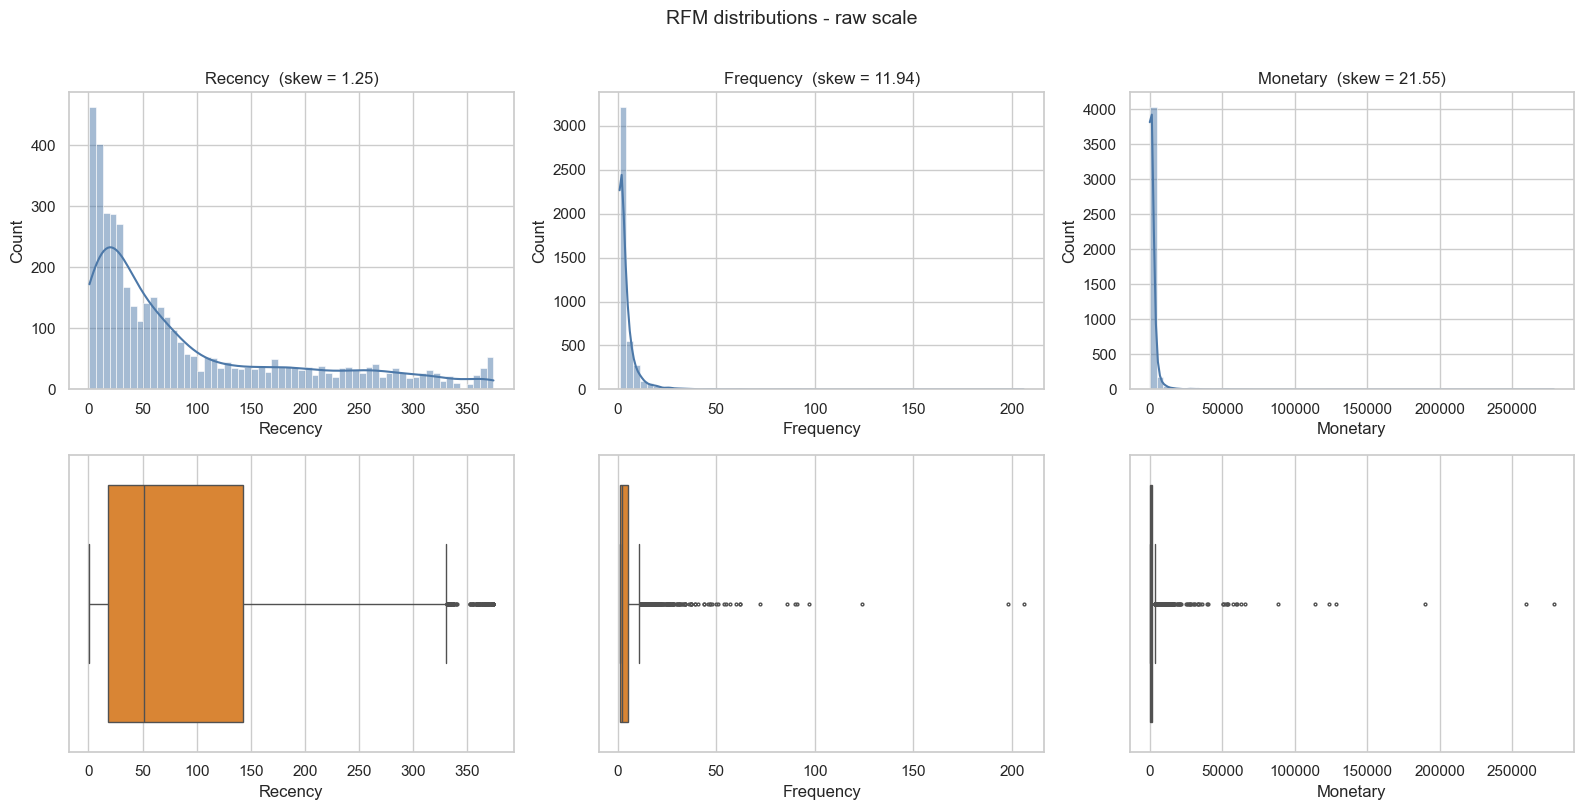

In [44]:
def dist_plot(df, title, fname, log_x=False):
    fig, axes = plt.subplots(2, 3, figsize=(16, 8))
    for j, col in enumerate(df.columns):
        sns.histplot(df[col], bins=60, kde=True, ax=axes[0, j], color="#4C78A8")
        axes[0, j].set_title(f"{col}  (skew = {df[col].skew():.2f})")
        sns.boxplot(x=df[col], ax=axes[1, j], color="#F58518", fliersize=2)
        if log_x:
            axes[0, j].set_xscale("log"); axes[1, j].set_xscale("log")
    fig.suptitle(title, y=1.01, fontsize=14)
    finish_fig(fig, fname)

dist_plot(rfm_raw, "RFM distributions - raw scale", "10_rfm_raw_distributions")

**How to read the raw plots:** Frequency and Monetary are typically extremely right-skewed (most customers are small, a few are huge). Recency is bounded (1 … ~373 days) and much milder. Those shapes drive every decision in Steps 5–7.

## Step 4C — RFM visualisation & interpretation
Scores are only useful when their **direction and meaning** are explicit.

* **R score:** 5 = bought most recently, 1 = lapsed longest (recency is *inverted* because fewer days is better).
* **F score / M score:** 5 = most orders / highest net spend.
* Ties are broken by order of appearance (`rank(method="first")`) so that five equal-sized bins always exist; customers with identical values can therefore sit in adjacent scores. That is fine for scoring, but do not over-read a single boundary.

The cells below translate each score into real days / orders / £, show how the scores combine, and list the churn early-warning group (high past value, low recent activity).


Recency              Frequency              Monetary                      
      min  median  max       min median  max       min    median         max
1     180 264.000  374         1  1.000    1     0.000   152.650     242.290
2      72 109.000  180         1  1.000    2   242.350   339.855     470.760
3      33  51.000   72         2  2.000    3   471.400   649.555     908.460
4      15  23.000   33         3  4.000    5   908.860 1,310.580   1,998.000
5       1   6.000   15         6  9.000  206 1,998.490 3,450.840 278,778.020

R: score 5 = last purchase within 15 days (most recent); score 1 = 180+ days ago (lapsed).
F: score 5 = at least 6 orders.   M: score 5 = net spend of GBP 1,998 or more.


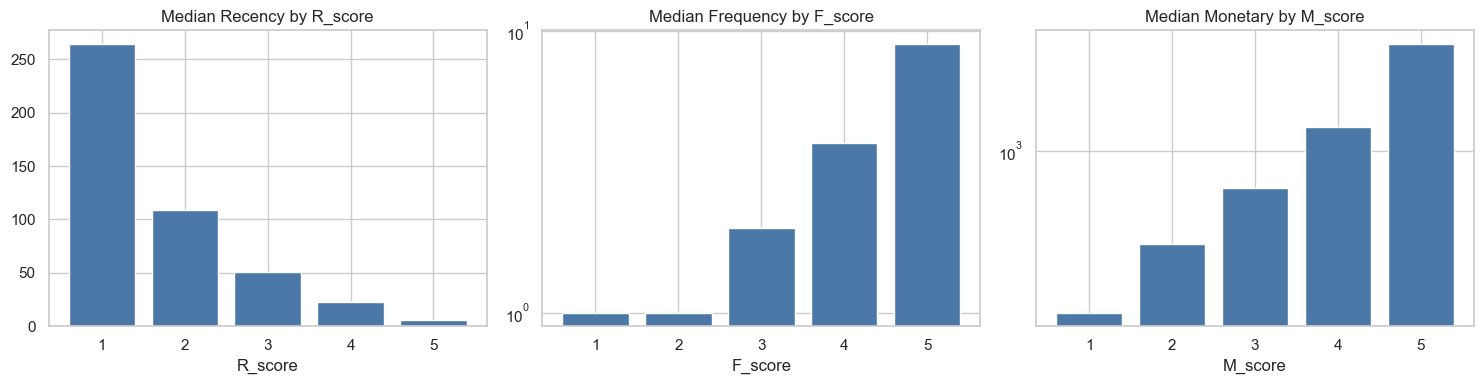

In [45]:
# What does each score level mean in real units?
meaning = {}
for raw, sc in [("Recency", "R_score"), ("Frequency", "F_score"), ("Monetary", "M_score")]:
    meaning[raw] = rfm_raw[raw].groupby(rfm_scores[sc]).agg(["min", "median", "max"])
meaning_tbl = pd.concat(meaning, axis=1)
display(meaning_tbl)

r_cut5 = rfm_raw.loc[rfm_scores["R_score"] == 5, "Recency"].max()
r_cut1 = rfm_raw.loc[rfm_scores["R_score"] == 1, "Recency"].min()
f_cut5 = rfm_raw.loc[rfm_scores["F_score"] == 5, "Frequency"].min()
m_cut5 = rfm_raw.loc[rfm_scores["M_score"] == 5, "Monetary"].min()
print(f"R: score 5 = last purchase within {r_cut5:.0f} days (most recent); score 1 = {r_cut1:.0f}+ days ago (lapsed).")
print(f"F: score 5 = at least {f_cut5:.0f} orders.   M: score 5 = net spend of GBP {m_cut5:,.0f} or more.")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (raw, sc) in zip(axes, [("Recency", "R_score"), ("Frequency", "F_score"), ("Monetary", "M_score")]):
    med = rfm_raw[raw].groupby(rfm_scores[sc]).median()
    ax.bar(med.index.astype(str), med.values, color="#4C78A8")
    ax.set_title(f"Median {raw} by {sc}")
    ax.set_xlabel(sc)
    if raw != "Recency":
        ax.set_yscale("log")
finish_fig(fig, "16_rfm_score_meaning")


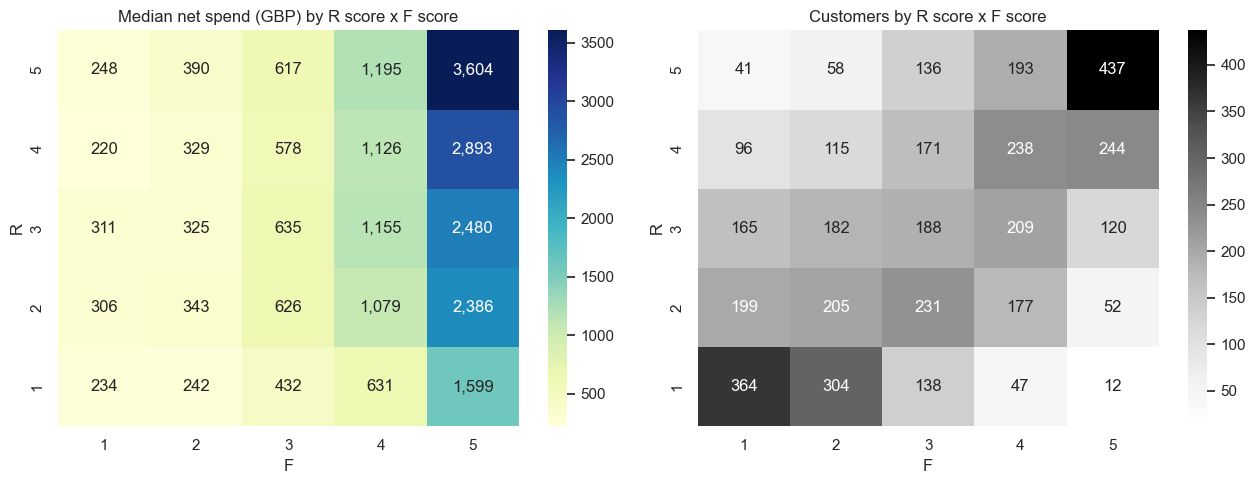

In [46]:
# R x F heatmaps: how much do customers spend, and how many are in each cell?
tmp = rfm_raw.assign(R=rfm_scores["R_score"], F=rfm_scores["F_score"])
pv_val = tmp.pivot_table(index="R", columns="F", values="Monetary", aggfunc="median")
pv_n = tmp.pivot_table(index="R", columns="F", values="Monetary", aggfunc="count").fillna(0)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(pv_val.sort_index(ascending=False), annot=True, fmt=",.0f", cmap="YlGnBu", ax=axes[0])
axes[0].set_title("Median net spend (GBP) by R score x F score")
sns.heatmap(pv_n.sort_index(ascending=False), annot=True, fmt=".0f", cmap="Greys", ax=axes[1])
axes[1].set_title("Customers by R score x F score")
finish_fig(fig, "17_rfm_heatmaps")


In [47]:
# Data-driven interpretation of the score combinations
total_m = rfm_raw["Monetary"].sum()
top_mask = (rfm_scores["R_score"] >= 4) & (rfm_scores["F_score"] >= 4) & (rfm_scores["M_score"] >= 4)
print(f"[Insight] Customers scoring >= 4 on ALL of R, F and M: {int(top_mask.sum()):,} "
      f"({top_mask.mean() * 100:.1f}% of customers) = {rfm_raw.loc[top_mask, 'Monetary'].sum() / total_m * 100:.1f}% of net revenue.")

combo = rfm_scores["RFM_Score"].value_counts().head(10)
combo_rev = rfm_raw["Monetary"].groupby(rfm_scores["RFM_Score"]).sum().reindex(combo.index) / total_m * 100
display(pd.DataFrame({"customers": combo, "pct_customers": combo / len(rfm_raw) * 100, "pct_revenue": combo_rev}))

risk = (rfm_scores["R_score"] <= 2) & (rfm_scores["F_score"] >= 4) & (rfm_scores["M_score"] >= 4)
print(f"\n[Early warning] High past value (F>=4, M>=4) but lapsed (R<=2): {int(risk.sum()):,} customers "
      f"holding {rfm_raw.loc[risk, 'Monetary'].sum() / total_m * 100:.1f}% of net revenue.")
if risk.any():
    display(rfm_raw[risk].nlargest(10, "Monetary"))


[Insight] Customers scoring >= 4 on ALL of R, F and M: 941 (21.8% of customers) = 66.8% of net revenue.


,customers,pct_customers,pct_revenue
RFM_Score,,,
555,346,8.006,45.662
111,188,4.350,0.322
455,175,4.049,12.211
121,153,3.540,0.265
112,120,2.776,0.482
444,113,2.615,1.839
122,93,2.152,0.383
233,88,2.036,0.700
344,87,2.013,1.448



[Early warning] High past value (F>=4, M>=4) but lapsed (R<=2): 173 customers holding 4.5% of net revenue.


,Recency,Frequency,Monetary
CustomerID,,,
16180,101,8,"10,217.480"
13093,276,8,"7,741.470"
16745,87,17,"7,157.100"
12980,158,9,"7,092.060"
13027,114,6,"6,912.000"
16182,73,4,"6,617.650"
15939,90,14,"6,087.260"
14101,74,6,"5,976.790"
16553,164,12,"5,664.570"


## Step 5 — Is the data ready for clustering? Skewness, scale, and transformations

**Why scale matters.** K-Means, hierarchical (Ward) and GMM clustering rely on Euclidean-type distances. If Monetary ranges in the tens of thousands while Frequency ranges 1–200 and Recency 1–373, Monetary contributes almost all of the distance and the "clusters" are really just a Monetary split. PCA has the same weakness: on unscaled data PC1 simply *is* the highest-variance column.

**Why skew matters (a separate problem).** Even after standardising, a heavy right tail leaves a handful of customers 10–30 standard deviations from the mean. K-Means centroids are means, so they get dragged toward those customers, and typically one cluster is spent on a few extremes while the bulk of customers collapse into a single blob. Standardising fixes *units*; it does **not** fix *shape*.

**Log validity.** `log(x)` needs `x > 0`. Recency ≥ 1 and Frequency ≥ 1 by construction, and Monetary > 0 because Step 3 removed net ≤ 0 customers. We still use `log1p(x) = log(1+x)` (equivalent shape, numerically safe near 0) and assert validity before transforming.

We compare candidates instead of applying one blindly.

In [48]:
# Mathematical validity guard for log-type transforms
assert (rfm_raw[FEATURES] > 0).all().all(), "log transform invalid: non-positive values present"

candidates = {
    "raw":         lambda s: s,
    "sqrt":        np.sqrt,
    "log1p":       np.log1p,
    "yeo-johnson": lambda s: pd.Series(PowerTransformer("yeo-johnson", standardize=False).fit_transform(s.to_frame()).ravel(), index=s.index),
}
skew_tbl = pd.DataFrame({name: {c: f(rfm_raw[c]).skew() for c in FEATURES} for name, f in candidates.items()})
print("Skewness by transformation (|skew| < ~0.5 symmetric, 0.5-1 moderate, > 1 heavy):")
print(skew_tbl.to_string())

Skewness by transformation (|skew| < ~0.5 symmetric, 0.5-1 moderate, > 1 heavy):
             raw  sqrt  log1p  yeo-johnson
Recency    1.245 0.601 -0.325       -0.050
Frequency 11.938 3.018  1.211        0.218
Monetary  21.548 5.859  0.300       -0.024


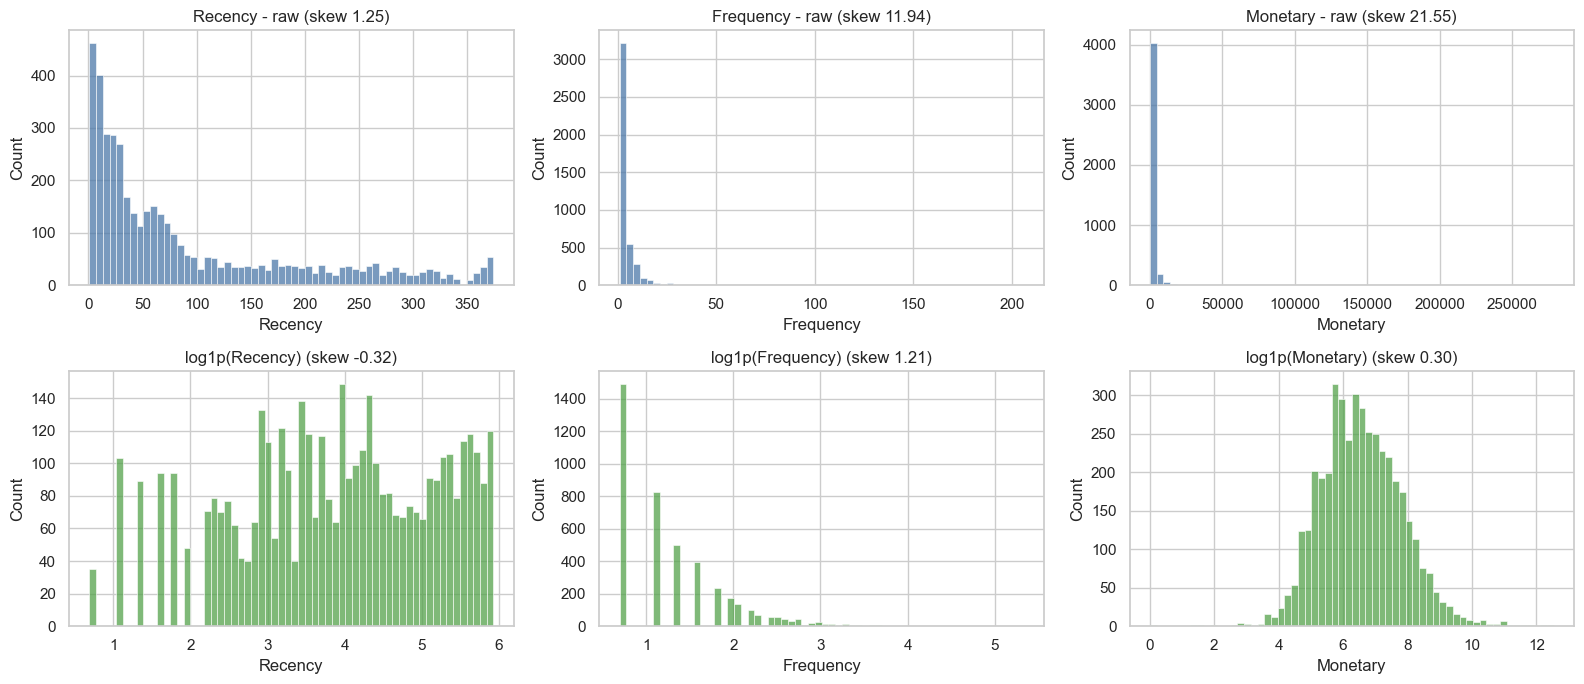

In [49]:
# Visual comparison: raw vs log1p (the interpretable candidate)
fig, axes = plt.subplots(2, 3, figsize=(16, 7))
for j, c in enumerate(FEATURES):
    sns.histplot(rfm_raw[c], bins=60, ax=axes[0, j], color="#4C78A8"); axes[0, j].set_title(f"{c} - raw (skew {rfm_raw[c].skew():.2f})")
    sns.histplot(np.log1p(rfm_raw[c]), bins=60, ax=axes[1, j], color="#54A24B"); axes[1, j].set_title(f"log1p({c}) (skew {np.log1p(rfm_raw[c]).skew():.2f})")
finish_fig(fig, "11_rfm_raw_vs_log")

In [50]:
# Guideline (section 4): apply a LOG transformation to compress the right-hand skew of wholesale volumes.
# The policy is fixed (log1p on R, F and M). The other candidates above are benchmarks only.
CHOICES = {c: "log1p" for c in FEATURES}
alt_best = {c: skew_tbl.loc[c, ["raw", "sqrt", "log1p"]].abs().sort_values().index[0] for c in FEATURES}

rfm_t = pd.DataFrame({f"{c}_t": candidates["log1p"](rfm_raw[c]) for c in FEATURES}, index=rfm_raw.index)
print("Policy: log1p on Recency, Frequency and Monetary.")
print("Most symmetric candidate per feature (benchmark, not used):", alt_best)
print("\nSkewness before -> after log1p:")
print(pd.DataFrame({"raw": rfm_raw[FEATURES].skew(), "log1p": rfm_t.skew().rename(lambda n: n.replace("_t", ""))}).to_string())


Policy: log1p on Recency, Frequency and Monetary.
Most symmetric candidate per feature (benchmark, not used): {'Recency': 'log1p', 'Frequency': 'log1p', 'Monetary': 'log1p'}

Skewness before -> after log1p:
             raw  log1p
Recency    1.245 -0.325
Frequency 11.938  1.211
Monetary  21.548  0.300


**Decision and interpretation.** All three dimensions are log-transformed, as the guideline requires. Log compresses ratios: going from 1→2 orders counts about as much as 50→100, which matches how a marketer thinks about loyalty. Frequency and Monetary are strongly right-skewed and log substantially reduces that skew — though Frequency skewness remains above 1.0 after the transform (visible in the skew table above) because ~35 % of customers bought only once, creating a discrete spike at log1p(1) that no continuous transform can fully smooth. Recency is bounded and milder; after `log1p` it can tip slightly *left*-skewed (many recent buyers). The skew table above shows exactly how much, and the benchmark line shows whether another transform would have been more symmetric. We keep `log1p` for consistency and interpretability, and the skew that remains is small compared with the raw data.

Standardisation is **not** part of this comparison because it is a linear rescale: it changes units, never skewness. It comes in Step 7.


## Step 6 — Outlier handling (identify, compare, decide — no automatic deletion)

Identification uses two lenses: **Tukey fences** (1.5×IQR) and **|z| > 3**. Extreme customers in this business are often wholesale buyers — real and commercially important — so deleting them would remove exactly the "VIP" segment we want to find.

Approaches compared:

| # | Approach | Expected effect |
|---|---|---|
| A | **Keep**, raw scale | Extreme customers dominate distances; clusters mostly split off outliers |
| B | **Winsorize** raw at 1st/99th pct | Removes domination but flattens the difference between a £30k and a £300k customer |
| C | **Transform only** (Step 5) | Compresses the tail while keeping every customer and their rank order |
| D | **Transform + light cap** (0.5th–99.5th pct) | Same as C, plus limits residual extremes; only justified if C still leaves |z| > 4 |

A useful clustering-specific metric: the share of total squared standardised distance contributed by the **top 1% most extreme customers** ("dominance"). If 1% of customers carry a large share, they steer the centroids.

In [51]:
def tukey_count(s: pd.Series) -> int:
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())

def outlier_table(df: pd.DataFrame) -> pd.DataFrame:
    z = (df - df.mean()) / df.std()
    return pd.DataFrame({
        "tukey_outliers": {c: tukey_count(df[c]) for c in df.columns},
        "tukey_%": {c: tukey_count(df[c]) / len(df) * 100 for c in df.columns},
        "|z|>3": (z.abs() > 3).sum(),
        "max_|z|": z.abs().max(),
        "skew": df.skew(),
    })

print("RAW scale:"); print(outlier_table(rfm_raw).to_string())
print("\nTRANSFORMED scale:"); print(outlier_table(rfm_t).to_string())

RAW scale:
           tukey_outliers  tukey_%  |z|>3  max_|z|   skew
Recency               153    3.540      0    2.806  1.245
Frequency             278    6.432     52   26.393 11.938
Monetary              410    9.486     32   33.349 21.548

TRANSFORMED scale:
             tukey_outliers  tukey_%  |z|>3  max_|z|   skew
Recency_t                 0    0.000      0    2.419 -0.325
Frequency_t              42    0.972     46    5.850  1.211
Monetary_t               54    1.249     36    5.212  0.300


In [52]:
def winsorize(df, q=WINSOR_Q):
    lo, hi = df.quantile(q[0]), df.quantile(q[1])
    return df.clip(lower=lo, upper=hi, axis=1)

def dominance(df, top=0.01):
    """Share of total squared z-distance carried by the `top` fraction of customers."""
    d2 = (((df - df.mean()) / df.std()) ** 2).sum(axis=1).sort_values(ascending=False)
    return d2.head(max(1, int(len(d2) * top))).sum() / d2.sum() * 100

approaches = {
    "A keep raw":              rfm_raw[FEATURES],
    "B winsorize raw 1-99":    winsorize(rfm_raw[FEATURES], (0.01, 0.99)),
    "C transform only":        rfm_t,
    "D transform + cap":       winsorize(rfm_t),
}
rows = {}
for name, d in approaches.items():
    z = (d - d.mean()) / d.std()
    rows[name] = {
        "max_|z| (any)": z.abs().max().max(),
        "customers |z|>3": int((z.abs() > 3).any(axis=1).sum()),
        "max |skew|": d.skew().abs().max(),
        "top-1% dominance %": dominance(d),
        "Spearman(M vs original)": stats.spearmanr(d.iloc[:, 2], rfm_raw["Monetary"])[0],
    }
compare = pd.DataFrame(rows).T
print(compare.to_string())

                      max_|z| (any)  customers |z|>3  max |skew|  top-1% dominance %  Spearman(M vs original)
A keep raw                   33.349           62.000      21.548              54.128                    1.000
B winsorize raw 1-99          6.180          160.000       3.988              21.130                    1.000
C transform only              5.850           64.000       1.211               9.358                    1.000
D transform + cap             3.609           61.000       1.078               7.734                    1.000


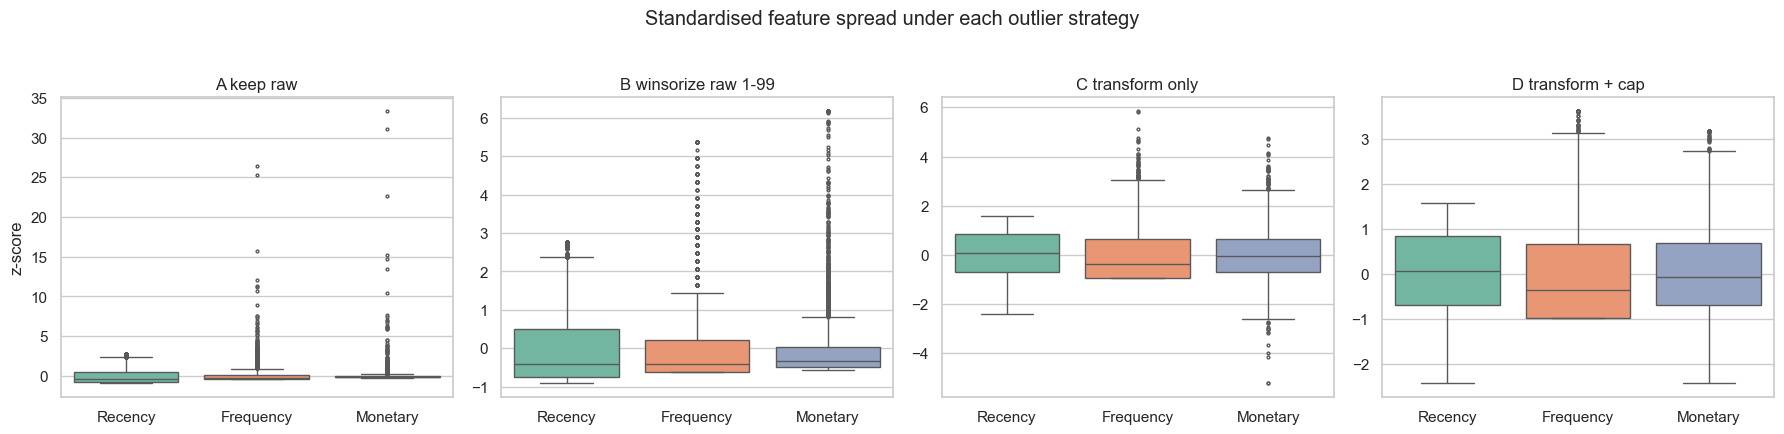

In [53]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.2), sharey=False)
for ax, (name, d) in zip(axes, approaches.items()):
    z = (d - d.mean()) / d.std()
    sns.boxplot(data=z, ax=ax, fliersize=2, palette="Set2")
    ax.set_title(name); ax.set_ylabel("z-score" if ax is axes[0] else "")
    ax.set_xticklabels([c.replace("_t", "") for c in d.columns], rotation=0)
fig.suptitle("Standardised feature spread under each outlier strategy", y=1.03)
finish_fig(fig, "12_outlier_strategies")

In [54]:
# Data-driven decision: transform (C). Cap lightly (D) ONLY if transformed data still has |z| > Z_CAP_TRIGGER.
z_t = (rfm_t - rfm_t.mean()) / rfm_t.std()
max_z_t = z_t.abs().max().max()
APPLY_CAP = bool(max_z_t > Z_CAP_TRIGGER)
print(f"Max |z| after transformation = {max_z_t:.2f}  ->  cap {'APPLIED' if APPLY_CAP else 'NOT needed'} (trigger = {Z_CAP_TRIGGER})")

rfm_transformed = winsorize(rfm_t) if APPLY_CAP else rfm_t.copy()

# Nobody is deleted; extreme customers stay identifiable for later profiling (e.g. a wholesale/VIP cluster)
rfm_aux["is_extreme_raw"] = ((rfm_raw - rfm_raw.mean()) / rfm_raw.std()).abs().gt(3).any(axis=1)
rfm_aux["was_capped"] = (rfm_transformed != rfm_t).any(axis=1)
print(f"Customers flagged extreme on raw scale : {rfm_aux['is_extreme_raw'].sum():,} "
      f"({rfm_aux['is_extreme_raw'].mean()*100:.1f}%)  | capped values on transformed scale: {rfm_aux['was_capped'].sum():,}")
assert len(rfm_transformed) == len(rfm_raw), "a customer was deleted"

Max |z| after transformation = 5.85  ->  cap APPLIED (trigger = 4.0)
Customers flagged extreme on raw scale : 62 (1.4%)  | capped values on transformed scale: 66


**Decision logic, in plain words:** we transform first (keeps everyone, keeps rank order, shrinks the tail). A cap is added only if extreme values *remain* after transforming. `rfm_raw` is never modified, so the true £ values of the biggest customers are still available for business interpretation after clustering.

## Step 7 — Scaling
Guideline: scale the columns with **`StandardScaler`** to mean 0 and variance 1, otherwise the widest-range variable dominates Euclidean distance.

* **StandardScaler**: `(x − mean) / std`. Assumes roughly symmetric data. That is why the log transform comes first.
* **RobustScaler** is computed only as a *diagnostic comparison*; it is not used.

The diagnostics below confirm the precondition (near-symmetric, no extreme tail) instead of assuming it.


                                      diagnostics
max |skew| after transform                  1.078
max |z| (Standard)                          3.609
max |value| (Robust)                        2.427
Robust IQR spread of std across cols        1.195


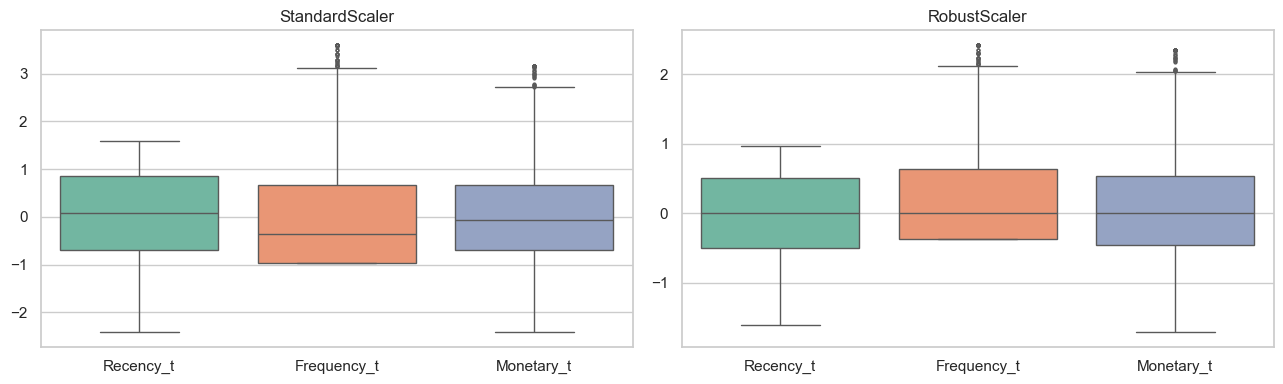

In [55]:
std_scaled = pd.DataFrame(StandardScaler().fit_transform(rfm_transformed), index=rfm_transformed.index, columns=rfm_transformed.columns)
rob_scaled = pd.DataFrame(RobustScaler().fit_transform(rfm_transformed), index=rfm_transformed.index, columns=rfm_transformed.columns)

diag = pd.DataFrame({
    "max |skew| after transform": [rfm_transformed.skew().abs().max()],
    "max |z| (Standard)": [std_scaled.abs().max().max()],
    "max |value| (Robust)": [rob_scaled.abs().max().max()],
    "Robust IQR spread of std across cols": [rob_scaled.std().max() / rob_scaled.std().min()],
}, index=["diagnostics"]).T
print(diag.to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=std_scaled, ax=axes[0], fliersize=2, palette="Set2"); axes[0].set_title("StandardScaler")
sns.boxplot(data=rob_scaled, ax=axes[1], fliersize=2, palette="Set2"); axes[1].set_title("RobustScaler")
finish_fig(fig, "13_scaler_comparison")

In [56]:
# Guideline (section 4): StandardScaler. The checks below verify its preconditions; they do not change the choice.
SYMMETRIC = rfm_transformed.skew().abs().max() < 1.0
LIGHT_TAIL = std_scaled.abs().max().max() <= 5.0
SCALER_NAME = "StandardScaler"
print(f"Preconditions -> symmetric (max |skew| < 1): {SYMMETRIC} | light tail (max |z| <= 5): {LIGHT_TAIL}")
if not (SYMMETRIC and LIGHT_TAIL):
    print("WARNING: a precondition failed - review the transformed distributions before trusting distance-based clustering.")

rfm_scaled = std_scaled.copy()
rfm_scaled.columns = [c.replace("_t", "_s") for c in rfm_scaled.columns]
assert (rfm_scaled.mean().abs() < 1e-6).all() and ((rfm_scaled.std(ddof=0) - 1).abs() < 1e-6).all()
print(rfm_scaled.describe().T[["mean", "std", "min", "max"]].to_string())


Preconditions -> symmetric (max |skew| < 1): False | light tail (max |z| <= 5): True
              mean   std    min   max
Recency_s    0.000 1.000 -2.419 1.581
Frequency_s  0.000 1.000 -0.964 3.609
Monetary_s  -0.000 1.000 -2.410 3.157


**Note on fitting:** scalers/PCA are fit on the full customer population because this is unsupervised segmentation of the whole base (there is no train/test split to leak across). If you later score *new* customers, save the fitted scaler and reuse it.

## Step 8 — PCA preparation

**Is PCA useful here?** We have only **3** features. PCA is valuable for compressing many correlated variables; with 3 there is little to compress, and dropping a component would discard part of R, F or M. So the question is answered with evidence: correlation between the scaled features, the explained variance, and the loadings.

Order is always: transform → scale → PCA (PCA on unscaled data would just return the highest-variance column as PC1).

Correlation of scaled features:
             Recency_s  Frequency_s  Monetary_s
Recency_s        1.000       -0.573      -0.490
Frequency_s     -0.573        1.000       0.813
Monetary_s      -0.490        0.813       1.000

      explained_var_ratio  cumulative  eigenvalue
PC1                0.754       0.754       2.262
PC2                0.186       0.940       0.559
PC3                0.060       1.000       0.180

Loadings (how each PC is built from R, F, M):
             PC1   PC2    PC3
Recency   -0.512 0.850  0.123
Frequency  0.617 0.265  0.741
Monetary   0.597 0.455 -0.661


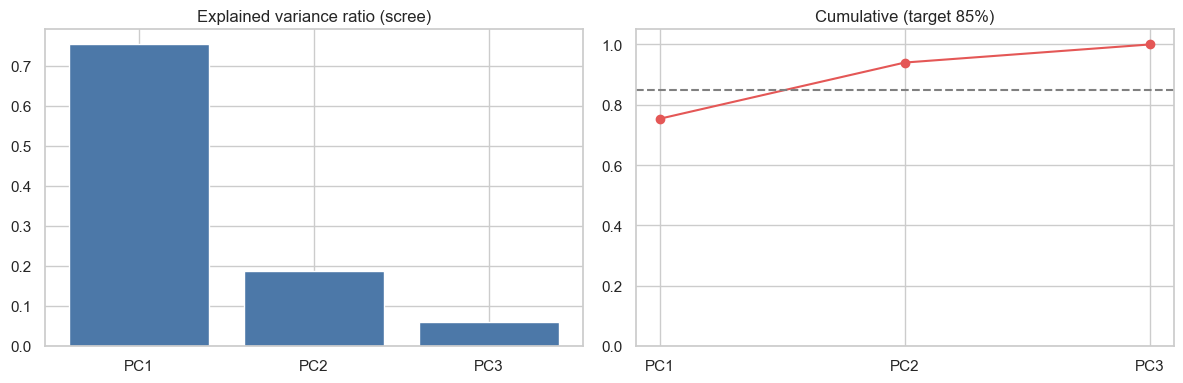

In [57]:
print("Correlation of scaled features:")
print(rfm_scaled.corr().to_string())

pca_full = PCA(n_components=rfm_scaled.shape[1], random_state=RANDOM_STATE).fit(rfm_scaled)
evr = pca_full.explained_variance_ratio_
cum = evr.cumsum()
ev_tbl = pd.DataFrame({"explained_var_ratio": evr, "cumulative": cum,
                       "eigenvalue": pca_full.explained_variance_}, index=[f"PC{i+1}" for i in range(len(evr))])
print("\n", ev_tbl.to_string())

loadings = pd.DataFrame(pca_full.components_.T, index=FEATURES, columns=ev_tbl.index)
print("\nLoadings (how each PC is built from R, F, M):"); print(loadings.to_string())

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(ev_tbl.index, evr, color="#4C78A8"); ax[0].set_title("Explained variance ratio (scree)")
ax[1].plot(ev_tbl.index, cum, marker="o", color="#E45756"); ax[1].axhline(PCA_VAR_TARGET, ls="--", color="grey")
ax[1].set_ylim(0, 1.05); ax[1].set_title(f"Cumulative (target {PCA_VAR_TARGET:.0%})")
finish_fig(fig, "14_pca_variance")

Components for >= 85% variance: 2 | Kaiser (eigenvalue > 1): 1 | keeping: 2

PCA reduces dimensionality (valid optional clustering input)? True   |   PCA used for visualisation? True
Variance retained by 2 PCs: 94.0%


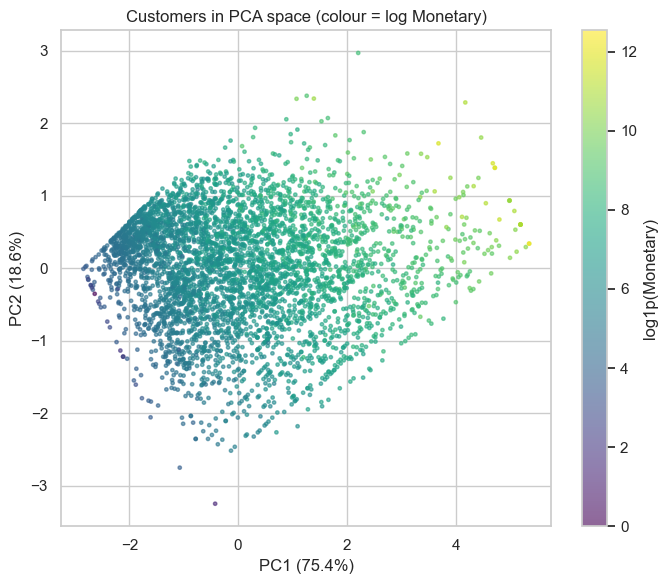

In [58]:
n_target = int(np.argmax(cum >= PCA_VAR_TARGET) + 1)
n_kaiser = int((pca_full.explained_variance_ > 1).sum())         # valid for standardised data
N_COMPONENTS = max(2, n_target)                                    # at least 2 so a 2-D map can be drawn
print(f"Components for >= {PCA_VAR_TARGET:.0%} variance: {n_target} | Kaiser (eigenvalue > 1): {n_kaiser} | keeping: {N_COMPONENTS}")

# PCA only helps clustering if it actually reduces dimensionality without losing much information
PCA_FOR_CLUSTERING = N_COMPONENTS < rfm_scaled.shape[1]
print(f"\nPCA reduces dimensionality (valid optional clustering input)? {PCA_FOR_CLUSTERING}   |   PCA used for visualisation? True")

pca = PCA(n_components=N_COMPONENTS, random_state=RANDOM_STATE).fit(rfm_scaled)
rfm_pca = pd.DataFrame(pca.transform(rfm_scaled), index=rfm_scaled.index, columns=[f"PC{i+1}" for i in range(N_COMPONENTS)])
print(f"Variance retained by {N_COMPONENTS} PCs: {pca.explained_variance_ratio_.sum():.1%}")

fig, ax = plt.subplots(figsize=(7, 6))
sc = ax.scatter(rfm_pca["PC1"], rfm_pca["PC2"], c=np.log1p(rfm_raw["Monetary"]), s=6, cmap="viridis", alpha=.6)
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})"); ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
ax.set_title("Customers in PCA space (colour = log Monetary)"); plt.colorbar(sc, label="log1p(Monetary)")
finish_fig(fig, "15_pca_scatter")

**How to read the result and what it means for the next phase**

* If the first two PCs already capture most of the variance and R/F/M are strongly correlated (Frequency and Monetary usually are), a **2-D PCA map is a faithful picture** — good for plotting clusters.
* Because there are only 3 features, PCA here is a **rotation**, not a real reduction, unless `N_COMPONENTS < 3`. The printed flag `PCA reduces dimensionality?` reports which case you are in.
* Recommended use: **cluster on `rfm_scaled` (all 3 standardised features, fully interpretable), and use `rfm_pca` for visualisation only.** If `PCA_FOR_CLUSTERING` printed `True`, `rfm_pca` is a valid *second* clustering input to compare against, not the default.

## Step 9 — Named modelling datasets
All datasets share the **same index (`CustomerID`) in the same order**, so labels from any model attach back to `rfm_raw`, `rfm_aux` (return value, extreme flags) or any other customer table with a plain join. `CustomerID` is the *index*, never a column of the feature matrices.

In [59]:
datasets = {"rfm_raw": rfm_raw, "rfm_transformed": rfm_transformed, "rfm_scaled": rfm_scaled, "rfm_pca": rfm_pca}
customer_ids = pd.Series(rfm_raw.index, name="CustomerID")

RFM_DIR.mkdir(parents=True, exist_ok=True)
to_save = {**datasets, "rfm_aux": rfm_aux, "rfm_scores": rfm_scores, "rfm_excluded_nonpositive": rfm_excluded_nonpositive}
for name, tbl in to_save.items():
    try:
        tbl.to_parquet(RFM_DIR / f"{name}.parquet")
    except Exception:
        tbl.to_csv(RFM_DIR / f"{name}.csv.gz")
print("Saved:", list(to_save), "->", RFM_DIR)
for name, d in datasets.items():
    print(f"{name:16s} shape={d.shape}  columns={list(d.columns)}")

Saved: ['rfm_raw', 'rfm_transformed', 'rfm_scaled', 'rfm_pca', 'rfm_aux', 'rfm_scores', 'rfm_excluded_nonpositive'] -> d:\NTI\NTI 2026\17\project\final\data\processed\rfm
rfm_raw          shape=(4322, 3)  columns=['Recency', 'Frequency', 'Monetary']
rfm_transformed  shape=(4322, 3)  columns=['Recency_t', 'Frequency_t', 'Monetary_t']
rfm_scaled       shape=(4322, 3)  columns=['Recency_s', 'Frequency_s', 'Monetary_s']
rfm_pca          shape=(4322, 2)  columns=['PC1', 'PC2']


In [60]:
# Hand-off metadata for Phase 3 (so the clustering notebook can run on its own, straight from disk)
meta = {
    "snapshot": str(snapshot.date()),
    "monetary_basis": MONETARY_BASIS,
    "transforms": CHOICES,
    "cap_applied": bool(APPLY_CAP),
    "scaler": SCALER_NAME,
    "n_components": int(N_COMPONENTS),
    "pca_evr": [float(v) for v in pca.explained_variance_ratio_],
    "pca_for_clustering": bool(PCA_FOR_CLUSTERING),
    "n_customers": int(len(rfm_raw)),
    "random_state": RANDOM_STATE,
}
RFM_DIR.mkdir(parents=True, exist_ok=True)
(RFM_DIR / "rfm_meta.json").write_text(json.dumps(meta, indent=2))
print("Saved", RFM_DIR / "rfm_meta.json")
print(meta)


Saved d:\NTI\NTI 2026\17\project\final\data\processed\rfm\rfm_meta.json
{'snapshot': '2011-12-10', 'monetary_basis': 'net', 'transforms': {'Recency': 'log1p', 'Frequency': 'log1p', 'Monetary': 'log1p'}, 'cap_applied': True, 'scaler': 'StandardScaler', 'n_components': 2, 'pca_evr': [0.7537705139051539, 0.1862627769315665], 'pca_for_clustering': True, 'n_customers': 4322, 'random_state': 42}


## Step 10 — Final validation before clustering

In [61]:
checks = {}
idx = rfm_raw.index

checks["one row = one customer (unique index)"] = idx.is_unique
checks["no duplicate CustomerIDs"] = not idx.duplicated().any()
checks["row count == unique customers in population"] = len(rfm_raw) + len(rfm_excluded_nonpositive) == pop["CustomerID"].nunique()
checks["no missing RFM values (all datasets)"] = all(not d.isna().any().any() for d in datasets.values())
checks["no NaN/inf anywhere"] = all(np.isfinite(d.to_numpy(dtype=float)).all() for d in datasets.values())
checks["all datasets share same CustomerID order"] = all(d.index.equals(idx) for d in datasets.values())
checks["CustomerID not a feature column (any dataset)"] = all("CustomerID" not in d.columns for d in datasets.values())
checks["all clustering features numeric"] = all(all(pd.api.types.is_numeric_dtype(t) for t in d.dtypes) for d in datasets.values())
checks["raw R/F/M valid (R>=1, F>=1, M>0)"] = bool((rfm_raw["Recency"] >= 1).all() and (rfm_raw["Frequency"] >= 1).all() and (rfm_raw["Monetary"] > 0).all())
# Leakage / population integrity
checks["every customer comes from identified sales lines"] = set(idx) <= set(pop["CustomerID"])
checks["no guest lines in population"] = pop["CustomerID"].notna().all()
checks["no cancellation invoice counted as an order"] = not pop["InvoiceNo"].str.startswith("C").any()
checks["no transaction after snapshot date"] = bool((pop["InvoiceDate"] < snapshot).all())
checks["customers deleted as outliers = 0"] = len(rfm_transformed) == len(rfm_raw)
checks["scaled features centred (|mean|<1e-6 if Standard)"] = (SCALER_NAME != "StandardScaler") or bool((rfm_scaled.mean().abs() < 1e-6).all())
checks["RFM scores are integers 1-5"] = bool(
    rfm_scores[["R_score", "F_score", "M_score"]].apply(lambda s: s.between(1, 5).all()).all()
)
checks["RFM combined score has 3 digits"] = bool(rfm_scores["RFM_Score"].str.fullmatch(r"[1-5]{3}").all())


for k, v in checks.items():
    print(("PASS  " if v else "FAIL  ") + k)
assert all(checks.values()), "Final validation failed - fix before clustering"
print("\nALL CHECKS PASSED")

PASS  one row = one customer (unique index)
PASS  no duplicate CustomerIDs
PASS  row count == unique customers in population
PASS  no missing RFM values (all datasets)
PASS  no NaN/inf anywhere
PASS  all datasets share same CustomerID order
PASS  CustomerID not a feature column (any dataset)
PASS  all clustering features numeric
PASS  raw R/F/M valid (R>=1, F>=1, M>0)
PASS  every customer comes from identified sales lines
PASS  no guest lines in population
PASS  no cancellation invoice counted as an order
PASS  no transaction after snapshot date
PASS  customers deleted as outliers = 0
PASS  scaled features centred (|mean|<1e-6 if Standard)
PASS  RFM scores are integers 1-5
PASS  RFM combined score has 3 digits

ALL CHECKS PASSED


In [62]:
print("Final shapes")
for name, d in datasets.items():
    print(f"  {name:16s} {d.shape}")
print(f"  {'customer_ids':16s} {customer_ids.shape}")
print(f"\nSnapshot: {snapshot.date()} | Monetary basis: {MONETARY_BASIS} | transforms: {CHOICES} | "
      f"cap applied: {APPLY_CAP} | scaler: {SCALER_NAME} | PCs kept: {N_COMPONENTS} (clustering on PCA: {PCA_FOR_CLUSTERING})")
for name, d in datasets.items():
    print(f"\n--- {name} ---")
    print(d.describe().T[["count", "mean", "std", "min", "50%", "max"]].to_string())

Final shapes
  rfm_raw          (4322, 3)
  rfm_transformed  (4322, 3)
  rfm_scaled       (4322, 3)
  rfm_pca          (4322, 2)
  customer_ids     (4322,)

Snapshot: 2011-12-10 | Monetary basis: net | transforms: {'Recency': 'log1p', 'Frequency': 'log1p', 'Monetary': 'log1p'} | cap applied: True | scaler: StandardScaler | PCs kept: 2 (clustering on PCA: True)

--- rfm_raw ---
              count      mean       std   min     50%         max
Recency   4,322.000    93.093   100.116 1.000  51.000     374.000
Frequency 4,322.000     4.255     7.644 1.000   2.000     206.000
Monetary  4,322.000 1,913.382 8,301.965 0.000 649.555 278,778.020

--- rfm_transformed ---
                count  mean   std   min   50%    max
Recency_t   4,322.000 3.857 1.308 0.693 3.951  5.924
Frequency_t 4,322.000 1.341 0.672 0.693 1.099  3.765
Monetary_t  4,322.000 6.553 1.228 3.595 6.478 10.430

--- rfm_scaled ---
                count   mean   std    min    50%   max
Recency_s   4,322.000  0.000 1.000 -2.419  0

## Hand-off to Phase 3 (clustering — not started)
* Cluster on **`rfm_scaled`** (numeric R/F/M only); use **`rfm_pca`** for plots. Keep `rfm_raw` and `rfm_aux` to interpret clusters in real £ / days / orders.
* Customers with net revenue ≤ 0 are in `rfm_excluded_nonpositive` (return-heavy or fully cancelled) and can be analysed as their own "refund-driven" group.
* Sensitivity worth running later: `MONETARY_BASIS="gross"` and a cap on/off variant, to check that segments are stable.

---
# PART 3 — Clustering, Segment Profiling & Business Strategy
*(also delivered as `03_clustering_segmentation.ipynb`; reads the tables saved at the end of Part 2)*


# 03 — Clustering, Segment Profiling & Business Strategy
**Project:** Online Retail — Customer Analytics & Segmentation | **Phase 3**

**Author (Phase 3):** Eng. Mahmoud Mansour (follows `02_rfm_preprocessing`)

Goal: build **defensible, evidence-based customer segments** from the prepared RFM data and translate them into marketing actions.

Flow: load Phase 2 outputs → compare K-Means, Hierarchical and DBSCAN → choose K from several pieces of evidence (not from the elbow alone) → fit and stress-test the segmentation → profile segments in real £/days/orders → name them from measured profiles → business recommendations.

This notebook runs **standalone**: it reads the tables that Phase 2 saved to `data/processed/rfm/`.


## Step 0 — Configuration & loading Phase 2 outputs
All decisions that change the outcome live in the config block: the K range that is evaluated, the **business range** for K, the hierarchical sample size and the number of stability re-runs.


In [63]:
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage
from sklearn.cluster import DBSCAN, KMeans
from sklearn.metrics import adjusted_rand_score, davies_bouldin_score, silhouette_score
from sklearn.neighbors import NearestNeighbors

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid", context="notebook")

# ---- Config ----
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RFM_DIR = ROOT / "data/processed/rfm"
FIG_DIR = ROOT / "reports/figures"
REPORT_DIR = ROOT / "reports"
SHOW_PLOTS = True
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

K_EVAL = list(range(2, 11))          # K values evaluated for the elbow / silhouette / Davies-Bouldin
K_BUSINESS_RANGE = (4, 6)            # fixed BEFORE looking at results: the guideline's action matrix needs >= 4 archetypes,
                                     # and > 6 segments is more than a marketing team can act on
HIER_SAMPLE_SIZE = 1500              # hierarchical clustering is expensive -> reproducible sample
STABILITY_RUNS = 10


def finish_fig(fig, name):
    FIG_DIR.mkdir(parents=True, exist_ok=True)
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    if SHOW_PLOTS:
        plt.show()
    plt.close(fig)


def find_knee(y):
    """Elbow/knee = point farthest from the straight line joining the first and last points (axes normalised)."""
    y = np.asarray(y, dtype=float)
    x = np.arange(len(y), dtype=float)
    xn = (x - x.min()) / (x.max() - x.min())
    yn = (y - y.min()) / (y.max() - y.min())
    chord = np.array([xn[-1] - xn[0], yn[-1] - yn[0]])
    chord = chord / np.linalg.norm(chord)
    vec = np.c_[xn - xn[0], yn - yn[0]]
    dist = np.abs(vec[:, 0] * chord[1] - vec[:, 1] * chord[0])
    return int(dist.argmax())


def load_rfm(name):
    """Load a Phase 2 table (parquet, or the gzipped-CSV fallback) with CustomerID as a clean text index."""
    pq, gz = RFM_DIR / f"{name}.parquet", RFM_DIR / f"{name}.csv.gz"
    if pq.exists():
        df = pd.read_parquet(pq)
    elif gz.exists():
        df = pd.read_csv(gz, index_col=0)
    else:
        raise FileNotFoundError(f"Neither {pq} nor {gz} exists - run Phase 2 (02_rfm_preprocessing) first.")
    df.index = df.index.astype(str).str.replace(r"\.0$", "", regex=True)
    df.index.name = "CustomerID"
    if "RFM_Score" in df.columns:
        df["RFM_Score"] = df["RFM_Score"].astype(str)
    return df


rfm_raw, rfm_scaled, rfm_pca, rfm_aux = (load_rfm(n) for n in ["rfm_raw", "rfm_scaled", "rfm_pca", "rfm_aux"])
meta = json.loads((RFM_DIR / "rfm_meta.json").read_text())
SCALER_NAME = meta["scaler"]
PCA_EVR = meta["pca_evr"]
print("Loaded:", {n: d.shape for n, d in {"rfm_raw": rfm_raw, "rfm_scaled": rfm_scaled, "rfm_pca": rfm_pca, "rfm_aux": rfm_aux}.items()})
print("Phase 2 settings:", {k: meta[k] for k in ["snapshot", "monetary_basis", "transforms", "scaler", "cap_applied"]})


Loaded: {'rfm_raw': (4322, 3), 'rfm_scaled': (4322, 3), 'rfm_pca': (4322, 2), 'rfm_aux': (4322, 17)}
Phase 2 settings: {'snapshot': '2011-12-10', 'monetary_basis': 'net', 'transforms': {'Recency': 'log1p', 'Frequency': 'log1p', 'Monetary': 'log1p'}, 'scaler': 'StandardScaler', 'cap_applied': True}


## Step 1 — Preprocessing recap: is the data ready for clustering?
Phase 2 prepared the clustering matrix in the order the guideline requires: **log transform → StandardScaler**. Below we re-verify it instead of trusting it: same customers in every table, all features numeric, scaled features with mean 0 and variance 1, `CustomerID` only ever an index.


In [64]:
# One row = one identified customer. CustomerID is the index, never a feature.
profile = rfm_raw.join(rfm_aux, how="left")
profile["Return_Rate"] = profile["ReturnRatio"].fillna(0.0)
profile["AOV"] = profile["Monetary"] / profile["Frequency"]

needed = {"R_score", "F_score", "M_score", "RFM_Score", "RFM_Total", "Is_UK", "TenureDays"}
assert needed.issubset(profile.columns), f"Missing columns from Phase 2: {sorted(needed - set(profile.columns))}"
assert profile.index.equals(rfm_scaled.index) and profile.index.equals(rfm_pca.index)
assert profile.index.is_unique
assert profile["Return_Rate"].between(0, 1).all()
assert SCALER_NAME == "StandardScaler"
assert (rfm_scaled.mean().abs() < 1e-6).all() and ((rfm_scaled.std(ddof=0) - 1).abs() < 1e-6).all()
assert all(pd.api.types.is_numeric_dtype(t) for t in rfm_scaled.dtypes) and "CustomerID" not in rfm_scaled.columns

CLUSTERING_DATA = rfm_scaled.copy()
print(f"Customers: {len(profile):,} | clustering features: {list(CLUSTERING_DATA.columns)} | scaler: {SCALER_NAME}")
print("Transformations applied in Phase 2:", meta["transforms"])
print("Mean / std of the clustering matrix (should be ~0 / ~1):")
print(CLUSTERING_DATA.agg(["mean", lambda s: s.std(ddof=0)]).set_axis(["mean", "std"]).to_string())


Customers: 4,322 | clustering features: ['Recency_s', 'Frequency_s', 'Monetary_s'] | scaler: StandardScaler
Transformations applied in Phase 2: {'Recency': 'log1p', 'Frequency': 'log1p', 'Monetary': 'log1p'}
Mean / std of the clustering matrix (should be ~0 / ~1):
      Recency_s  Frequency_s  Monetary_s
mean      0.000        0.000      -0.000
std       1.000        1.000       1.000


## Step 2 — Algorithm comparison: K-Means, Hierarchical, DBSCAN
No algorithm is chosen from theory alone. Each one is given the role the guideline assigns it and judged on evidence:

| Algorithm | Role here | What we look at |
|---|---|---|
| **K-Means** | Candidate for the final segmentation (baseline, interpretable) | Elbow, silhouette, Davies-Bouldin, stability |
| **Hierarchical (Ward)** | Structure check on a **sample** (expensive on large data) | Dendrogram heights, silhouette per cut, agreement with K-Means |
| **DBSCAN** | **Outlier / noise screen** for whale buyers | Noise share and who the noise customers are in real £ |


#### 2a — Hierarchical clustering (reproducible sample)


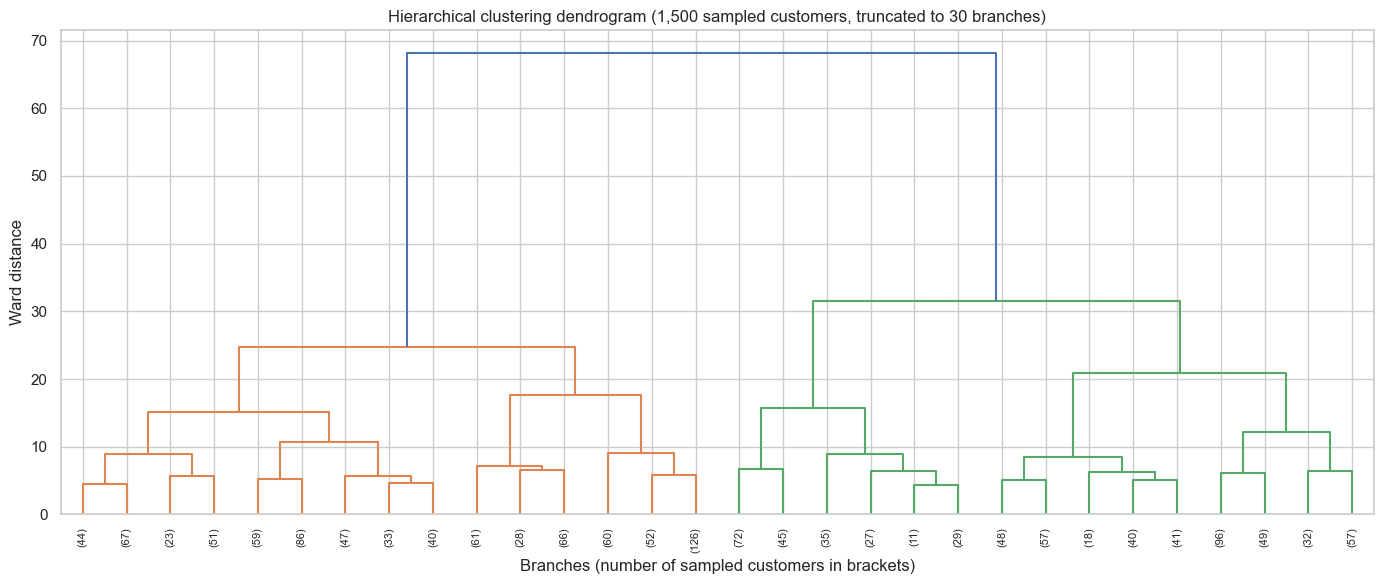

Height gap when going from k to k+1 clusters:
k=2    36.623
k=3     6.756
k=4     3.788
k=5     3.231
k=6     1.975
k=7     0.611
k=8     2.939
k=9     1.444
k=10    1.583

Largest height gap -> natural cut at k = 2 (this is evidence, not the final decision).
Hierarchical K=3: silhouette=0.327, cluster sizes=[843, 219, 438]
Hierarchical K=4: silhouette=0.253, cluster sizes=[450, 393, 219, 438]
Hierarchical K=5: silhouette=0.244, cluster sizes=[450, 393, 219, 204, 234]
Hierarchical K=6: silhouette=0.234, cluster sizes=[450, 155, 238, 219, 204, 234]


In [65]:
hier_sample_ids = CLUSTERING_DATA.sample(min(HIER_SAMPLE_SIZE, len(CLUSTERING_DATA)), random_state=RANDOM_STATE).index
HIER_DATA = CLUSTERING_DATA.loc[hier_sample_ids]
Z = linkage(HIER_DATA, method="ward")

fig, ax = plt.subplots(figsize=(14, 6))
dendrogram(Z, ax=ax, truncate_mode="lastp", p=30, show_leaf_counts=True, leaf_rotation=90, leaf_font_size=8)
ax.set_xlabel("Branches (number of sampled customers in brackets)")
ax.set_ylabel("Ward distance")
ax.set_title(f"Hierarchical clustering dendrogram ({len(HIER_DATA):,} sampled customers, truncated to 30 branches)")
finish_fig(fig, "25_hierarchical_dendrogram")

# Tree heights: the largest jump between successive merge heights suggests a natural number of clusters
heights = Z[::-1, 2][:10]
gaps = heights[:-1] - heights[1:]
k_candidates = np.arange(2, 2 + len(gaps))
K_HIER_TREE = int(k_candidates[gaps.argmax()])
print("Height gap when going from k to k+1 clusters:")
print(pd.Series(gaps, index=[f"k={k}" for k in k_candidates]).round(3).to_string())
print(f"\nLargest height gap -> natural cut at k = {K_HIER_TREE} (this is evidence, not the final decision).")

hierarchical_results = {}
for k in range(3, 7):
    labels = fcluster(Z, k, criterion="maxclust") - 1
    hierarchical_results[k] = labels
    print(f"Hierarchical K={k}: silhouette={silhouette_score(HIER_DATA, labels):.3f}, cluster sizes={np.bincount(labels).tolist()}")


#### 2b — DBSCAN as an outlier / noise screen
`min_samples` follows the usual rule of thumb (2 × number of features). `eps` is read from the **knee of the k-distance curve** rather than guessed, and neighbouring values are tried to show sensitivity. DBSCAN is *not* the final segmentation: its job is to tell us who the anomalous customers are.


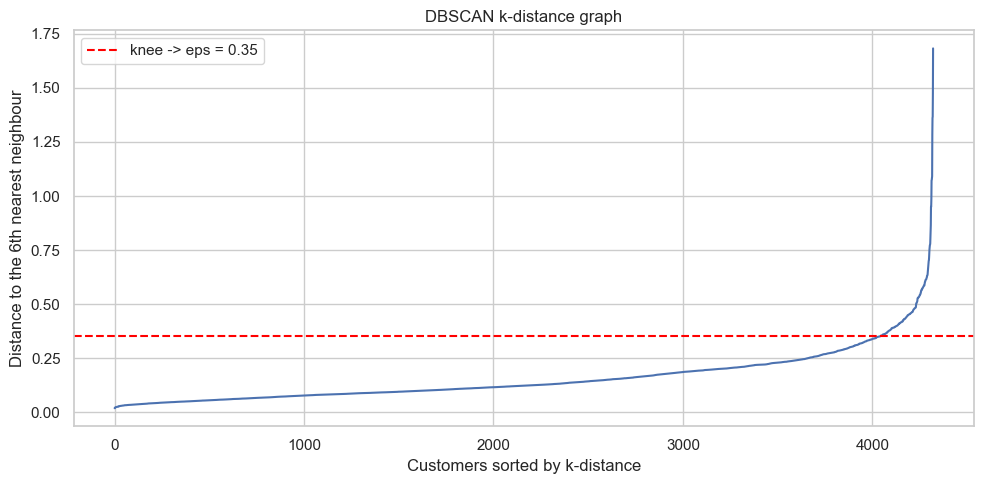

,eps,n_clusters,n_noise,noise_pct
0,0.300,7,263,6.085
1,0.350,4,144,3.332
2,0.500,2,36,0.833
3,0.750,1,8,0.185
4,1.000,1,3,0.069


DBSCAN (eps=0.35): 144 noise customers (3.3%).


In [66]:
MIN_SAMPLES = 2 * CLUSTERING_DATA.shape[1]
nn = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(CLUSTERING_DATA)
dist, _ = nn.kneighbors(CLUSTERING_DATA)
kdist = np.sort(dist[:, MIN_SAMPLES - 1])
EPS_KNEE = float(kdist[find_knee(kdist)])

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(kdist)
ax.axhline(EPS_KNEE, color="red", ls="--", label=f"knee -> eps = {EPS_KNEE:.2f}")
ax.set_xlabel("Customers sorted by k-distance")
ax.set_ylabel(f"Distance to the {MIN_SAMPLES}th nearest neighbour")
ax.set_title("DBSCAN k-distance graph")
ax.legend()
finish_fig(fig, "26_dbscan_kdistance")

rows = []
for eps in sorted({round(EPS_KNEE, 2), 0.3, 0.5, 0.75, 1.0}):
    lab = DBSCAN(eps=eps, min_samples=MIN_SAMPLES).fit_predict(CLUSTERING_DATA)
    rows.append({"eps": eps, "n_clusters": len(set(lab)) - (1 if -1 in lab else 0),
                 "n_noise": int((lab == -1).sum()), "noise_pct": (lab == -1).mean() * 100})
display(pd.DataFrame(rows))

db_labels = DBSCAN(eps=round(EPS_KNEE, 2), min_samples=MIN_SAMPLES).fit_predict(CLUSTERING_DATA)
profile["DBSCAN_Noise"] = db_labels == -1
print(f"DBSCAN (eps={EPS_KNEE:.2f}): {int(profile['DBSCAN_Noise'].sum()):,} noise customers "
      f"({profile['DBSCAN_Noise'].mean() * 100:.1f}%).")


In [67]:
# Who are the "noise" customers in real units? (are they the whales?)
if profile["DBSCAN_Noise"].any():
    cmp_tbl = profile.groupby("DBSCAN_Noise")[["Recency", "Frequency", "Monetary", "AOV"]].median()
    cmp_tbl.index = cmp_tbl.index.map({False: "core customers", True: "DBSCAN noise"})
    display(cmp_tbl)
    noise_rev = profile.loc[profile["DBSCAN_Noise"], "Monetary"].sum() / profile["Monetary"].sum() * 100
    print(f"[Insight] Noise customers hold {noise_rev:.1f}% of modelled net revenue with only "
          f"{profile['DBSCAN_Noise'].mean() * 100:.1f}% of customers.")
    display(profile[profile["DBSCAN_Noise"]].nlargest(10, "Monetary")[["Recency", "Frequency", "Monetary", "AOV", "Return_Rate"]])
else:
    print("DBSCAN found no noise points at this eps.")


,Recency,Frequency,Monetary,AOV
DBSCAN_Noise,,,,
core customers,52.000,2.000,632.045,277.363
DBSCAN noise,22.000,8.000,"6,683.225",655.169


[Insight] Noise customers hold 23.5% of modelled net revenue with only 3.3% of customers.


,Recency,Frequency,Monetary,AOV,Return_Rate
CustomerID,,,,,
17450,9,46,"189,575.530","4,121.207",0.025
12415,25,20,"123,638.180","6,181.909",0.007
14156,10,54,"113,685.770","2,105.292",0.025
17511,3,31,"88,138.200","2,843.168",0.032
16684,5,28,"65,920.120","2,354.290",0.011
16029,39,62,"60,369.930",973.709,0.170
14096,5,17,"53,258.430","3,132.849",0.000
15769,8,26,"51,823.720","1,993.220",0.079
14298,9,44,"50,862.440","1,155.965",0.013


#### 2c — Comparison summary


In [68]:
comparison_table = pd.DataFrame({
    "Algorithm": ["K-Means", "Hierarchical (Ward)", "DBSCAN"],
    "Needs K up front?": ["Yes", "No (read from the tree)", "No (needs eps / min_samples)"],
    "Cluster shape": ["Roughly spherical", "Flexible cuts", "Arbitrary / density-based"],
    "Outliers": ["Pulled into clusters", "Pulled into clusters", "Labelled as noise (-1)"],
    "Cost": ["Low, scalable", "High -> sample used", "Moderate, parameter-sensitive"],
    "Role in this project": ["Final segmentation", "Structure check on a sample", "Whale / anomaly screen"],
})
display(comparison_table)


,Algorithm,Needs K up front?,Cluster shape,Outliers,Cost,Role in this project
0,K-Means,Yes,Roughly spherical,Pulled into clusters,"Low, scalable",Final segmentation
1,Hierarchical (Ward),No (read from the tree),Flexible cuts,Pulled into clusters,High -> sample used,Structure check on a sample
2,DBSCAN,No (needs eps / min_samples),Arbitrary / density-based,Labelled as noise (-1),"Moderate, parameter-sensitive",Whale / anomaly screen


## Step 3 — Elbow method, silhouette width and Davies-Bouldin
K is judged on **three** pieces of evidence, plus cluster size and (later) stability. The elbow is detected algorithmically as the point farthest from the chord of the WCSS curve, so it is reproducible rather than eyeballed.


In [69]:
rows = []
for k in K_EVAL:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10, max_iter=300)
    lab = km.fit_predict(CLUSTERING_DATA)
    rows.append({
        "K": k,
        "WCSS": km.inertia_,
        "Silhouette": silhouette_score(CLUSTERING_DATA, lab),
        "Davies_Bouldin": davies_bouldin_score(CLUSTERING_DATA, lab),
        "smallest_cluster_pct": np.bincount(lab).min() / len(lab) * 100,
    })
evaluation_df = pd.DataFrame(rows)
evaluation_df["Relative_WCSS_Drop"] = -evaluation_df["WCSS"].pct_change()
display(evaluation_df)


,K,WCSS,Silhouette,Davies_Bouldin,smallest_cluster_pct,Relative_WCSS_Drop
0,2,"6,356.210",0.434,0.886,38.478,NaN
1,3,"4,736.437",0.339,1.041,17.908,0.255
2,4,"3,799.123",0.335,1.017,16.844,0.198
3,5,"3,161.431",0.317,0.988,9.278,0.168
4,6,"2,730.970",0.313,1.014,9.255,0.136
5,7,"2,436.541",0.305,0.987,4.998,0.108
6,8,"2,232.490",0.298,1.014,5.090,0.084
7,9,"2,053.654",0.282,1.030,5.067,0.080
8,10,"1,903.620",0.280,1.032,4.859,0.073


## Step 4 — K selection rule
1. **Evidence reported for every K:** WCSS elbow, silhouette (higher is better), Davies-Bouldin (lower is better), smallest-cluster share.
2. **Actionability constraint, fixed in the config before seeing results:** K must lie in the **business range** (4–6). The guideline's translation matrix needs at least four distinct archetypes, and more than six segments cannot be acted on.
3. **Within that range, the K with the highest silhouette wins.** The elbow and Davies-Bouldin are cross-checks.
4. **Transparency:** the unconstrained silhouette winner is also printed together with the silhouette we give up. On RFM data the unconstrained winner is often K=2 (active vs lapsed), which is valid but too coarse for four different marketing actions.


> **Silhouette caveat:** in this dataset the silhouette scores across the business range are close (≈ 0.33–0.34) and all are well below the 0.50 threshold commonly associated with a clear cluster structure. This reflects the fact that RFM values form a continuous distribution rather than naturally separated groups. The Ward dendrogram's largest height gap at K = 2 reinforces that the data splits most cleanly into two broad groups. **K = 4 is therefore a *business decision*** — it produces the four archetypes the guideline's action matrix requires — rather than a statistical discovery. Cluster boundaries should be treated as soft zones, and segment strategies should be validated with controlled experiments before being treated as causal.

Elbow (chord method)               : K=5
Silhouette, unconstrained          : K=2  (silhouette 0.434)
Davies-Bouldin, unconstrained      : K=2
Business range                     : K in [4, 6]
Davies-Bouldin inside the range    : K=5

>>> K_FINAL = 4 (best silhouette inside the business range: 0.335; cost vs unconstrained best: 0.099)
Smallest cluster at K_FINAL        : 16.8% of customers


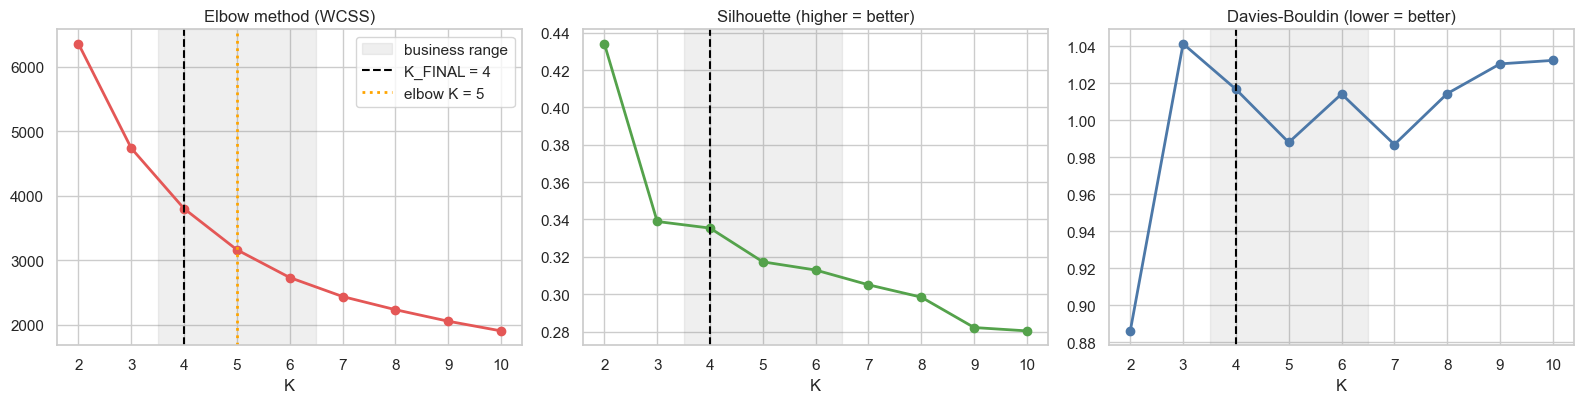

In [70]:
K_elbow = int(evaluation_df["K"].iloc[find_knee(evaluation_df["WCSS"].values)])
K_sil_any = int(evaluation_df.loc[evaluation_df["Silhouette"].idxmax(), "K"])
K_db_any = int(evaluation_df.loc[evaluation_df["Davies_Bouldin"].idxmin(), "K"])

lo, hi = K_BUSINESS_RANGE
in_range = evaluation_df[evaluation_df["K"].between(lo, hi)]
K_FINAL = int(in_range.loc[in_range["Silhouette"].idxmax(), "K"])
K_db_range = int(in_range.loc[in_range["Davies_Bouldin"].idxmin(), "K"])

sil_final = float(evaluation_df.loc[evaluation_df["K"] == K_FINAL, "Silhouette"].iloc[0])
sil_any = float(evaluation_df["Silhouette"].max())
small_pct = float(evaluation_df.loc[evaluation_df["K"] == K_FINAL, "smallest_cluster_pct"].iloc[0])

print(f"Elbow (chord method)               : K={K_elbow}")
print(f"Silhouette, unconstrained          : K={K_sil_any}  (silhouette {sil_any:.3f})")
print(f"Davies-Bouldin, unconstrained      : K={K_db_any}")
print(f"Business range                     : K in [{lo}, {hi}]")
print(f"Davies-Bouldin inside the range    : K={K_db_range}")
print(f"\n>>> K_FINAL = {K_FINAL} (best silhouette inside the business range: {sil_final:.3f}; "
      f"cost vs unconstrained best: {sil_any - sil_final:.3f})")
print(f"Smallest cluster at K_FINAL        : {small_pct:.1f}% of customers")
if small_pct < 1:
    print("NOTE: a cluster below 1% of customers is tiny - check in the profile whether it is a whale group or noise.")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, (col, color, title) in zip(axes, [("WCSS", "#E45756", "Elbow method (WCSS)"),
                                          ("Silhouette", "#54A24B", "Silhouette (higher = better)"),
                                          ("Davies_Bouldin", "#4C78A8", "Davies-Bouldin (lower = better)")]):
    ax.plot(evaluation_df["K"], evaluation_df[col], "o-", color=color, lw=2)
    ax.axvspan(lo - 0.5, hi + 0.5, color="grey", alpha=0.12, label="business range")
    ax.axvline(K_FINAL, color="black", ls="--", label=f"K_FINAL = {K_FINAL}")
    ax.set_xlabel("K")
    ax.set_title(title)
axes[0].axvline(K_elbow, color="orange", ls=":", lw=2, label=f"elbow K = {K_elbow}")
axes[0].legend()
finish_fig(fig, "30_clustering_metrics")


## Step 5 — Final K-Means fit, stability and cross-algorithm agreement
Cluster IDs are re-ordered by **median Monetary (descending)** so that cluster 0 is always the highest-spending group, which makes every table easier to read. A segmentation is only defensible if it survives different random starts and different subsamples, so both are tested with the Adjusted Rand Index (ARI; 1 = identical partitions, 0 = random).


> **Stability note:** the K-Means vs Hierarchical agreement (ARI) is printed at the end of the code cell below. Because the hierarchical model runs on a sample and the two algorithms have different assumptions, an ARI of around 0.40 is expected and does not invalidate the K-Means solution — it confirms that the two methods produce *related but not identical* partitions, which is consistent with soft cluster boundaries on a continuous RFM space. The random-start and subsample ARIs are the primary stability indicators.

In [71]:
kmeans_final = KMeans(n_clusters=K_FINAL, random_state=RANDOM_STATE, n_init=10, max_iter=300)
raw_labels = kmeans_final.fit_predict(CLUSTERING_DATA)
order = pd.Series(profile["Monetary"].values).groupby(raw_labels).median().sort_values(ascending=False).index
remap = {old: new for new, old in enumerate(order)}
profile["Cluster"] = pd.Series(raw_labels, index=profile.index).map(remap)
ref = profile["Cluster"].values

print(f"K-Means fitted with K={K_FINAL}. Cluster sizes (0 = highest median spend):")
print(profile["Cluster"].value_counts().sort_index().to_string())

# Stability 1: different random starts
seed_ari = [adjusted_rand_score(ref, KMeans(n_clusters=K_FINAL, random_state=1000 + s, n_init=10).fit_predict(CLUSTERING_DATA))
            for s in range(STABILITY_RUNS)]
# Stability 2: fit on 80% of customers, then assign everyone
rng = np.random.RandomState(RANDOM_STATE)
boot_ari = []
for s in range(STABILITY_RUNS):
    idx = rng.choice(len(CLUSTERING_DATA), size=int(0.8 * len(CLUSTERING_DATA)), replace=False)
    km = KMeans(n_clusters=K_FINAL, random_state=2000 + s, n_init=10).fit(CLUSTERING_DATA.iloc[idx])
    boot_ari.append(adjusted_rand_score(ref, km.predict(CLUSTERING_DATA)))

# Agreement with the hierarchical tree (on the sample)
hier_labels = fcluster(Z, K_FINAL, criterion="maxclust") - 1
ari_hier = adjusted_rand_score(profile.loc[hier_sample_ids, "Cluster"].values, hier_labels)

print(f"\nStability across random starts  : mean ARI {np.mean(seed_ari):.3f} (min {np.min(seed_ari):.3f})")
print(f"Stability across 80% subsamples : mean ARI {np.mean(boot_ari):.3f} (min {np.min(boot_ari):.3f})")
print(f"Agreement K-Means vs hierarchical (sample, K={K_FINAL}): ARI {ari_hier:.3f}")
verdict = "STABLE (ARI >= 0.80)" if min(np.mean(seed_ari), np.mean(boot_ari)) >= 0.80 else "ONLY MODERATELY STABLE (ARI < 0.80) - treat segment boundaries as soft"
print(f"Verdict: segmentation is {verdict}.")


K-Means fitted with K=4. Cluster sizes (0 = highest median spend):
Cluster
0     728
1    1182
2     882
3    1530

Stability across random starts  : mean ARI 1.000 (min 0.999)
Stability across 80% subsamples : mean ARI 0.930 (min 0.793)
Agreement K-Means vs hierarchical (sample, K=4): ARI 0.420
Verdict: segmentation is STABLE (ARI >= 0.80).


## Step 6 — Segment profiling (real £, days and orders)
Segments are described in **original units**, not in scaled units: median and mean recency / frequency / spend, order value, return rate, UK share and tenure, plus each segment's share of customers and of revenue. Medians are shown next to means because the distributions are skewed.


In [72]:
seg = profile.groupby("Cluster").agg(
    n_customers=("Monetary", "size"),
    Recency_median=("Recency", "median"), Recency_mean=("Recency", "mean"),
    Frequency_median=("Frequency", "median"), Frequency_mean=("Frequency", "mean"),
    Monetary_median=("Monetary", "median"), Monetary_mean=("Monetary", "mean"), total_revenue=("Monetary", "sum"),
    AOV_median=("AOV", "median"),
    Return_Rate_mean=("Return_Rate", "mean"),
    UK_share=("Is_UK", "mean"),
    Tenure_median=("TenureDays", "median"),
)
seg["pct_customers"] = seg["n_customers"] / seg["n_customers"].sum() * 100
seg["pct_revenue"] = seg["total_revenue"] / seg["total_revenue"].sum() * 100
display(seg.round(2))


,n_customers,Recency_median,Recency_mean,Frequency_median,Frequency_mean,Monetary_median,Monetary_mean,total_revenue,AOV_median,Return_Rate_mean,UK_share,Tenure_median,pct_customers,pct_revenue
Cluster,,,,,,,,,,,,,,
0,728,9.000,12.310,10.000,13.450,"3,480.800","7,393.100","5,382,173.180",356.150,0.020,0.900,355.500,16.840,65.080
1,1182,53.000,66.980,4.000,4.120,"1,303.970","1,648.290","1,948,280.530",343.430,0.020,0.890,278.000,27.350,23.560
2,882,20.000,22.480,2.000,1.920,399.140,467.830,"412,630.010",216.130,0.010,0.910,52.000,20.410,4.990
3,1530,187.000,192.410,1.000,1.330,291.020,344.150,"526,553.600",218.620,0.020,0.910,234.000,35.400,6.370


## Step 7 — RFM score cross-check
Each cluster is mapped back to the 1–5 quantile scores from Phase 2 (R: 5 = most recent, F and M: 5 = highest). The mean scores per cluster are what the naming rules in Step 8 use, so segment names are tied to the scoring scheme the guideline defines.


In [73]:
rfm_by_cluster = profile.groupby("Cluster")[["R_score", "F_score", "M_score", "RFM_Total"]].mean()
rfm_by_cluster.columns = ["R_score_mean", "F_score_mean", "M_score_mean", "RFM_Total_mean"]
seg = seg.join(rfm_by_cluster)
display(seg[["n_customers", "pct_customers", "pct_revenue", "R_score_mean", "F_score_mean", "M_score_mean", "RFM_Total_mean"]].round(2))


,n_customers,pct_customers,pct_revenue,R_score_mean,F_score_mean,M_score_mean,RFM_Total_mean
Cluster,,,,,,,
0,728,16.840,65.080,4.650,4.870,4.780,14.300
1,1182,27.350,23.560,2.970,3.800,3.970,10.730
2,882,20.410,4.990,4.100,2.430,2.250,8.780
3,1530,35.400,6.370,1.610,1.820,1.840,5.270


## Step 8 — Business translation: naming segments from measured profiles
A cluster gets a label **only when its measured mean R/F/M scores support it**. The rules follow the guideline's translation matrix, with "high" and "low" defined on the 1–5 score scale (high ≥ 3.5, low ≤ 2.5):

| Name | Rule on the cluster's mean scores |
|---|---|
| Champions | R ≥ 4, F ≥ 4, M ≥ 4 |
| Loyal Customers | R, F, M all ≥ 3.5 (and not Champions) |
| At-Risk / High-Value Churn | R ≤ 2.5 with F ≥ 3 and M ≥ 3 |
| New Inflow | R ≥ 3.5 with F ≤ 2.5 and M ≤ 2.5 |
| Hibernating / Lost | R, F, M all ≤ 2.5 |
| Big Spenders, Infrequent | M ≥ 3.5 with F ≤ 2.5 |
| *anything else* | a **descriptive** label built from the measured levels (e.g. `Developing (R:Mid F:Mid M:High)`) instead of forcing a standard label |

If two clusters earn the same name, the cluster number is appended so that every segment stays distinguishable. No cluster is called "VIP" or "bad" without the numbers printed next to it.


In [74]:
def lvl(x, high=3.5, low=2.5):
    return "High" if x >= high else ("Low" if x <= low else "Mid")


def name_segment(r, f, m):
    rl, fl, ml = lvl(r), lvl(f), lvl(m)
    if r >= 4 and f >= 4 and m >= 4:
        return "Champions"
    if r >= 3.5 and f >= 3.5 and m >= 3.5:
        return "Loyal Customers"
    if r <= 2.5 and f >= 3 and m >= 3:
        return "At-Risk / High-Value Churn"
    if r >= 3.5 and f <= 2.5 and m <= 2.5:
        return "New Inflow"
    if r <= 2.5 and f <= 2.5 and m <= 2.5:
        return "Hibernating / Lost"
    if m >= 3.5 and f <= 2.5:
        return "Big Spenders, Infrequent"
    return f"Developing (R:{rl} F:{fl} M:{ml})"


seg["R_level"] = seg["R_score_mean"].map(lvl)
seg["F_level"] = seg["F_score_mean"].map(lvl)
seg["M_level"] = seg["M_score_mean"].map(lvl)
seg["BaseName"] = [name_segment(r, f, m) for r, f, m in zip(seg["R_score_mean"], seg["F_score_mean"], seg["M_score_mean"])]

dup = seg["BaseName"].duplicated(keep=False)
seg["SegmentName"] = [f"{n} (C{c})" if d else n for c, n, d in zip(seg.index, seg["BaseName"], dup)]
profile["SegmentName"] = profile["Cluster"].map(seg["SegmentName"])

order_names = seg.sort_index()["SegmentName"].tolist()
palette = dict(zip(order_names, sns.color_palette("Set2", len(order_names))))

print("Segment names and the evidence behind them:")
display(seg[["SegmentName", "n_customers", "pct_customers", "pct_revenue", "Recency_median", "Frequency_median",
             "Monetary_median", "R_score_mean", "F_score_mean", "M_score_mean"]].round(2))


Segment names and the evidence behind them:


,SegmentName,n_customers,pct_customers,pct_revenue,Recency_median,Frequency_median,Monetary_median,R_score_mean,F_score_mean,M_score_mean
Cluster,,,,,,,,,,
0,Champions,728,16.840,65.080,9.000,10.000,"3,480.800",4.650,4.870,4.780
1,Developing (R:Mid F:High M:High),1182,27.350,23.560,53.000,4.000,"1,303.970",2.970,3.800,3.970
2,New Inflow,882,20.410,4.990,20.000,2.000,399.140,4.100,2.430,2.250
3,Hibernating / Lost,1530,35.400,6.370,187.000,1.000,291.020,1.610,1.820,1.840


## Step 9 — Segment visualisations
Every chart answers one question: *how big is each segment and how much revenue does it carry*, *where do segments sit on recency and frequency*, *how does spend differ*, *how do segments look in the PCA plane*, and *what defines each segment in standardised terms*.


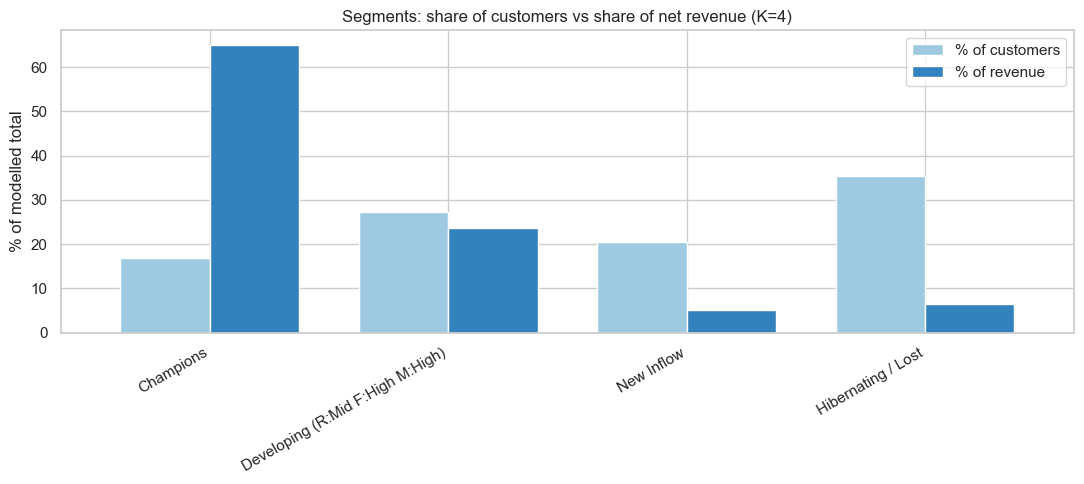

[Insight] Largest revenue share: 'Champions' = 65.1% of revenue from 16.8% of customers.


In [75]:
# Share of customers vs share of revenue: the clearest way to show where value sits
share = seg.sort_index().set_index("SegmentName")[["pct_customers", "pct_revenue"]]
ax = share.plot(kind="bar", figsize=(11, 5), color=["#9ecae1", "#3182bd"], width=0.75)
ax.set_ylabel("% of modelled total")
ax.set_xlabel("")
ax.set_title(f"Segments: share of customers vs share of net revenue (K={K_FINAL})")
ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha="right")
ax.legend(["% of customers", "% of revenue"])
finish_fig(ax.get_figure(), "31_segment_share")

top_seg = seg["pct_revenue"].idxmax()
print(f"[Insight] Largest revenue share: '{seg.loc[top_seg, 'SegmentName']}' = {seg.loc[top_seg, 'pct_revenue']:.1f}% of revenue "
      f"from {seg.loc[top_seg, 'pct_customers']:.1f}% of customers.")


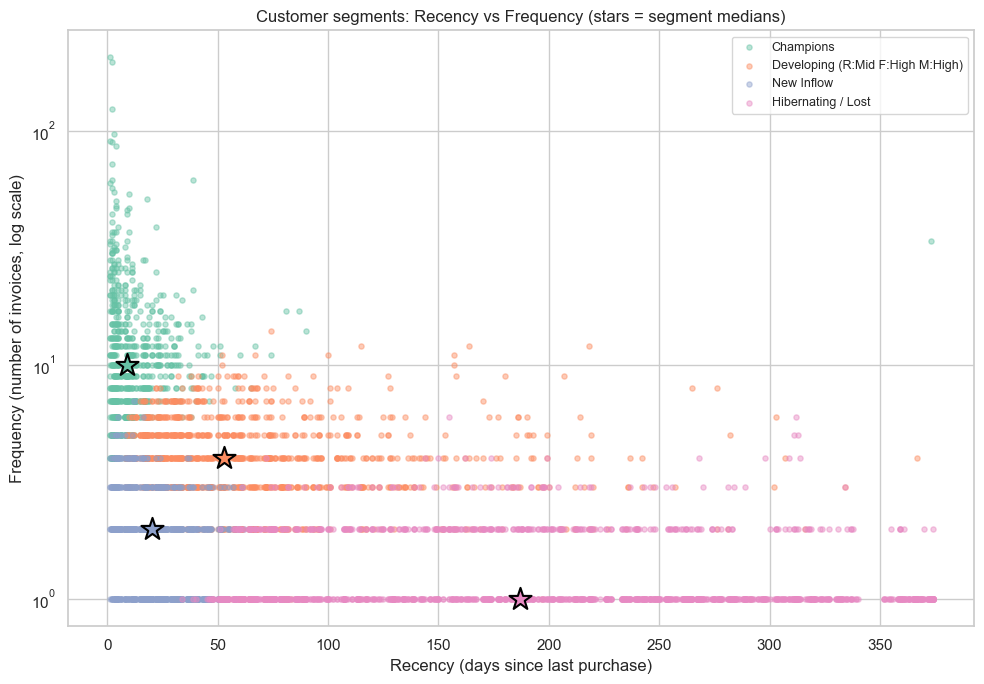

In [76]:
# Recency vs Frequency by segment (log frequency axis; stars = segment medians)
fig, ax = plt.subplots(figsize=(10, 7))
for name in order_names:
    m = profile["SegmentName"] == name
    ax.scatter(profile.loc[m, "Recency"], profile.loc[m, "Frequency"], s=14, alpha=0.45, color=palette[name], label=name)
    ax.scatter(profile.loc[m, "Recency"].median(), profile.loc[m, "Frequency"].median(), s=280, marker="*",
               edgecolor="black", linewidth=1.5, color=palette[name], zorder=5)
ax.set_yscale("log")
ax.set_xlabel("Recency (days since last purchase)")
ax.set_ylabel("Frequency (number of invoices, log scale)")
ax.set_title("Customer segments: Recency vs Frequency (stars = segment medians)")
ax.legend(loc="upper right", fontsize=9)
finish_fig(fig, "32_scatter_rf_segments")


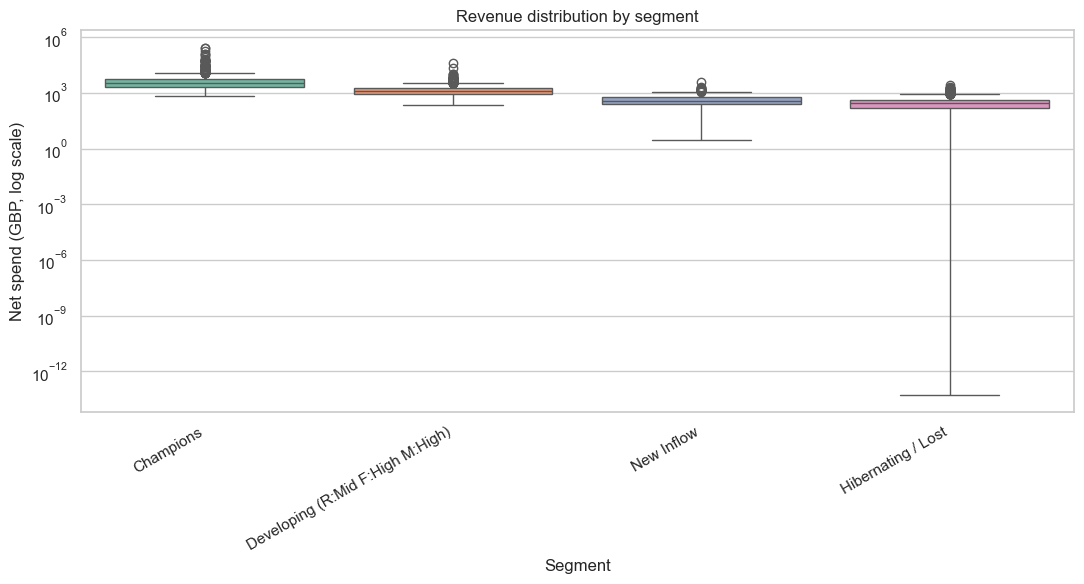

In [77]:
# Spend distribution by segment (log scale because spend is heavily right-skewed)
fig, ax = plt.subplots(figsize=(11, 6))
sns.boxplot(data=profile, x="SegmentName", y="Monetary", order=order_names, palette=palette, ax=ax)
ax.set_yscale("log")
ax.set_xlabel("Segment")
ax.set_ylabel("Net spend (GBP, log scale)")
ax.set_title("Revenue distribution by segment")
ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha="right")
finish_fig(fig, "33_boxplot_revenue")


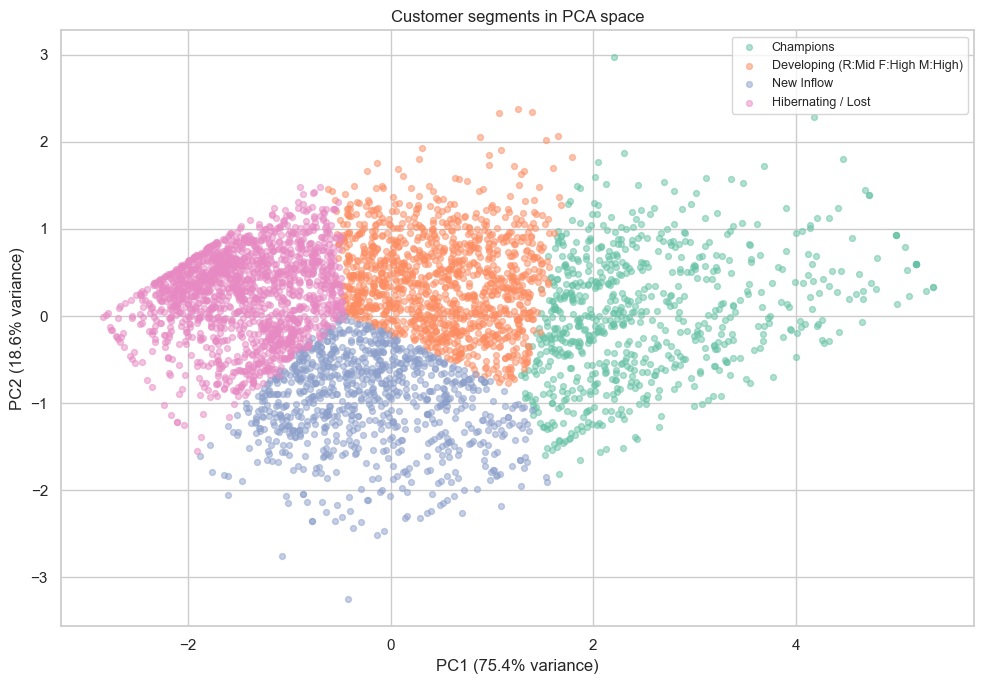

In [78]:
# Segments in PCA space (PCA used for visualisation only; clustering ran on the full standardised R/F/M)
fig, ax = plt.subplots(figsize=(10, 7))
for name in order_names:
    m = profile["SegmentName"] == name
    ax.scatter(rfm_pca.loc[m, "PC1"], rfm_pca.loc[m, "PC2"], s=18, alpha=0.5, color=palette[name], label=name)
ax.set_xlabel(f"PC1 ({PCA_EVR[0]:.1%} variance)")
ax.set_ylabel(f"PC2 ({PCA_EVR[1]:.1%} variance)")
ax.set_title("Customer segments in PCA space")
ax.legend(loc="best", fontsize=9)
finish_fig(fig, "34_pca_clusters")


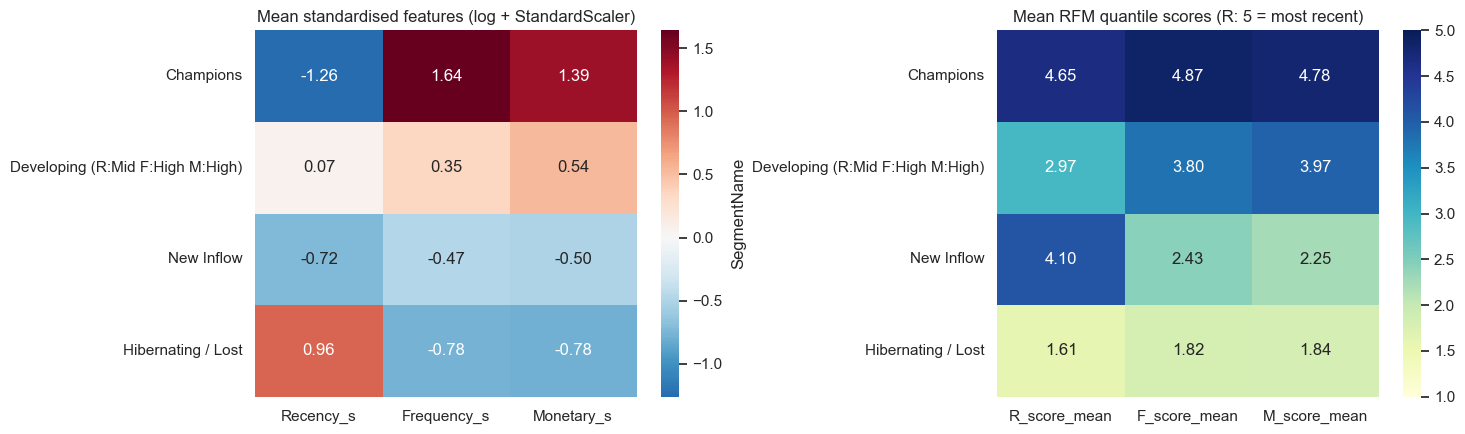

In [79]:
# What defines each segment? Mean standardised R/F/M (left) and mean 1-5 RFM scores (right)
cent = pd.DataFrame(CLUSTERING_DATA.values, index=profile.index, columns=CLUSTERING_DATA.columns).groupby(profile["Cluster"]).mean()
cent.index = [seg.loc[c, "SegmentName"] for c in cent.index]
scores_tbl = seg.sort_index().set_index("SegmentName")[["R_score_mean", "F_score_mean", "M_score_mean"]]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.heatmap(cent, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=axes[0])
axes[0].set_title("Mean standardised features (log + StandardScaler)")
sns.heatmap(scores_tbl, annot=True, fmt=".2f", cmap="YlGnBu", vmin=1, vmax=5, ax=axes[1])
axes[1].set_title("Mean RFM quantile scores (R: 5 = most recent)")
finish_fig(fig, "35_segment_heatmaps")


## Business Recommendations
The playbook below follows the guideline's translation matrix. It is **generated from the measured segments**: each row shows the segment's size, revenue share and median R/F/M next to the recommended action, so every recommendation is backed by numbers. Segments that do not match a standard archetype get an action derived from their measured levels, not a forced label.

**Important:** these are *descriptive* segments. The actions are hypotheses to be validated with controlled experiments, not proven causal effects.


> **Priority note — Developing (R:Mid F:High M:High) segment:** this segment deserves specific attention beyond the generic fallback strategy. Customers here have a strong purchase history (high Frequency and Monetary) but their Recency is drifting (median ≈ 53 days). They are the highest-priority retention target: historically valuable accounts that are beginning to cool. Recommended actions: (1) trigger a personalised re-engagement email within 7 days featuring their most-purchased categories; (2) offer a time-limited loyalty incentive (e.g. free shipping on the next order) rather than a blanket discount; (3) assign to a KAM review if their net spend exceeds the segment median. Validate impact against a holdout group before scaling.

In [80]:
PLAYBOOK = {
    "Champions": "REWARD - loyalty perks, early access to new lines and a referral programme; avoid blanket discounting.",
    "Loyal Customers": "GROW - cross-sell related catalogue segments and bundles; watch Recency for early churn signals.",
    "At-Risk / High-Value Churn": "WIN BACK - immediate direct win-back email or promotional trigger; check historic value and return behaviour before choosing the incentive.",
    "New Inflow": "ONBOARD - welcome sequence with an incentive for the second purchase; track first-to-second-order conversion.",
    "Hibernating / Lost": "LOW-COST REACTIVATION - one inexpensive email, otherwise suppress from paid campaigns.",
    "Big Spenders, Infrequent": "NUDGE RE-ORDER - replenishment reminders and account-style outreach; large baskets but low cadence.",
}


def fallback_action(rl, fl, ml):
    parts = []
    parts.append({"High": "Recently active: keep engaged and encourage a further purchase",
                  "Mid": "Moderately recent: a timely reminder campaign",
                  "Low": "Lapsed: test a re-activation offer against a holdout"}[rl])
    parts.append({"High": "frequent buyers: reward the habit", "Mid": "average cadence: build the habit with bundles",
                  "Low": "infrequent: prompt the next order"}[fl])
    parts.append({"High": "high spend: prioritise", "Mid": "mid spend: grow basket size", "Low": "low spend: keep cost-to-serve low"}[ml])
    return "; ".join(parts) + "."


reco = seg.sort_index().copy()
reco["Strategy"] = [PLAYBOOK.get(b, fallback_action(rl, fl, ml))
                    for b, rl, fl, ml in zip(reco["BaseName"], reco["R_level"], reco["F_level"], reco["M_level"])]
reco_view = reco[["SegmentName", "n_customers", "pct_customers", "pct_revenue", "Recency_median",
                  "Frequency_median", "Monetary_median", "Strategy"]].reset_index(drop=True)
with pd.option_context("display.max_colwidth", 140):
    display(reco_view.round(2))

overall_ret = profile["Return_Rate"].mean()
flag = reco[reco["Return_Rate_mean"] >= 2 * overall_ret]
print(f"\nOverall mean return ratio: {overall_ret:.3f}")
if len(flag):
    for _, r in flag.iterrows():
        print(f"[Data-quality flag] '{r['SegmentName']}' has a mean return ratio of {r['Return_Rate_mean']:.3f} "
              f"(>= 2x overall): investigate returns before treating it as simply 'high value'.")
else:
    print("No segment has a return ratio above twice the overall average.")


,SegmentName,n_customers,pct_customers,pct_revenue,Recency_median,Frequency_median,Monetary_median,Strategy
0,Champions,728,16.840,65.080,9.000,10.000,"3,480.800","REWARD - loyalty perks, early access to new lines and a referral programme; avoid blanket discounting."
1,Developing (R:Mid F:High M:High),1182,27.350,23.560,53.000,4.000,"1,303.970",Moderately recent: a timely reminder campaign; frequent buyers: reward the habit; high spend: prioritise.
2,New Inflow,882,20.410,4.990,20.000,2.000,399.140,ONBOARD - welcome sequence with an incentive for the second purchase; track first-to-second-order conversion.
3,Hibernating / Lost,1530,35.400,6.370,187.000,1.000,291.020,"LOW-COST REACTIVATION - one inexpensive email, otherwise suppress from paid campaigns."



Overall mean return ratio: 0.018
No segment has a return ratio above twice the overall average.


### Playbook reference (guideline translation matrix)
* **Champions** (high R, F, M) - reward with loyalty perks, exclusive early access and referral programmes.
* **Loyal Customers** - maximise revenue through cross-selling related product segments.
* **At-Risk / High-Value Churn** (low R, high F and M) - direct win-back offers; review return behaviour first.
* **New Inflow** (high R, low F and M) - onboarding / welcome sequences to trigger the second purchase.
* **Other segments** - actions come from the measured profile above; re-check their stability across snapshots and preprocessing choices before investing.


## Export
Customer-level segment assignments and the segment summary are written to disk so they can feed the final report and CRM tooling.


In [81]:
REPORT_DIR.mkdir(parents=True, exist_ok=True)
export_cols = ["Recency", "Frequency", "Monetary", "R_score", "F_score", "M_score", "RFM_Score",
               "Cluster", "SegmentName", "AOV", "Return_Rate", "DBSCAN_Noise"]
profile[export_cols].to_csv(RFM_DIR / "customer_segments.csv")
reco_view.to_csv(REPORT_DIR / "segment_summary.csv", index=False)
print("Saved:", RFM_DIR / "customer_segments.csv", "|", REPORT_DIR / "segment_summary.csv")
print(f"\nFinal setup: K={K_FINAL} | scaler={SCALER_NAME} | transforms={meta['transforms']} | "
      f"monetary basis={meta['monetary_basis']} | snapshot={meta['snapshot']} | customers={len(profile):,}")


Saved: d:\NTI\NTI 2026\17\project\final\data\processed\rfm\customer_segments.csv | d:\NTI\NTI 2026\17\project\final\reports\segment_summary.csv

Final setup: K=4 | scaler=StandardScaler | transforms={'Recency': 'log1p', 'Frequency': 'log1p', 'Monetary': 'log1p'} | monetary basis=net | snapshot=2011-12-10 | customers=4,322


## Limitations & Next Steps

### Limitations
1. **Snapshot bias:** RFM is computed at one dataset-derived snapshot; there is no customer history before the first transaction.
2. **Return matching is approximate:** returns are matched to the most recent earlier sale of the same customer and product; complex partial-return sequences can stay ambiguous, and guest returns cannot be matched at all.
3. **K was constrained to a business range (4-6):** this trades some statistical separation (the unconstrained silhouette optimum is reported in Step 4) for segments a marketing team can act on.
4. **K-Means assumptions:** centroid- and distance-based, roughly spherical clusters. Hierarchical clustering ran on a sample and DBSCAN is used only as an outlier screen.
5. **Log transform on Recency:** required by the guideline for all three dimensions; it can leave Recency mildly left-skewed. The skew table in Phase 2 quantifies it.
6. **Only R/F/M are clustered:** product mix, seasonality and discount sensitivity are used for interpretation, not for clustering.
7. **Naming thresholds are a judgement call:** high >= 3.5 and low <= 2.5 on the 1-5 score scale; different thresholds can relabel borderline clusters.
8. **Descriptive analysis:** nothing here establishes causal effects, and segments are static: customers migrate over time.
9. **Single-period seasonality:** the data covers about one annual cycle.

### Next steps
1. Re-run under alternative Monetary definitions (gross vs net) and outlier caps to test segment stability.
2. Build repeated monthly or quarterly RFM snapshots to measure segment migration.
3. Add product / category mix, AOV and seasonality features if a richer segmentation is needed.
4. Validate segment-specific campaigns with controlled experiments before attributing any revenue lift to a segment strategy.


## Final Conclusion
The analysis follows one story: **business understanding → trustworthy transaction data → EDA → customer-level RFM → quantile scoring → log transform and standardisation → clustering comparison → segment profiling → business actions.**

What the code enforces (assertions, not promises):
* One invoice belongs to exactly one customer; Frequency counts unique invoices, never rows; cancellations never count as purchases.
* RFM scores are integers 1-5, Recency is inverted (5 = most recent), and the combined score is a three-digit string.
* `CustomerID` is only ever an index; the clustering matrix is log-transformed and standardised (mean 0, variance 1).
* No customer is deleted as an outlier; the extreme ones stay identifiable and are profiled in Step 2b.
* Segment names come from measured profiles, with a descriptive fallback instead of a forced label.

What to check in the printed results before presenting: the stability ARI (Step 5), the silhouette given up by constraining K (Step 4), each segment's share of revenue (Step 6), and the return-ratio flags (Business Recommendations).

### Guideline coverage
| Guideline section | Where |
|---|---|
| Business Understanding | Phase 1 (top) |
| Dataset Loading & Documentation | Phase 1 §2 |
| Data Audit | Phase 1 §3 |
| Cleaning & Data Quality Decisions | Phase 1 §4-5 |
| Feature Engineering | Phase 1 §5 |
| EDA (sales, products, customers, time, geography, baskets, returns) | Phase 1 §6-12D |
| Business Insights (10+) | Phase 1 §14 |
| Customer-Level Feature Engineering | Phase 2 Step 3 / 3B |
| RFM Analysis | Phase 2 Step 4A-4B |
| RFM Visualisation & Interpretation | Phase 2 Step 4C |
| Preprocessing for Clustering | Phase 2 Steps 5-8 and Phase 3 Step 1 |
| Clustering & Evaluation | Phase 3 Steps 2-5 |
| Segment Profiling | Phase 3 Steps 6-9 |
| Business Recommendations | Phase 3 |
| Limitations & Next Steps | Phase 3 |
| Final Conclusion | this section |
